# FiLM inside YOLO11n, YOLO11m, and DETR

**Question:** does conditioning detector features on predicted fog density improve detection on foggy images, and how does it affect clear images?

Train six comparisons: each detector **without FiLM** and **with FiLM**. Both arms start from identical pretrained detector weights and use the same clear/fog training images, seed, data order, and budget. The no-FiLM arm is the unmodified detector; the FiLM arm adds a density-conditioned feature layer. A frozen density model supplies beta; ground-truth beta is used only to group evaluation images.

For YOLO11n and YOLO11m, FiLM modifies the final backbone C2PSA output before the neck. For DETR, FiLM modifies the projected backbone feature map before the transformer. The layer learns channel-wise scale and shift: `features * (1 + scale(beta)) + shift(beta)`, initialized to the identity. This replaces the baseline notebook's RGB residual adapter in this extension.

Compare overall mAP and **per-class AP@[.50:.95], AP50, AP75, recall, precision, and F1** on matched clear and foggy Cityscapes scenes, including individual fog levels. Review FiLM-minus-no-FiLM differences, latency including density inference, parameters, GPU memory, loss, and data coverage. nuScenes images without measured beta remain an unknown-weather group.

Run the numbered steps in order. `setup` is a smoke check, not a scientific result. Outputs are isolated under `models/film/<profile>/` locally or `/content/drive/MyDrive/models/film/<profile>/` on Drive. The original `fog_density_study.ipynb` remains the baseline study.


## 1. Configure the FiLM experiment

Choose the profile, storage location, models, and seed below. Shared inputs stay under `data/fog-study/` locally or `/content/drive/MyDrive/fog-study/` on Drive. Only this extension's model artifacts are stored under `models/film/<profile>/`.

All three detectors run with and without FiLM. Both arms train on the same mixture of nuScenes, labeled foggy Cityscapes, and matched clear Cityscapes. After ordinary evaluation, the matched comparison evaluates saved best weights on complete clear/light/moderate/dense scene groups without retraining. Partial profiles use validation scenes; only the full profile uses the final test split.


In [44]:
# fmt: off
#@title Fixed study contracts and small run profile
# fmt: on
from copy import deepcopy
from pathlib import Path
import os
import subprocess
import sys

# 1. One explicit seed keeps every run reproducible.
RUN_SEED = 42

# 2. Detector and comparison contracts: change only when the study design changes.
YOLO_SMALL, YOLO_MEDIUM, DETR_MODEL = "YOLO11n", "YOLO11m", "DETR"
MODEL_SPECS = {
    YOLO_SMALL: "yolo11n.pt",
    YOLO_MEDIUM: "yolo11m.pt",
    DETR_MODEL: "facebook/detr-resnet-50",
}
WITHOUT_FILM, WITH_FILM, KNOWN_FOG_DENSITY = (
    "without_film",
    "with_film",
    "known_fog_density",
)
DETECTOR_CONDITIONS = [WITHOUT_FILM, WITH_FILM]

# 3. Profile names and output locations.
PROFILE_SETUP, PROFILE_2K, PROFILE_5K, PROFILE_FULL = (
    "setup",
    "partial-2k",
    "partial-5k",
    "full",
)
EXPERIMENT_NAME = "film"
DENSITY_MODEL_DIRECTORY = "fog-density"
DATA_FOLDER = "fog-study"
DRIVE_MOUNT, DRIVE_SUBDIRECTORY = "/content/drive", "MyDrive"
DATA_ARCHIVE = "fog-colab-data.zip"
CITYSCAPES_ARCHIVE = "Cityscape-Dataset.zip"
DATA_ARCHIVE_URL = (
    "https://drive.google.com/uc?export=download&id=14fNOg5ysWcZyll6oW3Nr28ROmFnWSexU"
)

# 4. Dataset and metric contracts.
MANIFEST_PATHS = {
    "manifest": "data/fog/nuscenes_all.json",
    "city_manifest": "data/fog/cityscapes.json",
}
CLASSES = ["person", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
COCO_IDS, YOLO_IDS = [1, 3, 8, 6, 7, 4, 2], [0, 2, 7, 5, 6, 3, 1]
BETA_SCALE = 0.02
DENSITY_INPUT_SIZE = 128
FILM_CONTRACT = {
    "version": 1,
    "kind": "detector_feature_affine",
    "density_source": "frozen_predicted_beta",
    "beta_scale": BETA_SCALE,
    "hidden_features": 32,
    "identity_initialization": True,
    "sites": {
        YOLO_SMALL: "model.10",
        YOLO_MEDIUM: "model.10",
        DETR_MODEL: "model.input_projection",
    },
}
DENSITY_BIN_NAMES = ("clear", "light", "moderate", "dense")
DENSITY_BIN_UPPER_BOUNDS = (0.0, 0.005, 0.01, BETA_SCALE)

# 5. Files that preserve training state; findings stay in notebook outputs.
BEST_CHECKPOINT, LAST_CHECKPOINT = "best.pt", "last.pt"
RUN_SETTINGS_FILE, INPUT_MANIFEST_FILE = "settings.json", "input-manifest.json"
PROGRESS_FILE, LOSS_HISTORY_FILE = "progress.json", "history.csv"
STATUS_FILE = "status.json"
MODEL_EXPORT_FILE, RUN_LOCK_FILE = (
    "trained-model.pt",
    "run.lock",
)

# 6. Base training settings. Profiles below override only data scope and epochs.
TRAINING_DEFAULTS = {
    "density_epochs": 15,
    "density_checkpoint": None,
    "density_sampling": "natural",
    "batch_size": 1,
    "effective_batch_size": 4,
    "accumulate": 4,
    "amp_initial_scale": 1024.0,
    "amp_max_retries": 8,
    "loader": {"num_workers": 0, "prefetch_factor": None, "pin_memory": False},
    "repeats": 1,
    "learning_rates": {YOLO_SMALL: 1e-4, YOLO_MEDIUM: 1e-4, DETR_MODEL: 1e-5},
    "adapter_lr": 1e-3,
}

# 7. Profiles: setup is a smoke check; partial profiles limit images; full uses all.
BASE_PROFILE = {
    "seed": RUN_SEED,
    "models": list(MODEL_SPECS),
    "epochs": 5,
    "training_image_cap": None,
    "validation_image_cap": None,
    "size": 640,
    "save_every": 200,
    "evaluation_split": "val",
    "early_stopping_patience": 0,
}
PROFILE_OVERRIDES = {
    PROFILE_SETUP: {
        "epochs": 1,
        "density_epochs": 1,
        "training_image_cap": 48,
        "validation_image_cap": 24,
        "size": 320,
        "save_every": 2,
    },
    PROFILE_2K: {"training_image_cap": 2000},
    PROFILE_5K: {"training_image_cap": 5000},
    PROFILE_FULL: {"epochs": 30, "evaluation_split": "test"},
}
PROFILE_SETTINGS = {
    name: {**BASE_PROFILE, **overrides} for name, overrides in PROFILE_OVERRIDES.items()
}


### Run settings

Choose the small run settings below. Profile defaults are fixed above; the predictor checkpoint is loaded by the **Load the fog-density model** step and then frozen.

In [45]:
# Configure the run here. Shared data stays in data/; FiLM artifacts use models/film/.
RUN_PROFILE = PROFILE_5K  # PROFILE_SETUP PROFILE_2K PROFILE_5K PROFILE_FULL
RUN_STORAGE = "local"  # "drive" or "local"
working_directory = Path.cwd().resolve()
project_directory = next(
    (
        directory
        for directory in (working_directory, *working_directory.parents)
        if (directory / "notebooks" / "fog_density_study.ipynb").is_file()
    ),
    working_directory,
)
local_data_directory = project_directory / "data" / DATA_FOLDER
RUN_DIRECTORY = (
    Path("/content/drive/MyDrive") / DATA_FOLDER
    if RUN_STORAGE == "drive"
    else local_data_directory
)
RUN_DIRECTORY = RUN_DIRECTORY.expanduser().resolve()
RUN_DATA_DIRECTORY = RUN_DIRECTORY
RUN_OUTPUT_DIRECTORY = (
    Path("/content/drive/MyDrive/models") / EXPERIMENT_NAME
    if RUN_STORAGE == "drive"
    else project_directory / "models" / EXPERIMENT_NAME
)
RUN_MODELS = list(MODEL_SPECS)
RUN_RUNTIME_DIRECTORY = RUN_DIRECTORY
profile = {**BASE_PROFILE, **PROFILE_OVERRIDES[RUN_PROFILE]}
profile.update(
    name=RUN_PROFILE,
    models=RUN_MODELS,
    initialization="pretrained",
)
run_name = RUN_PROFILE
data_location = {"kind": "path", "path": str(RUN_DATA_DIRECTORY)}
output_location = {"kind": "path", "path": str(RUN_OUTPUT_DIRECTORY)}
# Internal derived settings. Routine runs should not edit this dictionary.
SETTINGS = {
    "profile": profile,
    "density_predictor": {
        "checkpoint": "",
        "source_run": PROFILE_FULL,
        "seed": RUN_SEED,
    },
    "evaluation": {
        "source_run": "",
        "output_name": "matched-evaluation",
        "cityscapes_root": str(RUN_DATA_DIRECTORY / "cityscapes-labeled"),
        "cityscapes_archive": str(RUN_DATA_DIRECTORY / CITYSCAPES_ARCHIVE),
        "split": profile["evaluation_split"],
        "max_pairs": 100,
    },
    "test": {
        "enabled": False,
        "models": [YOLO_SMALL],
        "seed": RUN_SEED,
        "epochs": 1,
        "density_epochs": 1,
        "image_size": 320,
    },
    "runtime_root": str(RUN_RUNTIME_DIRECTORY),
    "drive_mount": DRIVE_MOUNT,
    "drive_subdir": DRIVE_SUBDIRECTORY,
    "data": {
        "location": data_location,
        "mode": "zip",
        "archive": DATA_ARCHIVE,
        "url": DATA_ARCHIVE_URL,
        "low_disk": True,
        "minimum_free_gib": 15,
        "manifests": deepcopy(MANIFEST_PATHS),
        "city_images": "data/fog/cityscapes",
        "nuscenes": "data/depth/datasets/nuscenes",
        "allowed_archive_roots": ["data/", ".cache/"],
        "extraction_marker": "data/.data-extracted.json",
    },
    "output": {
        "location": output_location,
        "run_name": run_name,
        "export_name": run_name + ".zip",
        "packages_file": "colab-packages.txt",
    },
    "models": deepcopy(MODEL_SPECS),
    "training": {
        **deepcopy(TRAINING_DEFAULTS),
        "conditioning": deepcopy(FILM_CONTRACT),
        "epochs": profile["epochs"],
        "seeds": [RUN_SEED],
        "conditions": list(DETECTOR_CONDITIONS),
        "size": profile["size"],
        "save_every": profile["save_every"],
        "amp": True,
        "device": "cuda:0",
    },
}
print(f"Profile: {RUN_PROFILE} | output: {run_name}")
print(f"Device: {SETTINGS['training']['device']} | models: {', '.join(RUN_MODELS)}")


Profile: partial-5k | output: partial-5k
Device: cuda:0 | models: YOLO11n, YOLO11m, DETR


### Connect Google Drive before setup

Authorize Drive now, before dependency installation. Local filesystem profiles skip this step.


In [46]:
# Connect only when the run uses Google Drive.
if RUN_STORAGE == "drive":
    from google.colab import drive

    drive.mount(DRIVE_MOUNT)
    print("Google Drive connected. Continuing setup.")
else:
    print("Using local filesystem paths.")


Using local filesystem paths.


## 2. Set up the runtime

Storage is selected in the Run settings cell above. Run this section to create the selected runtime folder, connect Drive when requested, install dependencies, and check the GPU. All study implementation stays in this notebook.

In [47]:
ROOT = Path(SETTINGS["runtime_root"]).resolve()
ROOT.mkdir(parents=True, exist_ok=True)


### Install packages and check the GPU

In [48]:
REQUIRED_PACKAGES = [
    "matplotlib",
    "numpy",
    "pandas",
    "pillow",
    "ijson",
    "shapely",
    "pyquaternion",
    "scipy",
    "filelock",
    "gdown",
    "tqdm",
    "ultralytics==8.4.155",
    "transformers==5.17.0",
    "pycocotools==2.0.11",
]
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-cache-dir",
        "--only-binary=:all:",
        *REQUIRED_PACKAGES,
    ]
)


0

### Supporting functions and classes (collapsed)

All implementation lives below, organized by purpose. These cells define the functions used by the visible steps; they do not run training or create Python files.

#### Detector models and detection scoring

#### Image manifests and deterministic data selection

In [49]:
# fmt: off
#@title Supporting code: Image manifests and deterministic data selection (collapsed)
# fmt: on
import contextlib
import math
import gc
import hashlib
import importlib.metadata
import io
import json
import random
import shutil
import time
import stat
import zipfile
from dataclasses import dataclass, field  # noqa: F401
from pathlib import Path, PurePosixPath
from types import SimpleNamespace

import ijson
import numpy as np
import pandas as pd
import torch
from filelock import FileLock
from IPython.display import Image as PreviewImage, display
from PIL import Image
from torch import nn
from torch.nn import functional as F
from tqdm.auto import tqdm


def set_reproducible_random_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def classify_density_bin(beta):
    """Map a known beta to a stable, interpretable fog-density stratum."""
    if beta is None:
        return "unknown"
    value = float(beta)
    for name, upper_bound in zip(DENSITY_BIN_NAMES, DENSITY_BIN_UPPER_BOUNDS):
        if value <= upper_bound:
            return name
    raise ValueError(f"Beta is outside the supported range: {value}")


def select_epoch_sample_indices(rows, seed, epoch, balanced=False):
    """Return a deterministic epoch order, optionally equalizing known beta strata."""
    if not rows:
        return []
    groups = {}
    for index, row in enumerate(rows):
        label = classify_density_bin(row.get("beta")) if balanced else "all"
        groups.setdefault(label, []).append(index)
    generator = random.Random(seed + epoch)
    if not balanced:
        return generator.sample(range(len(rows)), len(rows))
    target_size = max(len(indices) for indices in groups.values())
    order = []
    for label in sorted(groups):
        indices = groups[label]
        order.extend(generator.choices(indices, k=target_size))
    generator.shuffle(order)
    return order


def count_epoch_samples(rows, balanced=False):
    """Return the number of image steps represented by one configured epoch."""
    if not rows or not balanced:
        return len(rows)
    counts = {}
    for row in rows:
        label = classify_density_bin(row.get("beta"))
        counts[label] = counts.get(label, 0) + 1
    return max(counts.values()) * len(counts)


def sha256_digest(path):
    result = hashlib.sha256()
    with Path(path).open("rb") as stream_json_records:
        for chunk in iter(lambda: stream_json_records.read(1024 * 1024), b""):
            result.update(chunk)
    return result.hexdigest()


def resolve_manifest_image(path, row, verify_images, seen_ids, seen_images):
    image = (path.parent / row["image"]).resolve()
    if row["id"] in seen_ids or str(image) in seen_images:
        raise ValueError("Duplicate image identity/path")
    if not image.is_file():
        raise FileNotFoundError(image)
    seen_ids.add(row["id"])
    seen_images.add(str(image))
    row["image"] = str(image)
    if verify_images or "width" not in row or "height" not in row:
        with Image.open(image) as source_image:
            width, height = source_image.size
            if verify_images:
                source_image.verify()
    else:
        width, height = row["width"], row["height"]
    if width <= 0 or height <= 0:
        raise ValueError("Invalid image dimensions")
    row["width"], row["height"] = width, height
    return width, height


def load_manifest(path, verify_images=False):
    """Load labeled images and check annotations and scene split boundaries."""
    path = Path(path)
    records = json.loads(path.read_text(encoding="utf-8"))
    if not records:
        raise ValueError("Manifest must contain labeled images.")
    seen_ids, seen_images, groups = set(), set(), {}
    for row in records:
        width, height = resolve_manifest_image(
            path, row, verify_images, seen_ids, seen_images
        )
        boxes = np.asarray(row["boxes"], dtype=float).reshape(-1, 4)
        labels = np.asarray(row["labels"])
        if len(boxes) != len(labels) or not np.isfinite(boxes).all():
            raise ValueError("Invalid boxes/labels")
        crowds = row.get("iscrowd", [0] * len(boxes))
        if len(crowds) != len(boxes) or any(flag not in (0, 1) for flag in crowds):
            raise ValueError("iscrowd must have one binary flag per annotation")
        if len(labels) and not np.isin(labels, range(len(CLASSES))).all():
            raise ValueError("Labels must use shared class IDs 0..6")
        if len(boxes) and (
            np.any(boxes[:, 2:] <= boxes[:, :2])
            or np.any(boxes < 0)
            or np.any(boxes > [width, height, width, height])
        ):
            raise ValueError("Boxes must be positive-area XYXY pixels inside the image")
        if row["dataset"] not in ("foggy_cityscapes", "nuscenes"):
            raise ValueError("Unknown dataset")
        if row["split"] not in ("density_train", "detector_train", "val", "test"):
            raise ValueError("Invalid split")
        if not row["id"] or not row["group"]:
            raise ValueError("Empty image/group identity")
        beta = row["beta"]
        if beta is not None and (not np.isfinite(beta) or not 0 <= beta <= BETA_SCALE):
            raise ValueError(
                "Beta must be null or an attenuation coefficient in [0, .02] m^-1"
            )
        if row["dataset"] == "foggy_cityscapes" and beta is None:
            raise ValueError("Foggy Cityscapes requires known beta")
        group_key = (row["dataset"], row["group"])
        if group_key in groups and groups[group_key] != row["split"]:
            raise ValueError("Scene/sequence leakage across splits")
        groups[group_key] = row["split"]
    return records


def deterministic_order(values, seed, label):
    return sorted(
        values,
        key=lambda value: hashlib.sha256(
            f"{seed}:{label}:{value}".encode()
        ).hexdigest(),
    )


def select_scene_safe_rows(rows, image_cap, seed, split, label):
    """Select whole scenes by detector split without crossing validation boundaries."""
    candidates = [
        row for row in rows if row.get("detector_split", row["split"]) == split
    ]
    if image_cap is None:
        return sorted(candidates, key=lambda row: row["id"])
    if not isinstance(image_cap, int) or image_cap < 1:
        raise ValueError("Profile image caps must be positive integers or None")
    groups = {}
    for row in candidates:
        groups.setdefault((row["dataset"], row["group"]), []).append(row)
    selected, count = [], 0
    for group in deterministic_order(groups, seed, label):
        group_rows = sorted(groups[group], key=lambda row: row["id"])
        if count and count + len(group_rows) > image_cap:
            continue
        selected.extend(group_rows)
        count += len(group_rows)
        if count >= image_cap:
            break
    if not selected and candidates:
        selected = sorted(min(groups.values(), key=len), key=lambda row: row["id"])
    return sorted(selected, key=lambda row: row["id"])


def select_profile_training_rows(rows, profile, seed, training_image_cap=None):
    """Cap training rows evenly by dataset while keeping each scene intact."""
    training_rows = [
        row
        for row in rows
        if row.get("detector_split", row["split"]) == "detector_train"
    ]
    cap = training_image_cap
    if cap is None:
        cap = PROFILE_SETTINGS[profile]["training_image_cap"]
    datasets = sorted({row["dataset"] for row in training_rows})
    dataset_cap = None if cap is None else max(1, cap // max(len(datasets), 1))
    selected_ids = set()
    for dataset in datasets:
        dataset_rows = [row for row in training_rows if row["dataset"] == dataset]
        selected_ids.update(
            row["id"]
            for row in select_scene_safe_rows(
                dataset_rows,
                dataset_cap,
                seed,
                "detector_train",
                f"{profile}:{dataset}",
            )
        )
    return sorted(
        [
            row
            for row in rows
            if row.get("detector_split", row["split"]) != "detector_train"
            or row["id"] in selected_ids
        ],
        key=lambda row: row["id"],
    )


#### Detector models and detection metrics

In [50]:
# fmt: off
#@title Supporting code: Detector models and detection metrics (collapsed)
# fmt: on
def load_image_tensor(row, size, device):
    with Image.open(row["image"]) as image:
        image = image.convert("RGB").resize((size, size), Image.Resampling.BILINEAR)
        array = np.asarray(image).copy()
    return (
        torch.from_numpy(array).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255
    )


class NoFiLMAdapter(nn.Module):
    """Pass RGB through unchanged; the detector has no FiLM hook or parameters."""

    film_site = "none"

    def forward(self, images, beta):
        return images

    def detach_from_detector(self):
        pass


class FeatureFiLM(nn.Module):
    """Condition one detector feature map; weights live in the adapter checkpoint.

    Calling this module supplies beta for exactly one detector forward. The
    registered hook consumes beta, preventing accidental reuse on another image.
    Reconstruct the hook with create_detector_conditioner before loading weights.
    """

    def __init__(self, feature_channels, hidden_features, beta_scale, film_site):
        super().__init__()
        self.film_site = film_site
        self.beta_scale = beta_scale
        self.conditioner = nn.Sequential(
            nn.Linear(1, hidden_features),
            nn.SiLU(),
            nn.Linear(hidden_features, 2 * feature_channels),
        )
        nn.init.zeros_(self.conditioner[-1].weight)
        nn.init.zeros_(self.conditioner[-1].bias)
        self.pending_beta = None
        self.hook_handle = None

    def forward(self, images, beta):
        beta = beta.detach().reshape(-1, 1)
        if beta.shape[0] != images.shape[0] or not torch.isfinite(beta).all():
            raise ValueError("FiLM requires one finite density per input image.")
        if (beta < 0).any():
            raise ValueError("FiLM density must be nonnegative.")
        self.pending_beta = beta.to(images)
        return images

    def condition_features(self, module, inputs, features):
        beta, self.pending_beta = self.pending_beta, None
        if beta is None:
            raise RuntimeError("Supply beta through the FiLM adapter before detection.")
        if features.ndim != 4 or features.shape[0] != beta.shape[0]:
            raise ValueError("FiLM expects a batch of channel-first feature maps.")
        modulation = self.conditioner(beta.to(features) / self.beta_scale)
        scale, shift = modulation.to(features.dtype).chunk(2, dim=1)
        return features * (1 + scale[:, :, None, None]) + shift[:, :, None, None]

    def detach_from_detector(self):
        if self.hook_handle is not None:
            self.hook_handle.remove()
            self.hook_handle = None
        self.pending_beta = None


def validate_film_contract(configuration):
    if configuration.get("conditioning") != FILM_CONTRACT:
        raise ValueError("Incompatible FiLM architecture; use a new experiment folder.")
    if configuration.get("conditions") != [WITHOUT_FILM, WITH_FILM]:
        raise ValueError("The FiLM study requires matched with/without FiLM arms.")


def create_detector_conditioner(detector, arm, configuration):
    """Attach FiLM at a verified detector site, or return a parameter-free control."""
    validate_film_contract(configuration)
    if arm == WITHOUT_FILM:
        return NoFiLMAdapter().to(configuration["device"])
    if arm != WITH_FILM:
        raise ValueError(f"Unsupported FiLM comparison arm: {arm}")
    contract = configuration["conditioning"]
    site = contract["sites"][detector.name]
    target = detector.model.get_submodule(site)
    if detector.is_yolo:
        if type(target).__name__ != "C2PSA":
            raise ValueError(f"Expected final YOLO C2PSA backbone block at {site}.")
        feature_channels = target.cv2.conv.out_channels
    else:
        if not isinstance(target, nn.Conv2d):
            raise ValueError(f"Expected DETR feature projection convolution at {site}.")
        feature_channels = target.out_channels
    random_state = torch.get_rng_state()
    adapter = FeatureFiLM(
        feature_channels, contract["hidden_features"], contract["beta_scale"], site
    ).to(configuration["device"])
    # FiLM initialization must not change the matched detector's dropout RNG.
    torch.set_rng_state(random_state)
    adapter.hook_handle = target.register_forward_hook(adapter.condition_features)
    return adapter


def load_yolo_detection_model(checkpoint, device):
    # Import torchvision first so Ultralytics uses its compiled NMS implementation.
    import torchvision.ops  # noqa: F401
    from ultralytics import YOLO
    from ultralytics.utils import DEFAULT_CFG_DICT

    model = YOLO(str(checkpoint)).model.to(device).float()
    model.args = SimpleNamespace(**DEFAULT_CFG_DICT)
    return model


def load_detr_detection_model(checkpoint, device):
    from transformers import DetrConfig, DetrForObjectDetection

    options = {} if Path(checkpoint).is_dir() else {"revision": "no_timm"}
    raw_config, _ = DetrConfig.get_config_dict(str(checkpoint), **options)
    if raw_config.get("dilation") is None:
        raw_config["dilation"] = False
    if raw_config.get("use_pretrained_backbone") is None:
        raw_config["use_pretrained_backbone"] = False
    model_config = DetrConfig.from_dict(raw_config)
    return DetrForObjectDetection.from_pretrained(
        str(checkpoint), config=model_config, **options
    ).to(device)


def freeze_yolo_distribution_integral(model):
    for parameter_name, parameter in model.named_parameters():
        if ".dfl." in parameter_name:
            parameter.requires_grad_(False)


def load_detection_model(name, checkpoint, device, trainable):
    is_yolo = name in (YOLO_SMALL, YOLO_MEDIUM)
    model = (
        load_yolo_detection_model(checkpoint, device)
        if is_yolo
        else load_detr_detection_model(checkpoint, device)
    )
    model.eval().requires_grad_(trainable)
    if is_yolo:
        freeze_yolo_distribution_integral(model)
    return model, is_yolo


def format_detection_targets(images, annotation, class_mapping, device):
    boxes = images.new_tensor(annotation["boxes"]).reshape(-1, 4)
    boxes = boxes / images.new_tensor([annotation["width"], annotation["height"]] * 2)
    center = (boxes[:, :2] + boxes[:, 2:]) / 2
    size = boxes[:, 2:] - boxes[:, :2]
    boxes = torch.cat([center, size], dim=1)
    labels = torch.tensor(
        [class_mapping[index] for index in annotation["labels"]], device=device
    )
    return boxes, labels


def normalize_detr_pixels(images):
    mean = images.new_tensor([0.485, 0.456, 0.406])[None, :, None, None]
    standard_deviation = images.new_tensor([0.229, 0.224, 0.225])[None, :, None, None]
    return (images - mean) / standard_deviation


def calculate_yolo_training_loss(model, images, boxes, labels):
    batch = {
        "img": images,
        "batch_idx": images.new_zeros(len(labels)),
        "cls": labels.reshape(-1, 1),
        "bboxes": boxes,
    }
    return model.loss(batch, model(images))[0].sum()


def calculate_detr_training_loss(model, images, boxes, labels):
    return model(
        pixel_values=normalize_detr_pixels(images),
        labels=[{"class_labels": labels.long(), "boxes": boxes}],
    ).loss


def map_normalized_boxes_to_image(boxes, images, annotation):
    pixel_bounds = boxes.clamp(0, 1) * images.new_tensor(
        [annotation["width"], annotation["height"]] * 2
    )
    return pixel_bounds.detach().cpu().tolist()


def convert_model_detections_to_rows(
    boxes, scores, labels, class_mapping, images, annotation
):
    rows = []
    pixel_boxes = map_normalized_boxes_to_image(boxes, images, annotation)
    for box, score, label in zip(
        pixel_boxes,
        scores.detach().cpu().tolist(),
        labels.detach().cpu().tolist(),
    ):
        if (
            label in class_mapping
            and score >= 0.001
            and box[2] > box[0]
            and box[3] > box[1]
        ):
            rows.append(
                {"box": box, "score": score, "label": class_mapping.index(label)}
            )
    return sorted(rows, key=lambda row: -row["score"])[:100]


def predict_yolo_objects(model, images, annotation):
    from ultralytics.utils.nms import non_max_suppression

    output = model(images)
    result = non_max_suppression(
        output, conf_thres=0.001, iou_thres=0.7, classes=YOLO_IDS, max_det=100
    )[0]
    boxes, scores, labels = result[:, :4], result[:, 4], result[:, 5].long()
    boxes = boxes / images.shape[-1]
    return convert_model_detections_to_rows(
        boxes, scores, labels, YOLO_IDS, images, annotation
    )


def predict_detr_objects(model, images, annotation):
    output = model(pixel_values=normalize_detr_pixels(images))
    probabilities = output.logits.softmax(-1)[0, :, :-1]
    scores, labels = probabilities.max(-1)
    center, size = output.pred_boxes[0].split(2, dim=-1)
    boxes = torch.cat([center - size / 2, center + size / 2], dim=-1)
    return convert_model_detections_to_rows(
        boxes, scores, labels, COCO_IDS, images, annotation
    )


class ObjectDetector:
    """Expose one training and prediction interface for YOLO and DETR."""

    def __init__(self, name, checkpoint, device, trainable=True):
        self.name, self.device = name, device
        self.is_yolo = name in (YOLO_SMALL, YOLO_MEDIUM)
        self.model, self.is_yolo = load_detection_model(
            name, checkpoint, device, trainable
        )

    def set_training_mode(self):
        self.model.train()
        # Batch-one microsteps preserve pretrained batch-normalization statistics.
        for module in self.model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()

    def forward(self, images):
        if self.is_yolo:
            return self.model(images)
        return self.model(pixel_values=normalize_detr_pixels(images))

    def training_loss(self, images, annotation):
        mapping = YOLO_IDS if self.is_yolo else COCO_IDS
        boxes, labels = format_detection_targets(
            images, annotation, mapping, self.device
        )
        if self.is_yolo:
            return calculate_yolo_training_loss(self.model, images, boxes, labels)
        return calculate_detr_training_loss(self.model, images, boxes, labels)

    def predict_objects(self, images, annotation):
        if self.is_yolo:
            return predict_yolo_objects(self.model, images, annotation)
        return predict_detr_objects(self.model, images, annotation)


def get_density_feature(arm, x, row, density):
    if arm == WITHOUT_FILM:
        return x.new_zeros((1, 1))
    if arm == WITH_FILM:
        return get_fog_density(x, density)
    if arm == KNOWN_FOG_DENSITY and row["beta"] is not None:
        return x.new_tensor([[row["beta"]]])
    raise ValueError(
        "Oracle density is unavailable; do not substitute zero or a prediction"
    )


def build_coco_dataset(rows, results):
    if [row["id"] for row in rows] != [result["id"] for result in results]:
        raise ValueError("Predictions are not paired with the exact evaluation images")
    images, annotations, predictions = [], [], []
    for image_index, (row, result) in enumerate(zip(rows, results), 1):
        images.append(
            {"id": image_index, "width": row["width"], "height": row["height"]}
        )
        crowds = row.get("iscrowd", [0] * len(row["boxes"]))
        for box, label, crowd in zip(row["boxes"], row["labels"], crowds):
            x1, y1, x2, y2 = box
            annotations.append(
                {
                    "id": len(annotations) + 1,
                    "image_id": image_index,
                    "category_id": int(label),
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "area": (x2 - x1) * (y2 - y1),
                    "iscrowd": int(crowd),
                }
            )
        for prediction in result["prediction"]:
            x1, y1, x2, y2 = prediction["box"]
            predictions.append(
                {
                    "image_id": image_index,
                    "category_id": prediction["label"],
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "score": prediction["score"],
                }
            )
    return images, annotations, predictions


def evaluate_coco_dataset(images, annotations, predictions):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    truth = COCO()
    truth.dataset = {
        "info": {},
        "images": images,
        "annotations": annotations,
        "categories": [
            {"id": index, "name": name} for index, name in enumerate(CLASSES)
        ],
    }
    with contextlib.redirect_stdout(io.StringIO()):
        truth.createIndex()
        if predictions:
            predicted = truth.loadRes(predictions)
        else:
            predicted = COCO()
            predicted.dataset = {**truth.dataset, "annotations": []}
            predicted.createIndex()
        evaluator = COCOeval(truth, predicted, "bbox")
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def calculate_class_threshold_counts(evaluator, class_index):
    """Count nonignored detections at confidence .25 and IoU .50, maxDet=100."""
    category_id = evaluator.params.catIds[class_index]
    true_positives = false_positives = objects = images = 0
    for result in evaluator.evalImgs:
        if result is None or result["aRng"] != evaluator.params.areaRng[0]:
            continue
        if result["category_id"] != category_id:
            continue
        keep = np.asarray(result["dtScores"]) >= 0.25
        ignored = np.asarray(result["dtIgnore"])[0].astype(bool)
        matched = np.asarray(result["dtMatches"])[0] > 0
        true_positives += int(np.sum(keep & ~ignored & matched))
        false_positives += int(np.sum(keep & ~ignored & ~matched))
        count = int(np.sum(~np.asarray(result["gtIgnore"]).astype(bool)))
        objects += count
        images += int(count > 0)
    return true_positives, false_positives, objects, images


def threshold_detection_metrics(true_positives, false_positives, objects):
    predicted = true_positives + false_positives
    precision = true_positives / predicted if predicted else 0.0
    recall = true_positives / objects if objects else np.nan
    denominator = precision + recall
    f1 = 2 * precision * recall / denominator if denominator > 0 else 0.0
    return precision, recall, f1 if objects else np.nan


def mean_supported_coco_values(values):
    supported = values[values >= 0]
    return float(supported.mean()) if supported.size else np.nan


def calculate_coco_class_metrics(evaluator, class_index, class_name):
    precision_grid = evaluator.eval["precision"][:, :, class_index, 0, -1]
    recall_grid = evaluator.eval["recall"][:, class_index, 0, -1]
    counts = calculate_class_threshold_counts(evaluator, class_index)
    precision, recall, f1 = threshold_detection_metrics(*counts[:3])
    iou75 = np.flatnonzero(np.isclose(evaluator.params.iouThrs, 0.75))[0]
    return {
        f"AP_{class_name}": mean_supported_coco_values(precision_grid),
        f"AP50_{class_name}": mean_supported_coco_values(precision_grid[0]),
        f"AP75_{class_name}": mean_supported_coco_values(precision_grid[iou75]),
        f"AR100_{class_name}": mean_supported_coco_values(recall_grid),
        f"precision_{class_name}": precision,
        f"recall_{class_name}": recall,
        f"F1_{class_name}": f1,
        f"objects_{class_name}": counts[2],
        f"images_{class_name}": counts[3],
    }, counts


def calculate_coco_summary_metrics(evaluator):
    metrics = {
        "mAP50_95": float(evaluator.stats[0]),
        "AP50": float(evaluator.stats[1]),
        "AP75": float(evaluator.stats[2]),
        "AR100": float(evaluator.stats[8]),
    }
    totals = np.zeros(3, dtype=int)
    for class_index, class_name in enumerate(CLASSES):
        class_metrics, counts = calculate_coco_class_metrics(
            evaluator, class_index, class_name
        )
        metrics.update(class_metrics)
        totals += np.array(counts[:3])
    precision, recall, f1 = threshold_detection_metrics(*totals)
    metrics.update(precision_at_025=precision, recall_at_025=recall, F1_at_025=f1)
    return {key: np.nan if value == -1 else value for key, value in metrics.items()}


def calculate_coco_precision_recall_curve(evaluator):
    precision = evaluator.eval["precision"][0, :, :, 0, -1]
    valid = precision >= 0
    counts = valid.sum(axis=1)
    average_precision = np.divide(
        np.where(valid, precision, 0).sum(axis=1),
        counts,
        out=np.full(len(counts), np.nan),
        where=counts > 0,
    )
    return average_precision.tolist(), evaluator.params.recThrs.tolist()


def calculate_coco_detection_metrics(rows, results, include_curve=False):
    """Calculate COCO detection metrics for paired labeled images."""
    images, annotations, predictions = build_coco_dataset(rows, results)
    evaluator = evaluate_coco_dataset(images, annotations, predictions)
    metrics = calculate_coco_summary_metrics(evaluator)
    if include_curve:
        metrics["precision_curve"], metrics["recall_curve"] = (
            calculate_coco_precision_recall_curve(evaluator)
        )
    return metrics


def density_summary_groups(rows):
    groups = [("all", "all", list(range(len(rows))))]
    foggy_indices = [
        index
        for index, row in enumerate(rows)
        if row["beta"] is not None and row["beta"] > 0
    ]
    if foggy_indices:
        groups.append(("foggy", "foggy", foggy_indices))
    for beta in sorted({row["beta"] for row in rows if row["beta"] is not None}):
        groups.append(
            (
                str(beta),
                classify_density_bin(beta),
                [index for index, row in enumerate(rows) if row["beta"] == beta],
            )
        )
    unknown_indices = [index for index, row in enumerate(rows) if row["beta"] is None]
    if unknown_indices:
        groups.append(("unknown", "unknown", unknown_indices))
    return groups


def summarize_density_group(rows, results, bucket, bin_name, indices):
    selected_rows = [rows[index] for index in indices]
    selected_results = [results[index] for index in indices]
    image_timings = [
        timing for result in selected_results for timing in result["timings"]
    ]
    metrics = calculate_coco_detection_metrics(selected_rows, selected_results)
    condition = (
        "clear"
        if bin_name == "clear"
        else "foggy"
        if bin_name in ("light", "moderate", "dense", "foggy")
        else "unknown"
        if bin_name == "unknown"
        else "mixed"
    )
    mean_latency = float(np.mean([timing["total_ms"] for timing in image_timings]))
    return {
        "density": bucket,
        "density_bin": bin_name,
        "condition": condition,
        "distribution": "natural",
        "images": len(selected_rows),
        **metrics,
        "mean_ms": mean_latency,
        "p50_ms": float(np.median([timing["total_ms"] for timing in image_timings])),
        "p95_ms": float(
            np.percentile([timing["total_ms"] for timing in image_timings], 95)
        ),
        "serial_fps": 1000 / mean_latency,
        "density_mean_ms": float(
            np.mean([timing["density_ms"] for timing in image_timings])
        ),
    }


def summarize_detection_metrics_by_density(rows, results):
    return [
        summarize_density_group(rows, results, bucket, bin_name, indices)
        for bucket, bin_name, indices in density_summary_groups(rows)
    ]


#### nuScenes data preparation

In [51]:
# fmt: off
#@title Supporting code: nuScenes data preparation
# fmt: on
"""Resumable nuScenes preparation without loading millions of sweep records into RAM."""


CAMERAS = (
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_BACK_RIGHT",
    "CAM_BACK",
    "CAM_BACK_LEFT",
    "CAM_FRONT_LEFT",
)
SCHEMA = 3


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def stream_json_records(path):
    with Path(path).open("rb") as handle:
        yield from ijson.items(handle, "item", use_float=True)


#### Image manifests and data validation

In [52]:
# fmt: off
#@title Supporting code: Image manifests and data validation
# fmt: on
"""Dataset entry points; nuScenes preparation lives in fog_prepare."""


def extract_cityscapes_instances(mask_path, with_detection_labels):
    if not with_detection_labels:
        return [], [], []
    city_ids = {
        24: "person",
        25: "person",
        26: "car",
        27: "truck",
        28: "bus",
        31: "train",
        32: "motorcycle",
        33: "bicycle",
    }
    if not mask_path.is_file():
        raise FileNotFoundError(f"Missing instance labels: {mask_path}")
    with Image.open(mask_path) as mask_image:
        mask = np.array(mask_image)
    boxes, labels, crowds = [], [], []
    for instance in np.unique(mask):
        category = int(instance // 1000 if instance >= 1000 else instance)
        if category not in city_ids:
            continue
        y_coordinates, x_coordinates = np.where(mask == instance)
        boxes.append(
            [
                int(x_coordinates.min()),
                int(y_coordinates.min()),
                int(x_coordinates.max()) + 1,
                int(y_coordinates.max()) + 1,
            ]
        )
        labels.append(CLASSES.index(city_ids[category]))
        crowds.append(int(instance < 1000))
    return boxes, labels, crowds


def cityscapes_group_split(group, split, with_detection_labels):
    if split == "val":
        return "test"
    bucket = int(hashlib.sha256(group.encode()).hexdigest()[:8], 16) % 10
    if with_detection_labels:
        if bucket < 2:
            return "density_train"
        return "val" if bucket < 4 else "detector_train"
    return "val" if bucket < 2 else "density_train"


def build_foggy_cityscapes_row(root, image, split, with_detection_labels, cache):
    base, suffix = image.name.split("_leftImg8bit_foggy_beta_")
    beta = float(suffix.removesuffix(".png"))
    mask_path = (
        root / "gtFine" / split / image.parent.name / f"{base}_gtFine_instanceIds.png"
    )
    if base not in cache:
        with Image.open(image) as source_image:
            width, height = source_image.size
        boxes, labels, crowds = extract_cityscapes_instances(
            mask_path, with_detection_labels
        )
        cache[base] = boxes, labels, crowds, width, height
    boxes, labels, crowds, width, height = cache[base]
    group = "_".join(base.split("_")[:2])
    assigned_split = cityscapes_group_split(group, split, with_detection_labels)
    return {
        "id": f"city/{base}/{beta}",
        "image": str(image),
        "dataset": "foggy_cityscapes",
        "group": group,
        "pair_id": f"city/{base}",
        "condition": "foggy",
        "split": assigned_split,
        "beta": beta,
        "boxes": boxes,
        "labels": labels,
        "iscrowd": crowds,
        "width": width,
        "height": height,
        "annotation_source": str(mask_path) if with_detection_labels else None,
        "detection_labeled": with_detection_labels,
        "label_policy": "instance-mask bounding rectangles; rider merged into person"
        if with_detection_labels
        else "beta-only; not a detection target",
    }


def load_labeled_cityscapes_data(fog_density_rows=None):
    """Load cached Foggy Cityscapes boxes and their matched clear images."""
    root = Path(SETTINGS["evaluation"]["cityscapes_root"])
    if fog_density_rows is None:
        fog_density_rows = load_study_manifest(TRAINING_CONFIGURATION["city_manifest"])
    fog_density_rows = [row for row in fog_density_rows if row["beta"] > 0]
    split_by_group = {row["group"]: row["split"] for row in fog_density_rows}
    cache, rows = {}, []
    for fog_row in fog_density_rows:
        image = Path(fog_row["image"])
        source_split = image.parents[1].name
        row = build_foggy_cityscapes_row(root, image, source_split, True, cache)
        row["split"] = split_by_group[row["group"]]
        rows.append(row)
    add_matched_clear_cityscapes_rows(rows, root, True)
    for row in rows:
        row["detector_split"] = (
            "detector_train" if row["split"] == "density_train" else row["split"]
        )
    return rows


def add_matched_clear_cityscapes_rows(rows, root, with_detection_labels):
    seen_bases = set()
    for foggy_row in list(rows):
        base = foggy_row["id"].split("/")[1]
        split = "val" if foggy_row["split"] == "test" else "train"
        clear_image = (
            root
            / "leftImg8bit"
            / split
            / base.split("_")[0]
            / f"{base}_leftImg8bit.png"
        )
        if with_detection_labels and not clear_image.is_file():
            raise FileNotFoundError(f"Missing matched clear image: {clear_image}")
        if clear_image.is_file() and base not in seen_bases:
            rows.append(
                {
                    **foggy_row,
                    "id": f"city/{base}/clear",
                    "image": str(clear_image),
                    "beta": 0.0,
                    "condition": "clear",
                }
            )
            seen_bases.add(base)


#### Tables, comparisons, and charts

In [53]:
# fmt: off
#@title Supporting code: Tables, comparisons, and charts
# fmt: on
"""In-memory analytics: tables, paired changes, per-class AP and density error."""


BALANCED_METRICS = (
    "mAP50_95",
    "AP50",
    "AP75",
    "F1_at_025",
    "AR100",
    "precision_at_025",
    "recall_at_025",
    "mean_ms",
    "p50_ms",
    "p95_ms",
    "serial_fps",
    "density_mean_ms",
)


def add_balanced_bin_rows(results):
    """Add equal-bin macro summaries without changing natural-distribution rows."""

    if "density_bin" not in results:

        def legacy_bin(value):
            if value in ("all", "unknown", "foggy", "balanced"):
                return value
            return classify_density_bin(float(value))

        results["density_bin"] = results.density.map(legacy_bin)
    if "distribution" not in results:
        results["distribution"] = "natural"
    candidates = results[
        ~results.density.isin(["all", "unknown", "balanced", "foggy"])
        & (results.density_bin != "unknown")
    ]
    summaries = []
    for keys, group in candidates.groupby(["model", "dataset", "arm", "seed"]):
        if group.density_bin.nunique() < 2:
            continue
        summary = group.iloc[0].to_dict()
        summary.update(
            density="balanced",
            density_bin="balanced",
            distribution="balanced_bins",
            images=int(group.images.sum()),
            condition="mixed",
        )
        for column in (
            *BALANCED_METRICS,
            *(
                name
                for name in results.columns
                if name.startswith(
                    ("AP_", "AP50_", "AP75_", "AR100_", "precision_", "recall_", "F1_")
                )
            ),
        ):
            if column in group:
                summary[column] = float(
                    group.groupby("density_bin")[column].mean().mean()
                )
        summaries.append(summary)
    if summaries:
        results = pd.concat([results, pd.DataFrame(summaries)], ignore_index=True)
    return results


def add_recorded_run_metadata(results, settings):
    profile = settings.get(
        "profile", settings.get("config", {}).get("profile_name", PROFILE_FULL)
    )
    if isinstance(profile, dict):
        profile = profile.get("name", PROFILE_FULL)
    configuration = settings.get("config", {})
    if "profile" not in results:
        results["profile"] = profile
    if "evaluation_split" not in results:
        results["evaluation_split"] = configuration.get("evaluation_split", "test")
    if "planned_epochs" not in results:
        results["planned_epochs"] = configuration.get("epochs")
    if "epochs_trained" not in results:
        results["epochs_trained"] = np.nan
    if "stop_reason" not in results:
        results["stop_reason"] = "unknown"
    return results


def build_paired_comparison_table(results):
    keys = ["model", "dataset", "seed", "density"]
    metrics = ["mAP50_95", "mean_ms", "p95_ms"]
    controls = results[results.arm == WITHOUT_FILM][keys + metrics]
    paired = results[results.arm != WITHOUT_FILM].merge(
        controls,
        on=keys,
        how="inner",
        suffixes=("", "_control"),
        validate="many_to_one",
    )
    paired["delta_mAP"] = paired.mAP50_95 - paired.mAP50_95_control
    paired["delta_latency_ms"] = paired.mean_ms - paired.mean_ms_control
    return paired


def build_seed_level_summary(results):
    metric_names = [
        "mAP50_95",
        "AP50",
        "AP75",
        "F1_at_025",
        "AR100",
        "precision_at_025",
        "recall_at_025",
        "mean_ms",
        "p95_ms",
        "serial_fps",
    ]
    summary = results.groupby(["dataset", "model", "arm", "density"])[metric_names].agg(
        ["mean", "std", "count"]
    )
    return summary


def collect_density_checkpoint_errors(output_directory):
    rows = []
    density_directory = output_directory / DENSITY_MODEL_DIRECTORY
    for prediction_path in density_directory.glob("seed-*/test-predictions.csv"):
        estimates = pd.read_csv(prediction_path)
        for dataset, dataset_estimates in estimates.groupby("dataset"):
            error = dataset_estimates.predicted_beta - dataset_estimates.target_beta
            rows.append(
                {
                    "experiment": "/".join(prediction_path.parts[-4:-1]),
                    "dataset": dataset,
                    "images": len(dataset_estimates),
                    "MAE_beta": float(error.abs().mean()),
                    "RMSE_beta": float(np.sqrt((error**2).mean())),
                }
            )
    return rows


def collect_detector_density_input_errors(output_directory, annotations):
    annotation_by_id = {row["id"]: row for row in annotations}
    rows = []
    for prediction_path in output_directory.glob(
        "*/with_film/seed-*/*-predictions.jsonl"
    ):
        known_pairs = []
        with prediction_path.open(encoding="utf-8") as handle:
            for line in handle:
                if not line.endswith("\n"):
                    break
                prediction = json.loads(line)
                target_beta = annotation_by_id.get(prediction["id"], {}).get("beta")
                if target_beta is not None:
                    known_pairs.append((prediction["beta_input"], target_beta))
        if not known_pairs:
            continue
        errors = np.array([predicted - target for predicted, target in known_pairs])
        rows.append(
            {
                "experiment": "/".join(prediction_path.parts[-4:-1]),
                "dataset": prediction_path.stem.replace("-predictions", ""),
                "images": len(known_pairs),
                "MAE_beta": float(np.abs(errors).mean()),
                "RMSE_beta": float(np.sqrt((errors**2).mean())),
            }
        )
    return rows


def build_density_estimator_report(output_directory, annotations):
    output_directory = Path(output_directory)
    rows = collect_density_checkpoint_errors(output_directory)
    rows.extend(collect_detector_density_input_errors(output_directory, annotations))
    return pd.DataFrame(
        rows,
        columns=["experiment", "dataset", "images", "MAE_beta", "RMSE_beta"],
    )


def build_per_class_metric_table(results):
    identity = [
        "profile",
        "evaluation_split",
        "dataset",
        "model",
        "arm",
        "seed",
        "density",
        "density_bin",
        "condition",
        "images",
    ]
    metric_columns = {
        "AP50_95": "AP",
        "AP50": "AP50",
        "AP75": "AP75",
        "AR100": "AR100",
        "precision_at_025": "precision",
        "recall_at_025": "recall",
        "F1_at_025": "F1",
        "labeled_objects": "objects",
        "labeled_images": "images",
    }
    records = []
    # Balanced rows are derived macro scores; their support counts are not pooled counts.
    for row in results[results.distribution == "natural"].to_dict("records"):
        for class_name in CLASSES:
            record = {name: row[name] for name in identity}
            record["class"] = class_name
            record.update(
                {
                    name: row.get(f"{prefix}_{class_name}", np.nan)
                    for name, prefix in metric_columns.items()
                }
            )
            records.append(record)
    return pd.DataFrame(records, columns=identity + ["class", *metric_columns])


def build_per_class_film_deltas(per_class):
    keys = [
        "profile",
        "evaluation_split",
        "dataset",
        "model",
        "seed",
        "density",
        "class",
    ]
    metrics = [
        "AP50_95",
        "AP50",
        "AP75",
        "AR100",
        "precision_at_025",
        "recall_at_025",
        "F1_at_025",
    ]
    control = per_class[per_class.arm == WITHOUT_FILM][keys + metrics]
    paired = per_class[per_class.arm == WITH_FILM].merge(
        control,
        on=keys,
        how="inner",
        suffixes=("", "_without_film"),
        validate="one_to_one",
    )
    for metric in metrics:
        paired[f"delta_{metric}"] = paired[metric] - paired[f"{metric}_without_film"]
    return paired


def persist_film_analytics(analytics, output_directory):
    reports = Path(output_directory) / "reports"
    reports.mkdir(parents=True, exist_ok=True)
    filenames = {
        "results": "detection-metrics.csv",
        "paired": "film-deltas.csv",
        "per_class": "per-class-metrics.csv",
        "per_class_deltas": "per-class-deltas.csv",
        "seed_summary": "seed-summary.csv",
        "density_quality": "density-quality.csv",
        "hypothesis": "fog-vs-clear.csv",
        "hypothesis_summary": "hypothesis-summary.csv",
        "data_audit": "data-coverage.csv",
    }
    for key, filename in filenames.items():
        frame = analytics[key]
        temporary = reports / (filename + ".tmp")
        frame.to_csv(temporary, index=key in ("seed_summary", "data_audit"))
        os.replace(temporary, reports / filename)


def generate_study_analytics(results, rows, output_directory):
    """Save FiLM/clear/fog tables and figures rebuilt from actual predictions."""
    if results.empty:
        raise ValueError("No evaluated comparisons; train/evaluate before analytics.")
    results = add_balanced_bin_rows(results.copy())
    paired = build_paired_comparison_table(results)
    hypothesis, hypothesis_summary = build_hypothesis_tables(paired)
    per_class = build_per_class_metric_table(results)
    analytics = {
        "results": results,
        "paired": paired,
        "per_class": per_class,
        "per_class_deltas": build_per_class_film_deltas(per_class),
        "seed_summary": build_seed_level_summary(results),
        "density_quality": build_density_estimator_report(output_directory, rows),
        "hypothesis": hypothesis,
        "hypothesis_summary": hypothesis_summary,
        "data_audit": build_dataset_audit_table(rows),
    }
    persist_film_analytics(analytics, output_directory)
    generate_comparison_figures(output_directory, results, paired)
    generate_hypothesis_figures(output_directory, results, paired, rows)
    return analytics


def comparison_plot_styles():
    import matplotlib

    matplotlib.use("Agg", force=True)
    import matplotlib.pyplot as plt

    plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
    return {
        WITHOUT_FILM: ("#33658A", "o"),
        WITH_FILM: ("#D17A22", "^"),
        KNOWN_FOG_DENSITY: ("#548235", "s"),
    }


def plot_overall_accuracy_and_latency(figures, dataset, overall, styles):
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 2, figsize=(14, 5))
    labels = []
    for position, ((model, arm), part) in enumerate(overall.groupby(["model", "arm"])):
        color, marker = styles[arm]
        labels.append(f"{model}\n{arm}")
        values = part.mAP50_95.to_numpy()
        axes[0].bar(position, np.nanmean(values), color=color, alpha=0.65)
        axes[0].scatter(
            np.full(len(values), position), values, color="black", marker=marker, s=20
        )
        axes[1].scatter(
            part.mean_ms,
            part.mAP50_95,
            color=color,
            marker=marker,
            label=f"{model}: {arm}",
        )
    axes[0].set_xticks(range(len(labels)), labels, rotation=25, ha="right")
    axes[0].set(
        ylabel="mAP@[.50:.95]",
        ylim=(0, 1),
        title="Bars: seed mean; points: individual seeds",
    )
    axes[1].set(
        xlabel="End-to-end mean latency (ms/image)",
        ylabel="mAP@[.50:.95]",
        ylim=(0, 1),
        title="Accuracy versus latency",
    )
    axes[1].legend(fontsize=7)
    profiles = ", ".join(sorted(str(value) for value in overall.profile.unique()))
    figure.suptitle(
        f"{dataset} | profile={profiles} | {overall.evaluation_split.iloc[0]} images"
    )
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-comparison.png", bbox_inches="tight")
    plt.close(figure)


def plot_balanced_density_accuracy(figures, dataset, balanced, styles):
    if balanced.empty:
        return
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(10, 5))
    labels = []
    for position, ((model, arm), part) in enumerate(balanced.groupby(["model", "arm"])):
        labels.append(f"{model}\n{arm}")
        color, marker = styles[arm]
        axis.bar(position, np.nanmean(part.mAP50_95), color=color, alpha=0.65)
        axis.scatter(
            np.full(len(part), position),
            part.mAP50_95,
            color="black",
            marker=marker,
            s=20,
        )
    axis.set_xticks(range(len(labels)), labels, rotation=25, ha="right")
    axis.set(
        ylabel="Equal-beta-bin macro mAP@[.50:.95]",
        ylim=(0, 1),
        title=f"{dataset}: balanced fog-density summary",
    )
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-balanced.png", bbox_inches="tight")
    plt.close(figure)


def plot_accuracy_by_fog_density(figures, dataset, frame, styles):
    numeric = frame[~frame.density.isin(["all", "unknown", "balanced", "foggy"])].copy()
    if numeric.empty:
        return
    import matplotlib.pyplot as plt

    numeric["beta"] = numeric.density.astype(float)
    figure, axis = plt.subplots(figsize=(9, 5))
    for (model, arm), part in numeric.groupby(["model", "arm"]):
        mean_accuracy = part.groupby("beta").mAP50_95.mean()
        axis.plot(
            mean_accuracy.index,
            mean_accuracy.values,
            marker=styles[arm][1],
            label=f"{model}: {arm}",
        )
    axis.set(
        xlabel="Known beta (m^-1)",
        ylabel="Mean mAP@[.50:.95]",
        ylim=(0, 1),
        title=f"{dataset}: accuracy by fog level",
    )
    axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-density.png")
    plt.close(figure)


def plot_per_class_accuracy(figures, dataset, overall):
    import matplotlib.pyplot as plt

    table = overall.groupby(["model", "arm"])[[f"AP_{name}" for name in CLASSES]].mean()
    figure, axis = plt.subplots(figsize=(10, max(3, 0.6 * len(table))))
    plotted = axis.imshow(
        table.to_numpy(), vmin=0, vmax=1, aspect="auto", cmap="viridis"
    )
    axis.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right")
    axis.set_yticks(
        range(len(table)), [f"{model}: {arm}" for model, arm in table.index]
    )
    axis.set_title(f"{dataset}: per-class AP (blank = no ground truth)")
    figure.colorbar(plotted, ax=axis, label="AP@[.50:.95]")
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-classes.png", bbox_inches="tight")
    plt.close(figure)


def plot_paired_accuracy_and_latency(figures, dataset, paired, styles):
    delta = paired[(paired.dataset == dataset) & (paired.density == "all")]
    if delta.empty:
        return
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    labels = []
    for position, ((model, arm), part) in enumerate(delta.groupby(["model", "arm"])):
        labels.append(f"{model}\n{arm}")
        for axis, column in zip(axes, ["delta_mAP", "delta_latency_ms"]):
            axis.scatter(
                np.full(len(part), position), part[column], marker=styles[arm][1]
            )
    for axis in axes:
        axis.axhline(0, color="black", linewidth=0.8)
        axis.set_xticks(range(len(labels)), labels, rotation=20, ha="right")
    axes[0].set_ylabel("Paired delta mAP (positive = better)")
    axes[1].set_ylabel("Paired delta latency ms (positive = slower)")
    figure.suptitle(f"{dataset}: matched seeds and test images; no significance claim")
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-deltas.png", bbox_inches="tight")
    plt.close(figure)


def plot_saved_training_loss(figures, history_file):
    import matplotlib.pyplot as plt

    history = pd.read_csv(history_file)
    if not {"train_loss", "val_loss"} <= set(history.columns):
        return
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.plot(history.epoch, history.train_loss, label="Train", marker="o")
    axis.plot(history.epoch, history.val_loss, label="Tuning", marker="^")
    axis.set(xlabel="Epoch", ylabel="Detector loss", title=history_file.parent.name)
    axis.legend()
    figure.tight_layout()
    figure.savefig(figures / f"{'-'.join(history_file.parts[-4:-1])}-loss.png")
    plt.close(figure)


def find_training_history_files(output_directory):
    history_files = list(output_directory.rglob("history.csv"))
    settings_path = output_directory / RUN_SETTINGS_FILE
    if settings_path.exists():
        source = (
            json.loads(settings_path.read_text())
            .get("config", {})
            .get("evaluation_source")
        )
        if source:
            history_files.extend(Path(source).rglob("history.csv"))
    return history_files


def generate_comparison_figures(output, results, paired):
    """Create detector accuracy, latency, density, class, and loss charts."""
    figures = Path(output) / "figures"
    figures.mkdir(exist_ok=True)
    styles = comparison_plot_styles()
    for dataset, frame in results.groupby("dataset"):
        overall = frame[frame.density == "all"]
        if overall.empty:
            continue
        plot_overall_accuracy_and_latency(figures, dataset, overall, styles)
        plot_balanced_density_accuracy(
            figures, dataset, frame[frame.density == "balanced"], styles
        )
        plot_accuracy_by_fog_density(figures, dataset, frame, styles)
        plot_per_class_accuracy(figures, dataset, overall)
        plot_paired_accuracy_and_latency(figures, dataset, paired, styles)
    for history_file in find_training_history_files(Path(output)):
        plot_saved_training_loss(figures, history_file)


def build_hypothesis_tables(paired):
    """Compare FiLM effects on matched clear and fog conditions by training seed."""
    keys = ["dataset", "model", "arm", "seed"]
    clear = paired[paired.density == "0.0"][keys + ["delta_mAP", "images"]]
    fog = paired[paired.density == "foggy"][keys + ["delta_mAP", "images"]]
    effects = clear.merge(
        fog, on=keys, suffixes=("_clear", "_fog"), validate="one_to_one"
    )
    effects["fog_advantage"] = effects.delta_mAP_fog - effects.delta_mAP_clear
    effects["fog_gain_without_clear_loss_in_this_seed"] = (
        effects.delta_mAP_fog > 0
    ) & (effects.delta_mAP_clear < 0)
    summaries = []
    for keys, group in effects.groupby(["dataset", "model", "arm"]):
        summary = dict(zip(["dataset", "model", "arm"], keys))
        summary["seeds"] = group.seed.nunique()
        summary["interpretation"] = "Exploratory; no seed uncertainty with one seed"
        for metric in ("delta_mAP_clear", "delta_mAP_fog", "fog_advantage"):
            values = group[metric].to_numpy()
            summary[metric + "_mean"] = float(values.mean())
            summary[metric + "_std"] = (
                float(values.std(ddof=1)) if len(values) > 1 else np.nan
            )
            lower = upper = np.nan
            if len(values) >= 3:
                samples = np.random.default_rng(42).choice(values, (5000, len(values)))
                lower, upper = np.percentile(samples.mean(axis=1), [2.5, 97.5])
                summary["interpretation"] = (
                    "95% bootstrap interval over training seeds; few seeds remain exploratory"
                )
            summary[metric + "_ci_low"] = lower
            summary[metric + "_ci_high"] = upper
        summaries.append(summary)
    return effects, pd.DataFrame(summaries)


def plot_clear_and_fog_model_comparison(figures, dataset, conditions):
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for axis, (density, title) in zip(axes, [("0.0", "Clear"), ("foggy", "Foggy")]):
        selected = conditions[conditions.density == density]
        if selected.empty:
            axis.set(
                title=f"{title}: no labeled images",
                xlabel="Model",
                ylabel="mAP@[.50:.95]",
            )
            continue
        table = selected.groupby(["model", "arm"]).mAP50_95.mean().unstack()
        arm_order = [
            arm for arm in (WITHOUT_FILM, WITH_FILM, KNOWN_FOG_DENSITY) if arm in table
        ]
        table[arm_order].rename(
            columns={
                WITHOUT_FILM: "Without FiLM",
                WITH_FILM: "With FiLM",
                KNOWN_FOG_DENSITY: "Known density (oracle)",
            }
        ).plot.bar(ax=axis, color=["#33658A", "#D17A22", "#548235"][: len(arm_order)])
        axis.set(
            title=f"{title}: {selected.images.max()} images per model/arm",
            xlabel="Model",
            ylabel="Detection mAP (higher is better)",
            ylim=(0, 1),
        )
        axis.tick_params(axis="x", rotation=0)
        axis.legend(fontsize=7)
    figure.suptitle(f"{dataset}: same scenes and labels; bars average training seeds")
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-conditions.png", bbox_inches="tight")
    plt.close(figure)


def plot_density_arm_effects(figures, dataset, paired):
    delta = paired[(paired.dataset == dataset) & paired.density.isin(["0.0", "foggy"])]
    if delta.empty:
        return
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(12, 5))
    table = delta.groupby(["model", "arm", "density"]).delta_mAP.mean().unstack()
    table.rename(columns={"0.0": "Clear", "foggy": "Foggy"}).plot.bar(ax=axis)
    axis.set_xticklabels(
        [f"{model}\n{arm.replace('_', ' ')}" for model, arm in table.index], rotation=0
    )
    axis.axhline(0, color="black", linewidth=1)
    axis.set(
        ylabel="Density minus Without FiLM: delta mAP",
        xlabel="Model and FiLM arm",
        title="Above zero helps; below zero hurts. One seed cannot establish significance.",
    )
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-effects.png", bbox_inches="tight")
    plt.close(figure)


def plot_condition_class_accuracy(figures, dataset, conditions):
    import matplotlib.pyplot as plt

    columns = [f"AP_{name}" for name in CLASSES]
    table = conditions.groupby(["density", "model", "arm"])[columns].mean()
    figure, axis = plt.subplots(figsize=(11, max(4, len(table) * 0.4)))
    heatmap = axis.imshow(table.to_numpy(), vmin=0, vmax=1, aspect="auto")
    axis.set_xticks(range(len(columns)), CLASSES, rotation=30)
    axis.set_yticks(range(len(table)), [" | ".join(key) for key in table.index])
    axis.set_title("Per-class AP by condition (blank = no labeled examples)")
    figure.colorbar(heatmap, ax=axis, label="AP: higher is better")
    figure.tight_layout()
    figure.savefig(figures / f"{dataset}-condition-classes.png", bbox_inches="tight")
    plt.close(figure)


def build_dataset_audit(rows):
    return pd.DataFrame(
        [
            {
                "dataset": row["dataset"],
                "split": row["split"],
                "bin": classify_density_bin(row["beta"]),
                "detection_labeled": row.get("detection_labeled", True),
                "pair_id": row.get("pair_id"),
                "objects": len(row["labels"]),
            }
            for row in rows
        ]
    )


def build_dataset_audit_table(rows):
    audit = build_dataset_audit(rows)
    if audit.empty:
        return
    return audit.groupby(["dataset", "split", "bin", "detection_labeled"]).agg(
        images=("dataset", "size"),
        pairs=("pair_id", "nunique"),
        objects=("objects", "sum"),
    )


def plot_dataset_split_balance(figures, audit):
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(12, 5))
    audit.groupby(["dataset", "split", "bin"]).size().plot.bar(ax=axis)
    axis.set(
        ylabel="Images",
        xlabel="Dataset / split / fog level",
        title="Data balance: unknown fog condition is not clear",
    )
    figure.tight_layout()
    figure.savefig(figures / "dataset-split-balance.png", bbox_inches="tight")
    plt.close(figure)


def generate_hypothesis_figures(output, results, paired, rows):
    """Draw the clear/fog hypothesis charts and data coverage audit."""
    output, figures = Path(output), Path(output) / "figures"
    for dataset, frame in results.groupby("dataset"):
        conditions = frame[frame.density.isin(["0.0", "foggy"])]
        if conditions.empty:
            continue
        plot_clear_and_fog_model_comparison(figures, dataset, conditions)
        plot_density_arm_effects(figures, dataset, paired)
        plot_condition_class_accuracy(figures, dataset, conditions)
    plot_dataset_split_balance(figures, build_dataset_audit(rows))
    generate_density_diagnostic_figures(output, rows)
    make_precision_recall_figures(output)


def collect_density_estimate_rows(output, annotations):
    annotation_by_id = {row["id"]: row for row in annotations}
    estimates = []
    for prediction_path in Path(output).glob("*/with_film/seed-*/*-predictions.jsonl"):
        for line in prediction_path.read_text().splitlines(keepends=True):
            if not line.endswith("\n"):
                break
            prediction = json.loads(line)
            target_beta = annotation_by_id.get(prediction["id"], {}).get("beta")
            if target_beta is not None:
                estimates.append(
                    {
                        "experiment": "/".join(prediction_path.parts[-4:-1]),
                        "id": prediction["id"],
                        "target": target_beta,
                        "predicted": prediction["beta_input"],
                    }
                )
    return estimates


def plot_density_estimator_diagnostics(output, data):
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(data.target, data.predicted, s=8, alpha=0.3)
    axes[0].plot([0, BETA_SCALE], [0, BETA_SCALE], color="black")
    axes[0].set(
        xlabel="Known beta (m^-1)",
        ylabel="Predicted beta (m^-1)",
        title="Closer to diagonal = better density estimate",
    )
    data.boxplot(column="error", by="bin", ax=axes[1])
    axes[1].axhline(0, color="black")
    axes[0].set_xticks([0, 0.005, 0.01, BETA_SCALE])
    axes[1].set(title="Density error by fog level", ylabel="Predicted minus known beta")
    axes[2].hist(data.error, bins=25)
    axes[2].set(title="Density errors", xlabel="Beta error", ylabel="Predictions")
    axes[2].set_xticks([-0.01, -0.005, 0, 0.005, 0.01])
    figure.suptitle("Density quality is distinct from bounding-box detection quality")
    figure.tight_layout()
    figure.savefig(
        Path(output) / "figures" / "density-diagnostics.png", bbox_inches="tight"
    )
    plt.close(figure)


def generate_density_diagnostic_figures(output, rows):
    """Save density-estimator errors separately from detector-quality metrics."""
    estimates = collect_density_estimate_rows(output, rows)
    if not estimates:
        return
    data = pd.DataFrame(estimates)
    data["error"] = data.predicted - data.target
    data["bin"] = data.target.map(classify_density_bin)
    plot_density_estimator_diagnostics(output, data)


def make_precision_recall_figures(output):
    import matplotlib.pyplot as plt

    records = []
    for path in output.rglob("*-precision-recall.json"):
        records.extend(json.loads(path.read_text()))
    if not records:
        return
    curves = pd.DataFrame(records)
    for dataset, frame in curves.groupby("dataset"):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
        for ax, condition in zip(axes, ["clear", "foggy"]):
            for (model, arm), group in frame[frame.condition == condition].groupby(
                ["model", "arm"]
            ):
                precision = np.array(group.precision.tolist(), dtype=float)
                mean = np.nanmean(precision, axis=0)
                ax.plot(group.iloc[0].recall, mean, label=f"{model}: {arm}")
            ax.set(
                xlabel="Recall: fraction of labeled objects found",
                ylabel="Precision: fraction of reported objects correct",
                title=f"{condition.title()} images",
                xlim=(0, 1),
                ylim=(0, 1.02),
            )
            if ax.lines:
                ax.legend(fontsize=7)
        fig.suptitle(
            f"{dataset}: precision versus recall at IoU 0.50; class macro average"
        )
        fig.tight_layout()
        fig.savefig(
            output / "figures" / f"{dataset}-precision-recall.png",
            bbox_inches="tight",
        )
        plt.close(fig)


#### Detector training and checkpoint recovery

#### Training settings and fog-density fitting

In [54]:
# fmt: off
#@title Supporting code: Training settings and fog-density fitting (collapsed)
# fmt: on
def summarize_cumulative_training_progress(progress, epochs, images_per_epoch):
    total_image_steps = epochs * images_per_epoch
    completed_image_steps = min(
        total_image_steps, progress.epoch * images_per_epoch + progress.step
    )
    return {
        "completed_epochs": progress.epoch,
        "planned_epochs": epochs,
        "saved_image_step_in_epoch": progress.step,
        "images_per_epoch": images_per_epoch,
        "completed_image_steps": completed_image_steps,
        "planned_image_steps": total_image_steps,
        "overall_training_percent": 100 * completed_image_steps / total_image_steps
        if total_image_steps
        else 0.0,
    }


def display_checkpoint_continuation(session, epochs, annotations, balanced=False):
    summary = summarize_cumulative_training_progress(
        session.progress, epochs, count_epoch_samples(annotations, balanced)
    )
    print(f"Checkpoint continuation: {session.checkpoint_directory}")
    print(
        f"Overall training: {summary['overall_training_percent']:.2f}% | "
        f"completed epochs {summary['completed_epochs']}/{epochs} | "
        f"saved image steps {summary['saved_image_step_in_epoch']}/{len(annotations)}"
    )
    if session.progress.history:
        print("Cumulative loss history, including previous sessions:")
        print(pd.DataFrame(session.progress.history).to_string(index=False))


def expected_profile_training_runs(configuration):
    expected = [("fog-density", configuration["density_epochs"])]
    for model_name in configuration["checkpoints"]:
        for arm in configuration["conditions"]:
            for seed in configuration["seeds"]:
                expected.append(
                    (f"{model_name}/{arm}/seed-{seed}", configuration["epochs"])
                )
    return expected


def empty_training_progress_record(run_name, planned_epochs):
    return {
        "run": run_name,
        "completed_epochs": 0,
        "planned_epochs": planned_epochs,
        "saved_image_step_in_epoch": 0,
        "overall_training_percent": 0.0,
        "status": "not started",
    }


def read_saved_training_progress(checkpoint_path):
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    return DetectorTrainingProgress(
        **{
            key: saved[key]
            for key in (
                "epoch",
                "step",
                "best_loss",
                "running_sum",
                "running_count",
                "history",
            )
        }
    )


def describe_saved_run_progress(
    run_name, planned_epochs, output_directory, configuration
):
    record = empty_training_progress_record(run_name, planned_epochs)
    if run_name == "fog-density":
        run_directory = resolve_density_predictor_checkpoint(
            configuration, SETTINGS["density_predictor"]["seed"]
        ).parent
    else:
        model_name, arm, seed_name = run_name.split("/")
        run_directory = output_directory / model_name / arm / seed_name
    checkpoint_path = run_directory / LAST_CHECKPOINT
    if checkpoint_path.exists():
        progress = read_saved_training_progress(checkpoint_path)
        manifest_path = output_directory / INPUT_MANIFEST_FILE
        if manifest_path.is_file():
            manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
            training_rows = create_training_data_partitions(manifest, configuration)[
                "density_train" if run_name == "fog-density" else "detector_train"
            ]
            balanced_sampling = (
                run_name == "fog-density"
                and configuration.get("density_sampling", "natural") == "balanced_bins"
            )
            record.update(
                summarize_cumulative_training_progress(
                    progress,
                    planned_epochs,
                    count_epoch_samples(training_rows, balanced_sampling),
                )
            )
            record["status"] = (
                "training complete"
                if progress.epoch >= planned_epochs
                else "checkpoint saved"
            )
        else:
            record["status"] = "orphan checkpoint (manifest missing)"
    status_path = run_directory / STATUS_FILE
    if status_path.exists():
        record["status"] = json.loads(status_path.read_text())["status"]
    return record


def create_training_data_partitions(rows, config=None):
    """Use full beta data and profile-limit labeled detector training rows only."""
    density_splits = {
        "density_train": "density_train",
        "density_val": "val",
        "density_test": "test",
    }
    density_parts = {
        name: [row for row in rows if row["split"] == split and row["beta"] is not None]
        for name, split in density_splits.items()
    }
    profile = (config or {}).get("profile_scope")
    if profile and profile["name"] != PROFILE_FULL:
        rows = select_profile_training_rows(
            rows, profile["name"], profile["seed"], profile["training_image_cap"]
        )
        validation_cap = profile.get("validation_image_cap")
        if validation_cap:
            validation_rows = [
                row for row in rows if row.get("detector_split", row["split"]) == "val"
            ]
            rows = [
                row for row in rows if row.get("detector_split", row["split"]) != "val"
            ]
            rows += select_scene_safe_rows(
                validation_rows, validation_cap, profile["seed"], "val", "smoke:val"
            )
    parts = {
        name: [
            row
            for row in rows
            if row.get("detector_split", row["split"]) == name
            and row.get("detection_labeled", True)
            and (
                name not in ("detector_train", "val") or not any(row.get("iscrowd", []))
            )
        ]
        for name in ("detector_train", "val", "test")
    }
    parts.update(density_parts)
    evaluation_split = (
        "val" if config and config.get("evaluation_split") == "val" else "test"
    )
    parts["evaluation"] = parts[evaluation_split]
    parts["density_evaluation"] = density_parts[f"density_{evaluation_split}"]
    return parts


def save_torch(path, payload):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    for attempt in range(5):
        try:
            os.replace(temporary, path)
            return
        except PermissionError:
            if attempt == 4:
                raise
            time.sleep(0.5)


@dataclass
class DensityTrainingSession:
    model: object
    optimizer: object
    dataset_partitions: dict
    configuration: dict
    checkpoint_directory: Path
    seed: int
    progress: object


def restore_density_training_checkpoint(session, checkpoint_path):
    last_checkpoint = session.checkpoint_directory / LAST_CHECKPOINT
    checkpoint_path = last_checkpoint if last_checkpoint.is_file() else checkpoint_path
    if not checkpoint_path.is_file():
        return False
    saved = torch.load(
        checkpoint_path, map_location=session.configuration["device"], weights_only=True
    )
    session.model.load_state_dict(saved["model"])
    if saved.get("optimizer"):
        session.optimizer.load_state_dict(saved["optimizer"])
    session.progress = DetectorTrainingProgress(
        epoch=saved.get("epoch", 0),
        step=saved.get("step", 0),
        best_loss=saved.get("best_loss", math.inf),
        running_sum=saved.get("running_sum", 0.0),
        running_count=saved.get("running_count", 0),
        history=saved.get("history", []),
    )
    display_checkpoint_continuation(
        session,
        session.configuration["density_epochs"],
        session.dataset_partitions["density_train"],
        balanced=session.configuration.get("density_sampling") == "balanced_bins",
    )
    return True


def save_density_training_checkpoint(session, improved=False):
    training_groups = sorted(
        {
            (annotation["dataset"], annotation["group"])
            for annotation in session.dataset_partitions["density_train"]
        }
    )
    payload = {
        "kind": "fog-density-v1",
        "beta_scale": BETA_SCALE,
        "model": session.model.state_dict(),
        "optimizer": session.optimizer.state_dict(),
        "planned_epochs": session.configuration["density_epochs"],
        "density_sampling": session.configuration.get("density_sampling", "natural"),
        "seed": session.seed,
        **vars(session.progress),
        "train_groups": training_groups,
    }
    if improved:
        save_torch(session.checkpoint_directory / BEST_CHECKPOINT, payload)
    save_torch(session.checkpoint_directory / LAST_CHECKPOINT, payload)


def train_one_density_epoch(session):
    configuration = session.configuration
    progress = session.progress
    training_annotations = session.dataset_partitions["density_train"]
    image_order = select_epoch_sample_indices(
        training_annotations,
        session.seed,
        progress.epoch,
        balanced=configuration.get("density_sampling", "natural") == "balanced_bins",
    )
    session.model.train()
    description = f"Density seed={session.seed} epoch={progress.epoch + 1}"
    for image_step in tqdm(
        range(progress.step, len(image_order)),
        total=len(image_order),
        initial=progress.step,
        desc=description,
        mininterval=2,
    ):
        annotation = training_annotations[image_order[image_step]]
        image = load_image_tensor(
            annotation, configuration["size"], configuration["device"]
        )
        target_density = image.new_tensor([[annotation["beta"]]])
        session.optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.mse_loss(
            session.model(image) / BETA_SCALE, target_density / BETA_SCALE
        )
        if not torch.isfinite(loss):
            raise ValueError("Nonfinite density loss")
        loss.backward()
        session.optimizer.step()
        progress.running_sum += float(loss.detach())
        progress.running_count += 1
        progress.step = image_step + 1
        if progress.step % configuration["save_every"] == 0:
            save_density_training_checkpoint(session)


def measure_density_validation_loss(session):
    session.model.eval()
    squared_errors = []
    with torch.inference_mode():
        for annotation in tqdm(
            session.dataset_partitions["density_val"],
            desc="Density tuning",
            mininterval=2,
        ):
            image = load_image_tensor(
                annotation,
                session.configuration["size"],
                session.configuration["device"],
            )
            predicted_density = session.model(image).item()
            squared_errors.append((predicted_density - annotation["beta"]) ** 2)
    return float(np.mean(squared_errors))


def record_completed_density_epoch(session, validation_loss):
    progress = session.progress
    progress.history.append(
        {
            "epoch": progress.epoch + 1,
            "train_normalized_mse": progress.running_sum / progress.running_count,
            "val_beta_rmse": validation_loss**0.5,
        }
    )
    improved = validation_loss < progress.best_loss
    progress.best_loss = min(progress.best_loss, validation_loss)
    progress.epoch += 1
    progress.step = 0
    progress.running_sum, progress.running_count = 0.0, 0
    save_density_training_checkpoint(session, improved)
    pd.DataFrame(progress.history).to_csv(
        session.checkpoint_directory / LOSS_HISTORY_FILE, index=False
    )


def should_stop_early(history, metric, patience):
    if not isinstance(patience, int) or patience <= 0 or len(history) <= patience:
        return False
    prior_best = min(row[metric] for row in history[:-patience])
    return all(row[metric] >= prior_best for row in history[-patience:])


def fit_fog_density_epochs(session, restored, progress_path):
    """Fit unfinished epochs and save an early-stop marker when needed."""
    configuration = session.configuration
    early_stopped = (
        progress_path.is_file()
        and json.loads(progress_path.read_text(encoding="utf-8")).get("reason")
        == "early_stopping"
    )
    if restored and (
        session.progress.epoch >= configuration["density_epochs"] or early_stopped
    ):
        print("Fog-density training is complete; using the saved best checkpoint.")
    elif restored:
        print("Continuing fog-density training from the saved epoch.")
    else:
        print("Starting fog-density training from default weights.")
    while (
        session.progress.epoch < configuration["density_epochs"] and not early_stopped
    ):
        train_one_density_epoch(session)
        validation_loss = measure_density_validation_loss(session)
        record_completed_density_epoch(session, validation_loss)
        if should_stop_early(
            session.progress.history,
            "val_beta_rmse",
            configuration.get("early_stopping_patience", 0),
        ):
            atomic_json(
                progress_path,
                {"epoch": session.progress.epoch, "reason": "early_stopping"},
            )
            early_stopped = True


#### Detector optimization and checkpoint recovery

In [55]:
# fmt: off
#@title Supporting code: Detector optimization and checkpoint recovery (collapsed)
# fmt: on
@dataclass
class DetectorTrainingProgress:
    """Fields persisted in existing detector checkpoints; their names are stable."""

    epoch: int = 0
    step: int = 0
    best_loss: float = float("inf")
    best_epoch: int = 0
    running_sum: float = 0.0
    running_count: int = 0
    history: list = field(default_factory=list)


@dataclass
class DetectorTrainingSession:
    detector: object
    adapter: object
    density_estimator: object
    dataset_partitions: dict
    comparison_arm: str
    configuration: dict
    checkpoint_directory: Path
    seed: int
    optimizer: object
    gradient_scaler: object
    detector_parameters: list
    mixed_precision_enabled: bool
    progress: DetectorTrainingProgress = field(default_factory=DetectorTrainingProgress)


def build_detector_checkpoint_payload(session, reason):
    """Capture the detector weights, optimizer, and saved training progress."""
    progress = session.progress
    return {
        "kind": "film-detector-v1",
        "conditioning": session.configuration["conditioning"],
        "run_identity": session.configuration["run_identity"],
        "arm": session.comparison_arm,
        "model": session.detector.model.state_dict(),
        "adapter": session.adapter.state_dict(),
        "optimizer": session.optimizer.state_dict(),
        "scaler": session.gradient_scaler.state_dict(),
        **vars(progress),
        "rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all()
        if session.configuration["device"].startswith("cuda")
        else [],
        "checkpoint_reason": reason,
    }


def save_current_detector_checkpoint(session, reason):
    """Save the latest state used to resume unfinished training."""
    progress = session.progress
    payload = build_detector_checkpoint_payload(session, reason)
    save_torch(session.checkpoint_directory / LAST_CHECKPOINT, payload)
    atomic_json(
        session.checkpoint_directory / PROGRESS_FILE,
        {
            "model": session.detector.name,
            "arm": session.comparison_arm,
            "seed": session.seed,
            "epoch": progress.epoch,
            "step": progress.step,
            "best_loss": float(progress.best_loss)
            if np.isfinite(progress.best_loss)
            else None,
            "best_epoch": progress.best_epoch,
            "reason": reason,
            **summarize_cumulative_training_progress(
                progress,
                session.configuration["epochs"],
                len(session.dataset_partitions["detector_train"]),
            ),
        },
    )


def save_best_detector_checkpoint(session):
    """Replace best.pt after the current epoch improves held-out loss."""
    payload = build_detector_checkpoint_payload(session, reason="best_loss")
    save_torch(session.checkpoint_directory / BEST_CHECKPOINT, payload)


def calculate_finite_detector_loss(session, image, annotation, fog_density):
    with torch.autocast(
        device_type=image.device.type, enabled=session.mixed_precision_enabled
    ):
        loss = session.detector.training_loss(
            session.adapter(image, fog_density), annotation
        )
    if torch.isfinite(loss):
        return loss
    if session.mixed_precision_enabled:
        # Some examples overflow in float16; retry the same loss in float32.
        with torch.autocast(device_type=image.device.type, enabled=False):
            loss = session.detector.training_loss(
                session.adapter(image.float(), fog_density.float()), annotation
            )
        if torch.isfinite(loss):
            return loss
    raise ValueError(
        f"Nonfinite loss for {annotation['id']}; AMP fallback was also nonfinite"
    )


def apply_accumulated_detector_gradients(session):
    """Return whether AMP committed an update; a skipped update must be replayed."""
    previous_scale = session.gradient_scaler.get_scale()
    session.gradient_scaler.unscale_(session.optimizer)
    torch.nn.utils.clip_grad_norm_(
        session.detector_parameters + list(session.adapter.parameters()),
        10,
        error_if_nonfinite=not session.gradient_scaler.is_enabled(),
    )
    session.gradient_scaler.step(session.optimizer)
    session.gradient_scaler.update()
    session.optimizer.zero_grad(set_to_none=True)
    return session.gradient_scaler.get_scale() >= previous_scale


def capture_detector_random_state(configuration):
    cpu_state = torch.get_rng_state()
    cuda_states = (
        torch.cuda.get_rng_state_all()
        if configuration["device"].startswith("cuda")
        else []
    )
    return cpu_state, cuda_states


def restore_detector_random_state(configuration, random_state):
    cpu_state, cuda_states = random_state
    torch.set_rng_state(cpu_state)
    if configuration["device"].startswith("cuda"):
        torch.cuda.set_rng_state_all(cuda_states)


def accumulate_one_detector_image(session, annotation, accumulation_window_size):
    configuration = session.configuration
    image = load_image_tensor(
        annotation, configuration["size"], configuration["device"]
    )
    fog_density = get_density_feature(
        session.comparison_arm, image, annotation, session.density_estimator
    )
    loss = calculate_finite_detector_loss(session, image, annotation, fog_density)
    session.gradient_scaler.scale(loss / accumulation_window_size).backward()
    session.progress.running_sum += float(loss.detach())
    session.progress.running_count += 1


def checkpoint_completed_optimizer_update(session, next_image_step, image_count):
    if not apply_accumulated_detector_gradients(session):
        return False
    session.progress.step = next_image_step
    completed_window_count = next_image_step // session.configuration["accumulate"]
    checkpoint_due = completed_window_count % session.configuration["save_every"] == 0
    if checkpoint_due or next_image_step == image_count:
        save_current_detector_checkpoint(session, reason="periodic")
    return True


def complete_detector_accumulation_window(
    session, image_order, window_start, next_image_step, loss_statistics, random_state
):
    """Replay overflowed gradients with the original loss/RNG boundary and lower scale."""
    for attempt in range(session.configuration["amp_max_retries"] + 1):
        if checkpoint_completed_optimizer_update(
            session, next_image_step, len(image_order)
        ):
            return
        session.progress.running_sum, session.progress.running_count = loss_statistics
        restore_detector_random_state(session.configuration, random_state)
        if attempt == session.configuration["amp_max_retries"]:
            raise RuntimeError(
                "AMP gradients remain nonfinite after replay; no window was committed."
            )
        print(
            f"AMP overflow: replaying images {window_start}:{next_image_step} at scale {session.gradient_scaler.get_scale()}."
        )
        for replay_step in range(window_start, next_image_step):
            annotation = session.dataset_partitions["detector_train"][
                image_order[replay_step]
            ]
            accumulate_one_detector_image(
                session, annotation, next_image_step - window_start
            )


def train_detector_microsteps(session, image_order):
    configuration = session.configuration
    progress = session.progress
    completed_loss_statistics = progress.running_sum, progress.running_count
    completed_random_state = capture_detector_random_state(configuration)
    description = f"{session.detector.name}/{session.comparison_arm} seed={session.seed} epoch={progress.epoch + 1}"
    image_steps = tqdm(
        range(progress.step, len(image_order)),
        total=len(image_order),
        initial=progress.step,
        desc=description,
        mininterval=2,
    )
    try:
        for image_step in image_steps:
            annotation = session.dataset_partitions["detector_train"][
                image_order[image_step]
            ]
            window_start = (image_step // configuration["accumulate"]) * configuration[
                "accumulate"
            ]
            window_size = min(
                configuration["accumulate"], len(image_order) - window_start
            )
            accumulate_one_detector_image(session, annotation, window_size)
            next_image_step = image_step + 1
            optimizer_boundary = next_image_step % configuration[
                "accumulate"
            ] == 0 or next_image_step == len(image_order)
            if optimizer_boundary:
                complete_detector_accumulation_window(
                    session,
                    image_order,
                    window_start,
                    next_image_step,
                    completed_loss_statistics,
                    completed_random_state,
                )
                completed_loss_statistics = progress.running_sum, progress.running_count
                completed_random_state = capture_detector_random_state(configuration)
    except KeyboardInterrupt:
        # Replay the partial window with its original RNG state and loss statistics.
        session.optimizer.zero_grad(set_to_none=True)
        progress.running_sum, progress.running_count = completed_loss_statistics
        restore_detector_random_state(configuration, completed_random_state)
        save_current_detector_checkpoint(session, reason="interrupt")
        raise


def train_one_detector_epoch(session):
    session.detector.set_training_mode()
    session.adapter.train()
    training_image_count = len(session.dataset_partitions["detector_train"])
    image_order = random.Random(session.seed + session.progress.epoch).sample(
        range(training_image_count), training_image_count
    )
    session.optimizer.zero_grad(set_to_none=True)
    train_detector_microsteps(session, image_order)


def measure_detector_validation_loss(session):
    session.detector.model.eval()
    session.adapter.eval()
    validation_losses = []
    description = f"{session.detector.name}/{session.comparison_arm} tuning"
    with torch.no_grad():
        for annotation in tqdm(
            session.dataset_partitions["val"], desc=description, mininterval=2
        ):
            image = load_image_tensor(
                annotation,
                session.configuration["size"],
                session.configuration["device"],
            )
            fog_density = get_density_feature(
                session.comparison_arm, image, annotation, session.density_estimator
            )
            loss = calculate_finite_detector_loss(
                session, image, annotation, fog_density
            )
            validation_losses.append(float(loss))
    validation_loss = float(np.mean(validation_losses))
    if not np.isfinite(validation_loss):
        raise ValueError("Nonfinite validation loss")
    return validation_loss


def update_best_detector(session, validation_loss):
    progress = session.progress
    has_new_best_loss = validation_loss < progress.best_loss
    if not has_new_best_loss:
        return
    progress.best_loss = validation_loss
    progress.best_epoch = progress.epoch + 1
    save_best_detector_checkpoint(session)


def update_training_checkpoint(session, validation_loss):
    """Record this epoch and save last.pt for future training resumption."""
    progress = session.progress
    progress.history.append(
        {
            "epoch": progress.epoch + 1,
            "train_loss": progress.running_sum / progress.running_count,
            "val_loss": validation_loss,
        }
    )
    progress.epoch += 1
    progress.step = 0
    progress.running_sum, progress.running_count = 0.0, 0
    save_current_detector_checkpoint(session, reason="epoch")
    pd.DataFrame(progress.history).to_csv(
        session.checkpoint_directory / LOSS_HISTORY_FILE, index=False
    )


def load_best_detector_weights(session):
    checkpoint_path = session.checkpoint_directory / BEST_CHECKPOINT
    if not checkpoint_path.exists():
        return
    saved_checkpoint = torch.load(
        checkpoint_path,
        map_location=session.configuration["device"],
        weights_only=True,
    )
    validate_film_checkpoint(
        saved_checkpoint, session.configuration, session.comparison_arm
    )
    session.detector.model.load_state_dict(saved_checkpoint["model"])
    session.adapter.load_state_dict(saved_checkpoint["adapter"])
    session.detector.model.eval()
    session.adapter.eval()


def read_completed_prediction_records(predictions_path, ordered_annotations):
    completed_predictions = []
    if not predictions_path.exists():
        return completed_predictions
    with predictions_path.open("rb+") as stream_json_records:
        complete_record_end = 0
        while record_line := stream_json_records.readline():
            if not record_line.endswith(b"\n"):
                stream_json_records.truncate(complete_record_end)
                break
            completed_predictions.append(json.loads(record_line))
            complete_record_end = stream_json_records.tell()
    completed_ids = [prediction["id"] for prediction in completed_predictions]
    expected_ids = [
        annotation["id"]
        for annotation in ordered_annotations[: len(completed_predictions)]
    ]
    if completed_ids != expected_ids:
        raise ValueError(
            "Saved predictions do not match input order; use a new run directory"
        )
    return completed_predictions


def synchronize_inference_device(configuration):
    if configuration["device"].startswith("cuda"):
        torch.cuda.synchronize()


@torch.inference_mode()
def predict_one_image_with_timing(
    detector, adapter, density_estimator, comparison_arm, annotation, configuration
):
    import time

    synchronize_inference_device(configuration)
    start_time = time.perf_counter()
    image = load_image_tensor(
        annotation, configuration["size"], configuration["device"]
    )
    synchronize_inference_device(configuration)
    before_density_time = time.perf_counter()
    fog_density = get_density_feature(
        comparison_arm, image, annotation, density_estimator
    )
    synchronize_inference_device(configuration)
    after_density_time = time.perf_counter()
    predictions = detector.predict_objects(adapter(image, fog_density), annotation)
    synchronize_inference_device(configuration)
    end_time = time.perf_counter()
    timing = {
        "total_ms": (end_time - start_time) * 1000,
        "density_ms": (after_density_time - before_density_time) * 1000,
        "detector_adapter_ms": (end_time - after_density_time) * 1000,
    }
    return predictions, float(fog_density.item()), timing


def evaluate_predictions_with_resume(
    detector, adapter, density, arm, rows, config, path
):
    """Keep valid prediction records, then evaluate only the remaining images."""
    completed_predictions = read_completed_prediction_records(path, rows)
    remaining_annotations = rows[len(completed_predictions) :]
    if remaining_annotations:
        for warmup_index in range(3):
            predict_one_image_with_timing(
                detector, adapter, density, arm, remaining_annotations[0], config
            )
    with path.open("a", encoding="utf-8") as stream_json_records:
        for annotation in tqdm(
            remaining_annotations, desc=f"Evaluate {detector.name}/{arm}", mininterval=2
        ):
            timings = []
            for repeat_index in range(config["repeats"]):
                predictions, fog_density, timing = predict_one_image_with_timing(
                    detector, adapter, density, arm, annotation, config
                )
                timings.append(timing)
            prediction_record = {
                "id": annotation["id"],
                "prediction": predictions,
                "beta_input": fog_density,
                "timings": timings,
            }
            stream_json_records.write(json.dumps(prediction_record) + "\n")
            stream_json_records.flush()
            completed_predictions.append(prediction_record)
    return completed_predictions


def export_trained_model(detector, adapter, directory, identity, config):
    """Write a compact inference artifact without optimizer, scaler or RNG state."""
    payload = {
        "kind": "film-detector-export-v1",
        "conditioning": config["conditioning"],
        **identity,
        "checkpoint_source": config["checkpoints"][detector.name],
        "input_size": config["size"],
        "classes": list(CLASSES),
        "model": {
            key: value.detach().cpu()
            for key, value in detector.model.state_dict().items()
        },
        "adapter": {
            key: value.detach().cpu() for key, value in adapter.state_dict().items()
        },
    }
    save_torch(directory / MODEL_EXPORT_FILE, payload)


#### Evaluation and run identity

In [56]:
# fmt: off
#@title Supporting code: Evaluation and run identity (collapsed)
# fmt: on
def read_detector_stop_metadata(directory, configuration):
    progress_path = directory / PROGRESS_FILE
    if not progress_path.exists():
        return {"epochs_trained": 0, "stop_reason": "unknown"}
    progress = json.loads(progress_path.read_text(encoding="utf-8"))
    reason = progress.get("reason", "unknown")
    if reason == "epoch" and progress.get("epoch", 0) >= configuration["epochs"]:
        reason = "epoch_budget"
    return {
        "epochs_trained": progress.get("epoch", 0),
        "best_epoch": progress.get("best_epoch"),
        "stop_reason": reason,
    }


def evaluate_detector_comparison(
    detector,
    adapter,
    density_estimator,
    dataset_partitions,
    configuration,
    directory,
    identity,
    trainable_parameter_count,
):
    """Evaluate every held-out dataset and return its metric rows."""
    grouped = {}
    for row in dataset_partitions["evaluation"]:
        grouped.setdefault(row["dataset"], []).append(row)
    summaries = []
    precision_recall_curves = []
    for dataset in sorted(grouped):
        annotations = sorted(grouped[dataset], key=lambda row: row["id"])
        if configuration["device"].startswith("cuda"):
            torch.cuda.reset_peak_memory_stats()
        predictions = evaluate_predictions_with_resume(
            detector,
            adapter,
            density_estimator,
            identity["arm"],
            annotations,
            configuration,
            directory / f"{dataset}-predictions.jsonl",
        )
        summaries.extend(
            build_dataset_metric_rows(
                annotations,
                predictions,
                identity,
                directory,
                trainable_parameter_count,
                configuration["device"],
            )
        )
        dataset_curves = build_dataset_precision_recall_curves(
            annotations, predictions, identity
        )
        atomic_json(directory / f"{dataset}-precision-recall.json", dataset_curves)
        precision_recall_curves.extend(dataset_curves)
    return pd.DataFrame(summaries), pd.DataFrame(precision_recall_curves)


def build_dataset_metric_rows(
    annotations, predictions, identity, directory, trainable_parameter_count, device
):
    """Combine density-bin metrics with resource and checkpoint-size details."""
    if device.startswith("cuda"):
        peak_gpu_mb = torch.cuda.max_memory_allocated() / 2**20
    else:
        peak_gpu_mb = None
    checkpoint = Path(identity.get("source_checkpoint", directory / BEST_CHECKPOINT))
    checkpoint_mb = checkpoint.stat().st_size / 2**20
    return [
        {
            **identity,
            "dataset": annotations[0]["dataset"],
            **metrics,
            "peak_gpu_mb": peak_gpu_mb,
            "trainable_detector_parameters": trainable_parameter_count,
            "trained_checkpoint_mb": checkpoint_mb,
        }
        for metrics in summarize_detection_metrics_by_density(annotations, predictions)
    ]


def build_dataset_precision_recall_curves(annotations, predictions, identity):
    """Return clear and foggy precision-recall curves for one dataset."""
    curves = []
    for condition in ("clear", "foggy"):
        indices = [
            index
            for index, row in enumerate(annotations)
            if row["beta"] is not None
            and (row["beta"] == 0 if condition == "clear" else row["beta"] > 0)
        ]
        if indices:
            curve = calculate_coco_detection_metrics(
                [annotations[index] for index in indices],
                [predictions[index] for index in indices],
                include_curve=True,
            )
            curves.append(
                {
                    **identity,
                    "dataset": annotations[0]["dataset"],
                    "condition": condition,
                    "precision": [
                        value if np.isfinite(value) else None
                        for value in curve["precision_curve"]
                    ],
                    "recall": curve["recall_curve"],
                }
            )
    return curves


def validate_matched_evaluation(rows, source_rows, split, max_pairs=None):
    selected = [row for row in rows if row["split"] == split]
    if not selected:
        raise ValueError(f"No matched evaluation images in split {split}.")
    pairs = {}
    for row in selected:
        if not row.get("detection_labeled") or not row.get("annotation_source"):
            raise ValueError("Matched evaluation requires gtFine detection labels.")
        if not Path(row["annotation_source"]).is_file():
            raise FileNotFoundError(row["annotation_source"])
        if row.get("beta") is None or not row.get("pair_id"):
            raise ValueError("Matched evaluation requires known beta and pair_id.")
        pairs.setdefault(row["pair_id"], []).append(row)
    expected = set(DENSITY_BIN_UPPER_BOUNDS)
    for pair_id, variants in pairs.items():
        if (
            len(variants) != len(expected)
            or {row["beta"] for row in variants} != expected
        ):
            raise ValueError(f"Incomplete or duplicate clear/fog variants: {pair_id}")
        reference = variants[0]
        fields = ("boxes", "labels", "iscrowd", "width", "height", "group")
        if any(
            any(row[field] != reference[field] for field in fields) for row in variants
        ):
            raise ValueError(f"Mismatched ground truth: {pair_id}")
    fitted_splits = {"detector_train", "density_train"}
    if split == "test":
        fitted_splits.add("val")
    fitted_groups = {
        (row["dataset"], row["group"])
        for row in source_rows
        if row["split"] in fitted_splits
    }
    if any((row["dataset"], row["group"]) in fitted_groups for row in selected):
        raise ValueError("Evaluation scenes overlap checkpoint fitting/tuning scenes.")
    return sorted(
        limit_matched_evaluation_pairs(selected, pairs, max_pairs),
        key=lambda row: row["id"],
    )


def limit_matched_evaluation_pairs(selected, pairs, max_pairs):
    """Select a deterministic number of complete paired scenes when requested."""
    if max_pairs is None:
        return selected
    if not isinstance(max_pairs, int) or isinstance(max_pairs, bool) or max_pairs < 1:
        raise ValueError("max_pairs must be a positive integer or None.")
    chosen = set(
        sorted(pairs, key=lambda pair: hashlib.sha256(pair.encode()).hexdigest())[
            :max_pairs
        ]
    )
    return [row for row in selected if row["pair_id"] in chosen]


def run_checkpoint_evaluation(rows, configuration):
    """Evaluate saved best checkpoints while keeping the source run read-only."""
    source = Path(configuration["evaluation_source"]).resolve()
    output = Path(configuration["output"]).resolve()
    if source == output or output in source.parents:
        raise ValueError("Evaluation output cannot replace its training source.")
    output.mkdir(parents=True, exist_ok=True)
    with evaluation_run_locks(source, output):
        selected, identity, checkpoints = prepare_checkpoint_evaluation(
            rows, configuration, source
        )
        validate_saved_film_evaluation(selected, identity, configuration, output)
        evaluation_frames = [
            evaluate_saved_comparison(
                model, arm, seed, checkpoint, selected, configuration, output
            )
            for model, arm, seed, checkpoint in checkpoints
        ]
    results = pd.concat(evaluation_frames, ignore_index=True)
    analytics = generate_study_analytics(results, selected, output)
    return analytics, read_run_continuation_summary(configuration)


@contextlib.contextmanager
def evaluation_run_locks(source, output):
    """Lock both folders so evaluation cannot race another run."""
    with contextlib.ExitStack() as stack:
        stack.enter_context(FileLock(str(source / RUN_LOCK_FILE), timeout=0))
        stack.enter_context(FileLock(str(output / RUN_LOCK_FILE), timeout=0))
        yield


def prepare_checkpoint_evaluation(rows, configuration, source):
    """Load source metadata and validate evaluation data and checkpoint selection."""
    source_settings = json.loads((source / RUN_SETTINGS_FILE).read_text())
    source_config = source_settings["config"]
    validate_film_contract(source_config)
    if configuration["conditioning"] != source_config["conditioning"]:
        raise ValueError(
            "Evaluation FiLM architecture differs from its training source."
        )
    if configuration["size"] != source_config["size"]:
        raise ValueError("Use the source checkpoint's image size for evaluation.")
    source_rows = json.loads((source / INPUT_MANIFEST_FILE).read_text())
    selected = validate_matched_evaluation(
        rows,
        source_rows,
        configuration["evaluation_split"],
        configuration.get("evaluation_max_pairs"),
    )
    checkpoints, density_paths = select_checkpoint_evaluation_sources(
        source, source_config, configuration
    )
    identity = build_checkpoint_evaluation_identity(
        selected,
        configuration,
        source_config,
        checkpoints,
        density_paths,
    )
    return selected, identity, checkpoints


def select_checkpoint_evaluation_sources(source, source_config, configuration):
    """Find every requested trained detector and fog-density checkpoint."""
    checkpoints = []
    for seed in configuration["seeds"]:
        for model in configuration["checkpoints"]:
            for arm in configuration["conditions"]:
                checkpoint = source / model / arm / f"seed-{seed}" / BEST_CHECKPOINT
                if not checkpoint.is_file():
                    raise FileNotFoundError(f"Missing trained arm: {checkpoint}")
                if (
                    arm not in source_config["conditions"]
                    or seed not in source_config["seeds"]
                ):
                    raise ValueError("Arm/seed was not trained in the source run.")
                checkpoints.append((model, arm, seed, checkpoint))
        if WITH_FILM in configuration["conditions"]:
            path = Path(
                source_config.get("density_checkpoint")
                or source / DENSITY_MODEL_DIRECTORY / f"seed-{seed}" / BEST_CHECKPOINT
            )
            if not path.is_file():
                raise FileNotFoundError(path)
    density_paths = (
        [Path(source_config["density_checkpoint"])]
        if source_config.get("density_checkpoint")
        else [
            source / DENSITY_MODEL_DIRECTORY / f"seed-{seed}" / BEST_CHECKPOINT
            for seed in configuration["seeds"]
        ]
    )
    return checkpoints, density_paths


def build_checkpoint_evaluation_identity(
    rows, configuration, source_config, checkpoints, density_paths
):
    """Fingerprint checkpoints, fog predictor weights, and matched labels."""
    identity = dict(
        configuration,
        initialization="pretrained",
        source_training_config=source_config,
        checkpoint_sources={
            str(path): [path.stat().st_size, path.stat().st_mtime_ns]
            for _, _, _, path in checkpoints
        },
        evaluation_scope="matched_cityscapes_domain_shift",
    )
    identity["density_sources"] = {
        str(path): [path.stat().st_size, path.stat().st_mtime_ns]
        for path in density_paths
    }
    annotation_paths = {Path(row["annotation_source"]) for row in rows}
    identity["annotation_sources"] = {
        str(path): [path.stat().st_size, path.stat().st_mtime_ns]
        for path in annotation_paths
    }
    image_paths = {Path(row["image"]) for row in rows}
    identity["image_sources"] = {
        str(path): [path.stat().st_size, path.stat().st_mtime_ns]
        for path in image_paths
    }
    return identity


def evaluate_saved_comparison(model, arm, seed, checkpoint, rows, config, output):
    """Resume evaluation for one saved model, arm, and seed."""
    directory = output / model / arm / f"seed-{seed}"
    directory.mkdir(parents=True, exist_ok=True)
    status_path = directory / STATUS_FILE
    identity = build_saved_evaluation_identity(model, arm, seed, checkpoint, config)
    try:
        atomic_json(status_path, {**identity, "status": "evaluating"})
        with FileLock(str(checkpoint.parent / RUN_LOCK_FILE), timeout=0):
            results = run_saved_detector_evaluation(
                model, arm, seed, checkpoint, rows, config, directory, identity
            )
        atomic_json(status_path, {**identity, "status": "complete"})
        return results
    except BaseException as error:
        record_saved_evaluation_error(status_path, identity, error)
        raise
    finally:
        release_evaluation_gpu_memory()


def is_saved_evaluation_complete(status_path):
    """Return whether this comparison already has a complete status record."""
    return (
        status_path.exists()
        and json.loads(status_path.read_text())["status"] == "complete"
    )


def build_saved_evaluation_identity(model, arm, seed, checkpoint, config):
    """Create the status metadata shared by each saved-checkpoint evaluation."""
    return {
        "model": model,
        "arm": arm,
        "seed": seed,
        "profile": config.get("profile_name", PROFILE_FULL),
        "evaluation_split": config["evaluation_split"],
        "source_checkpoint": str(checkpoint),
        "evaluation_scope": "matched_cityscapes_domain_shift",
    }


def run_saved_detector_evaluation(
    model, arm, seed, checkpoint, rows, config, directory, identity
):
    """Restore one detector and evaluate it on the selected matched images."""
    detector = adapter = density = None
    try:
        detector, adapter, density, saved, source_config = (
            load_saved_detector_for_evaluation(
                model,
                arm,
                seed,
                checkpoint,
                config,
            )
        )
        identity.update(
            planned_epochs=source_config["epochs"], best_epoch=saved.get("epoch")
        )
        identity.update(read_detector_stop_metadata(checkpoint.parent, source_config))
        identity.update(
            film_site=adapter.film_site,
            film_parameters=sum(
                parameter.numel() for parameter in adapter.parameters()
            ),
        )
        parameters = sum(
            parameter.numel()
            for parameter in detector.model.parameters()
            if parameter.requires_grad
        )
        identity["total_trainable_parameters"] = (
            parameters + identity["film_parameters"]
        )
        results, _ = evaluate_detector_comparison(
            detector,
            adapter,
            density,
            {"evaluation": rows},
            config,
            directory,
            identity,
            parameters,
        )
        return results
    finally:
        if adapter is not None:
            adapter.detach_from_detector()
        del detector, adapter, density


def load_saved_detector_for_evaluation(model, arm, seed, checkpoint, config):
    """Restore detector and adapter weights plus the optional fog predictor."""
    detector = ObjectDetector(
        model, config["checkpoints"][model], config["device"], trainable=True
    )
    adapter = create_detector_conditioner(detector, arm, config)
    saved = torch.load(checkpoint, map_location=config["device"], weights_only=True)
    source_config = json.loads((checkpoint.parents[3] / RUN_SETTINGS_FILE).read_text())[
        "config"
    ]
    validate_film_checkpoint(saved, source_config, arm)
    detector.model.load_state_dict(saved["model"])
    adapter.load_state_dict(saved["adapter"])
    detector.model.eval()
    adapter.eval()
    density = None
    if arm == WITH_FILM:
        density_path = source_config.get("density_checkpoint") or (
            Path(config["evaluation_source"])
            / DENSITY_MODEL_DIRECTORY
            / f"seed-{seed}"
            / BEST_CHECKPOINT
        )
        density = load_fog_density_model(density_path, config["device"])
    return detector, adapter, density, saved, source_config


def record_saved_evaluation_error(status_path, identity, error):
    """Record a clear interrupted or failed status before preserving the error."""
    status = "interrupted" if isinstance(error, KeyboardInterrupt) else "error"
    atomic_json(
        status_path,
        {
            **identity,
            "status": status,
            "reason": f"{type(error).__name__}: {error}",
        },
    )


def release_evaluation_gpu_memory():
    """Release temporary model memory after each checkpoint evaluation."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def validate_saved_film_evaluation(rows, identity, configuration, output):
    """Keep prediction resume tied to the same checkpoints, labels, and packages."""
    packages = {
        name: importlib.metadata.version(name)
        for name in ("torch", "ultralytics", "transformers", "pycocotools")
    }
    encoded = json.dumps(
        {"identity": identity, "rows": rows, "packages": packages},
        sort_keys=True,
        allow_nan=False,
    ).encode("utf-8")
    digest = hashlib.sha256(encoded).hexdigest()
    path = output / RUN_SETTINGS_FILE
    if path.exists():
        recorded = json.loads(path.read_text(encoding="utf-8"))
        if recorded.get("evaluation_identity") != digest:
            raise ValueError(
                "Matched FiLM evaluation inputs changed; choose a new evaluation folder."
            )
    else:
        atomic_json(path, {"config": configuration, "evaluation_identity": digest})
        atomic_json(output / INPUT_MANIFEST_FILE, rows)


#### Detector comparison orchestration

In [57]:
# fmt: off
#@title Supporting code: Detector comparison orchestration (collapsed)
# fmt: on
from dataclasses import dataclass, field
import gc
import json
from pathlib import Path
import shutil
import pandas as pd
import torch
from filelock import FileLock


@dataclass
class DetectorModel:
    """One detector comparison and its resumable training state."""

    model_name: str
    arm: str
    seed: int
    detector: object
    adapter: object
    model_output_dir: Path
    run_metadata: dict
    optimizer: object
    gradient_scaler: object
    trainable_parameters: int
    progress: DetectorTrainingProgress = field(default_factory=DetectorTrainingProgress)
    is_complete: bool = False
    run_lock: object = None

    def release(self):
        """Release underlying detector and adapter GPU memory."""
        if hasattr(self, "adapter"):
            self.adapter.detach_from_detector()
            del self.adapter
        if hasattr(self, "detector"):
            del self.detector
        if hasattr(self, "optimizer"):
            del self.optimizer
        if hasattr(self, "gradient_scaler"):
            del self.gradient_scaler
        if self.run_lock is not None:
            self.run_lock.release()
            self.run_lock = None
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


def record_detector_comparison_error(status_path, run_metadata, error):
    status = "interrupted" if isinstance(error, KeyboardInterrupt) else "error"
    atomic_json(
        status_path,
        {
            **run_metadata,
            "status": status,
            "reason": f"{type(error).__name__}: {error}",
        },
    )


def load_detector_checkpoint(model_output_dir, device):
    """Return the saved current state, or None for a new detector run."""
    path = model_output_dir / LAST_CHECKPOINT
    if not path.is_file():
        return None
    return torch.load(path, map_location=device, weights_only=True)


def create_detector_model(configuration, model_name, arm, seed, model_output_dir):
    """Create a fresh detector, adapter, optimizer, and scaler for one comparison."""
    set_reproducible_random_seed(seed)
    detector = ObjectDetector(
        model_name,
        configuration["checkpoints"][model_name],
        configuration["device"],
        trainable=True,
    )
    adapter = create_detector_conditioner(detector, arm, configuration)
    detector_parameters = [
        parameter
        for parameter in detector.model.parameters()
        if parameter.requires_grad
    ]
    optimizer = torch.optim.AdamW(
        [
            {
                "params": detector_parameters,
                "lr": configuration["learning_rates"][detector.name],
            },
            {"params": adapter.parameters(), "lr": configuration["adapter_lr"]},
        ],
        weight_decay=1e-4,
    )
    gradient_scaler = torch.amp.GradScaler(
        init_scale=configuration["amp_initial_scale"],
        device="cuda",
        enabled=configuration["amp"] and configuration["device"].startswith("cuda"),
    )
    return DetectorModel(
        model_name=model_name,
        arm=arm,
        seed=seed,
        detector=detector,
        adapter=adapter,
        model_output_dir=model_output_dir,
        run_metadata={
            "model": model_name,
            "arm": arm,
            "seed": seed,
            "profile": configuration["profile_name"],
            "evaluation_split": configuration["evaluation_split"],
            "planned_epochs": configuration["epochs"],
            "conditioning": configuration["conditioning"],
            "run_identity": configuration["run_identity"],
            "film_site": adapter.film_site,
            "film_parameters": sum(
                parameter.numel() for parameter in adapter.parameters()
            ),
            "total_trainable_parameters": sum(
                parameter.numel() for parameter in detector_parameters
            )
            + sum(parameter.numel() for parameter in adapter.parameters()),
        },
        optimizer=optimizer,
        gradient_scaler=gradient_scaler,
        trainable_parameters=sum(
            parameter.numel() for parameter in detector_parameters
        ),
    )


def restore_detector_checkpoint(model, checkpoint, configuration):
    """Restore learned state and saved progress into a freshly constructed model."""
    validate_film_checkpoint(checkpoint, configuration, model.arm)
    model.detector.model.load_state_dict(checkpoint["model"])
    model.adapter.load_state_dict(checkpoint["adapter"])
    model.optimizer.load_state_dict(checkpoint["optimizer"])
    model.gradient_scaler.load_state_dict(checkpoint["scaler"])
    model.progress = DetectorTrainingProgress(
        epoch=checkpoint["epoch"],
        step=checkpoint["step"],
        best_loss=checkpoint["best_loss"],
        best_epoch=checkpoint["best_epoch"],
        running_sum=checkpoint["running_sum"],
        running_count=checkpoint["running_count"],
        history=checkpoint["history"],
    )
    torch.set_rng_state(checkpoint["rng"].cpu())
    if configuration["device"].startswith("cuda") and checkpoint["cuda_rng"]:
        torch.cuda.set_rng_state_all([state.cpu() for state in checkpoint["cuda_rng"]])


def validate_film_checkpoint(checkpoint, configuration, arm):
    validate_film_contract(configuration)
    if (
        checkpoint.get("kind") != "film-detector-v1"
        or checkpoint.get("conditioning") != configuration["conditioning"]
        or checkpoint.get("run_identity") != configuration["run_identity"]
        or checkpoint.get("arm") != arm
    ):
        raise ValueError("Checkpoint does not belong to this FiLM experiment and arm.")


#### Notebook setup and high-level workflow steps

#### Profile and storage configuration

In [58]:
# fmt: off
#@title Supporting code: Profile and storage configuration (collapsed)
# fmt: on
def relative_path(value):
    value = str(value)
    path = PurePosixPath(value)
    if (
        not value
        or path.is_absolute()
        or ".." in path.parts
        or "\\" in value
        or ":" in value
    ):
        raise ValueError(f"Expected a nonempty relative path: {value!r}")
    return Path(value)


def location_path(location):
    if location["kind"] == "drive":
        return (
            Path(SETTINGS["drive_mount"])
            / relative_path(SETTINGS["drive_subdir"])
            / relative_path(location["path"])
        )
    if location["kind"] == "path":
        path = Path(location["path"])
        if not path.is_absolute():
            raise ValueError("Filesystem locations must be absolute paths.")
        return path
    raise ValueError("Location kind must be 'drive' or 'path'.")


def connect_and_resolve_study_storage():
    global ROOT, DATA_ROOT, RESOLVED_PATHS, TRAINING_CONFIGURATION
    ROOT = Path(SETTINGS["runtime_root"])
    data_settings = SETTINGS["data"]
    # Resolve paths; authentication already ran before setup.
    data_location = location_path(data_settings["location"])
    output_location = location_path(SETTINGS["output"]["location"])
    if any(
        loc["kind"] == "drive"
        for loc in (data_settings["location"], SETTINGS["output"]["location"])
    ):
        drive_root = Path(SETTINGS["drive_mount"]) / SETTINGS["drive_subdir"]
        if not drive_root.is_dir():
            raise RuntimeError(
                "Google Drive is disconnected. Rerun the connection cell near the top."
            )
    ROOT.mkdir(parents=True, exist_ok=True)
    DATA_ROOT = data_location if data_settings["mode"] == "directory" else ROOT
    RESOLVED_PATHS = {
        "data_location": data_location,
        "data_root": DATA_ROOT,
        "archive": data_location / data_settings["archive"],
        "output_root": output_location,
        "run": output_location / SETTINGS["output"]["run_name"],
        "export": output_location / SETTINGS["output"]["export_name"],
        "marker": ROOT / relative_path(data_settings["extraction_marker"]),
        "packages": ROOT / SETTINGS["output"]["packages_file"],
        "city_images": DATA_ROOT / relative_path(data_settings["city_images"]),
        "nuscenes": DATA_ROOT / relative_path(data_settings["nuscenes"]),
    }
    TRAINING_CONFIGURATION = dict(SETTINGS["training"])


def apply_subset_execution_settings():
    """Apply smoke-test or selected-profile limits to the shared run config."""
    if SETTINGS.get("test", {}).get("enabled"):
        apply_smoke_test_profile()
    profile = SETTINGS["profile"]
    if profile["name"] == PROFILE_FULL:
        apply_full_profile_settings(profile)
    else:
        apply_partial_profile_settings(profile)


def apply_smoke_test_profile():
    """Build a tiny profile for bounded end-to-end notebook verification."""
    test = SETTINGS["test"]
    smoke = dict(PROFILE_SETTINGS[PROFILE_SETUP])
    smoke.update(
        name=PROFILE_SETUP,
        initialization="pretrained",
        models=test.get("models", smoke["models"]),
        seed=test.get("seed", smoke["seed"]),
        epochs=test.get("epochs", smoke["epochs"]),
        size=test.get("image_size", smoke["size"]),
    )
    images = test.get("images_per_stratum", 4)
    smoke["training_image_cap"] = max(6, images * 6)
    smoke["validation_image_cap"] = max(3, images * 3)
    SETTINGS["profile"] = smoke


def apply_partial_profile_settings(profile):
    """Apply profile limits while keeping one stable output location."""
    output = RESOLVED_PATHS["output_root"]
    RESOLVED_PATHS["run"] = output / profile["name"]
    RESOLVED_PATHS["export"] = output / SETTINGS["output"]["export_name"]
    TRAINING_CONFIGURATION.update(
        epochs=profile["epochs"],
        density_epochs=profile.get(
            "density_epochs", TRAINING_CONFIGURATION["density_epochs"]
        ),
        size=profile["size"],
        save_every=profile["save_every"],
        seeds=[profile["seed"]],
        early_stopping_patience=profile["early_stopping_patience"],
        profile_name=profile["name"],
        initialization="pretrained",
        evaluation_split=profile["evaluation_split"],
        density_sampling=profile.get("density_sampling", "natural"),
        overwrite_existing=profile.get("overwrite_existing", False),
    )
    TRAINING_CONFIGURATION["profile_scope"] = dict(profile)
    TRAINING_CONFIGURATION["test_scope"] = {
        "enabled": True,
        "profile": profile["name"],
        "scientific_results": profile["name"] != PROFILE_SETUP,
    }


def apply_full_profile_settings(profile):
    """Train the full FiLM comparison from pretrained weights; resume saved runs."""
    apply_partial_profile_settings(profile)
    TRAINING_CONFIGURATION["test_scope"]["enabled"] = False


def resolve_manifest_and_model_paths():
    data_settings = SETTINGS["data"]
    selected_models = SETTINGS["profile"]["models"]
    TRAINING_CONFIGURATION.update(
        {
            key: str(DATA_ROOT / relative_path(value))
            for key, value in data_settings["manifests"].items()
        }
    )
    TRAINING_CONFIGURATION["output"] = str(RESOLVED_PATHS["run"])
    TRAINING_CONFIGURATION["checkpoints"] = {
        name: resolve_film_pretrained_checkpoint(name, value)
        for name, value in SETTINGS["models"].items()
        if name in selected_models
    }
    if TRAINING_CONFIGURATION["density_checkpoint"]:
        TRAINING_CONFIGURATION["density_checkpoint"] = str(
            ROOT / Path(TRAINING_CONFIGURATION["density_checkpoint"])
        )


def apply_training_profile(saved_configuration):
    """Resolve new settings unless this output folder owns a saved experiment."""
    apply_subset_execution_settings()
    resolve_manifest_and_model_paths()
    if saved_configuration is None:
        return
    TRAINING_CONFIGURATION.clear()
    TRAINING_CONFIGURATION.update(saved_configuration)


def configure_density_predictor_checkpoint():
    """Use one frozen predictor per profile and keep its state inside this extension."""
    configured = str(SETTINGS["density_predictor"].get("checkpoint", "")).strip()
    if configured:
        checkpoint = Path(configured)
        if not checkpoint.is_absolute():
            checkpoint = ROOT / checkpoint
    else:
        checkpoint = (
            RESOLVED_PATHS["run"]
            / DENSITY_MODEL_DIRECTORY
            / f"seed-{SETTINGS['density_predictor']['seed']}"
            / BEST_CHECKPOINT
        )
    TRAINING_CONFIGURATION["density_checkpoint"] = str(checkpoint.resolve())


def resolve_film_pretrained_checkpoint(name, value):
    """Resolve DETR to an immutable local snapshot before fingerprinting the run."""
    if name != DETR_MODEL:
        return str(ROOT / Path(value))
    if Path(value).is_dir():
        return str(Path(value).resolve())
    from huggingface_hub import snapshot_download

    return snapshot_download(
        value,
        revision="no_timm",
        allow_patterns=["config.json", "pytorch_model.bin", "model.safetensors"],
    )


#### Data preparation and readiness checks

In [59]:
# fmt: off
#@title Supporting code: Data loading and preparation (collapsed)
# fmt: on
def restore_existing_profile_settings():
    """An existing output folder defines the experiment; new defaults do not."""
    path = RESOLVED_PATHS["run"] / RUN_SETTINGS_FILE
    if (
        SETTINGS.get("test", {}).get("enabled", False)
        or SETTINGS["profile"]["name"] == PROFILE_SETUP
        or not path.exists()
    ):
        return None
    recorded = json.loads(path.read_text(encoding="utf-8"))["config"]
    if recorded.get("profile_name", PROFILE_FULL) != SETTINGS["profile"]["name"]:
        raise ValueError("Saved output belongs to another profile.")
    SETTINGS["profile"].update(recorded.get("profile_scope", {}))
    SETTINGS["profile"]["density_sampling"] = recorded.get(
        "density_sampling", "natural"
    )
    SETTINGS["profile"]["overwrite_existing"] = False
    recorded["output"] = str(RESOLVED_PATHS["run"])
    if SETTINGS["profile"]["name"] == PROFILE_FULL:
        recorded.setdefault("profile_name", PROFILE_FULL)
        recorded.setdefault("initialization", "existing_full_run")
    print("Using this run's recorded training settings (including density sampling).")
    return recorded


def check_free_space(required=0):
    free = shutil.disk_usage(ROOT).free
    reserve = int(SETTINGS["data"]["minimum_free_gib"] * 2**30)
    if required + reserve > free:
        raise OSError(
            f"Need {(required + reserve) / 2**30:.2f} GiB free; available {free / 2**30:.2f} GiB."
        )


def find_or_download_dataset_archive():
    bundle = RESOLVED_PATHS["archive"]
    if not bundle.is_file():
        import gdown

        bundle.parent.mkdir(parents=True, exist_ok=True)
        partial = bundle.with_suffix(bundle.suffix + ".part")
        partial.unlink(missing_ok=True)
        try:
            gdown.download(SETTINGS["data"]["url"], str(partial), quiet=False)
        except Exception as error:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                "The prepared dataset bundle could not be downloaded. Google Drive "
                "may be over its download quota. Download the bundle manually and "
                f"save it as {bundle}, then rerun this cell. Source: "
                f"{SETTINGS['data']['url']}"
            ) from error
        if not partial.is_file() or partial.stat().st_size == 0:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                "The prepared dataset bundle download did not produce a file. "
                "Download it manually and save it as "
                f"{bundle}. Source: {SETTINGS['data']['url']}"
            )
        partial.replace(bundle)
    return bundle


def validate_and_extract_full_dataset_archive(bundle):
    data_settings = SETTINGS["data"]
    info = bundle.stat()
    identity = {
        "path": str(bundle.resolve()),
        "size": info.st_size,
        "modified_ns": info.st_mtime_ns,
        "manifests": data_settings["manifests"],
    }
    marker = RESOLVED_PATHS["marker"]
    try:
        previous = json.loads(marker.read_text()) if marker.exists() else None
    except (ValueError, OSError):
        previous = None
    if previous != identity:
        with zipfile.ZipFile(bundle) as archive:
            members = archive.infolist()
            required_manifests = set(data_settings["manifests"].values())
            if not required_manifests.issubset(archive.namelist()):
                raise ValueError(
                    f"Archive must contain prepared manifests: {sorted(required_manifests)}"
                )
            for archive_member_name in members:
                destination = (ROOT / archive_member_name.filename).resolve()
                if (
                    not destination.is_relative_to(ROOT.resolve())
                    or not archive_member_name.filename.startswith(
                        tuple(data_settings["allowed_archive_roots"])
                    )
                    or stat.S_ISLNK(archive_member_name.external_attr >> 16)
                ):
                    raise ValueError(
                        f"Unsafe or unexpected archive member: {archive_member_name.filename}"
                    )
            check_free_space(
                sum(archive_member_name.file_size for archive_member_name in members)
            )
            archive.extractall(ROOT)
        marker.parent.mkdir(parents=True, exist_ok=True)
        marker.write_text(json.dumps(identity), encoding="utf-8")


def verify_prepared_manifest_files():
    for relative_manifest in SETTINGS["data"]["manifests"].values():
        path = RESOLVED_PATHS["data_root"] / relative_path(relative_manifest)
        if not path.is_file():
            raise FileNotFoundError(f"Missing prepared manifest: {path}")
    check_free_space()
    print("Prepared data:", RESOLVED_PATHS["data_root"])


def film_configuration_identity(configuration):
    configured = dict(configuration)
    configured.pop("run_identity", None)
    return configured


def validate_requested_film_settings(configuration):
    """Reject settings changes before density fitting or detector state writes."""
    path = Path(configuration["output"]) / RUN_SETTINGS_FILE
    if not path.is_file():
        return
    recorded = json.loads(path.read_text(encoding="utf-8"))["config"]
    if film_configuration_identity(recorded) != film_configuration_identity(
        configuration
    ):
        raise ValueError(
            "Saved FiLM run uses different settings; choose a new output directory."
        )


def build_film_run_identity(configuration, rows):
    """Fingerprint settings, labels, source files, weights, and package versions."""
    paths = {row["image"] for row in rows}
    paths.update(
        row["annotation_source"] for row in rows if row.get("annotation_source")
    )
    packages = [
        "torch",
        "torchvision",
        "ultralytics",
        "transformers",
        "pycocotools",
        "numpy",
        "pillow",
    ]
    weights = {configuration["density_checkpoint"]}
    for configured_path in configuration["checkpoints"].values():
        checkpoint_path = Path(configured_path)
        if checkpoint_path.is_file():
            weights.add(str(checkpoint_path))
        elif checkpoint_path.is_dir():
            weights.update(
                str(path)
                for path in checkpoint_path.iterdir()
                if path.name == "config.json" or path.suffix in (".bin", ".safetensors")
            )
    identity = {
        "configuration": film_configuration_identity(configuration),
        "rows": rows,
        "inputs": {
            path: [Path(path).stat().st_size, Path(path).stat().st_mtime_ns]
            for path in sorted(paths)
        },
        "weights": {path: sha256_digest(path) for path in sorted(weights)},
        "packages": {
            package: importlib.metadata.version(package) for package in packages
        },
    }
    encoded = json.dumps(identity, sort_keys=True, allow_nan=False).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()


def validate_existing_film_inputs(configuration, rows):
    """Reject changed data/packages before resuming the frozen predictor."""
    path = Path(configuration["output"]) / RUN_SETTINGS_FILE
    if path.is_file():
        recorded = json.loads(path.read_text(encoding="utf-8"))["config"]
        if recorded.get("run_identity") != build_film_run_identity(configuration, rows):
            raise ValueError(
                "FiLM source data, weights, or package versions changed; use a new folder."
            )


#### Study workflow and result display

In [60]:
# fmt: off
#@title Supporting code: Study workflow and result display (collapsed)
# fmt: on


def display_detection_accuracy_table(results):
    if results.empty:
        print("No completed runs yet.")
        return
    columns = [
        "dataset",
        "model",
        "arm",
        "seed",
        "density",
        "images",
        "mAP50_95",
        "AP50",
        "AP75",
        "F1_at_025",
        "precision_at_025",
        "recall_at_025",
        "AR100",
    ]
    print(
        "Detection quality: higher is better. Clear = beta 0; foggy = pooled positive beta."
    )
    display(
        results.loc[
            results.density.isin(["all", "balanced", "0.0", "foggy"]), columns
        ].round(4)
    )


def display_inference_latency_table(results):
    print("Inference cost: lower milliseconds is better; higher FPS is better.")
    display(
        results.loc[
            results.density == "all",
            [
                "dataset",
                "model",
                "arm",
                "seed",
                "mean_ms",
                "p50_ms",
                "p95_ms",
                "serial_fps",
                "density_mean_ms",
            ],
        ].round(2)
    )


def display_fog_hypothesis_tables(analytics):
    paired = analytics["paired"]
    display(
        paired.loc[
            paired.density.isin(["all", "balanced"]),
            ["model", "dataset", "seed", "arm", "delta_mAP", "delta_latency_ms"],
        ].round(4)
    )
    density = analytics["density_quality"]
    if not density.empty:
        display(density.round(6))
    hypothesis = analytics["hypothesis"]
    if hypothesis.empty:
        print(
            "Clear/fog hypothesis untested: this run has no labeled matched benchmark."
        )
        return
    print("Positive delta means FiLM helped detection; negative means it hurt.")
    display(hypothesis.round(4))
    display(analytics["hypothesis_summary"].round(4))


def display_training_and_data_health(statuses, rows):
    print(
        "Checkpoint health: best_epoch is the evaluated checkpoint; "
        "epochs_trained is total fitted epochs."
    )
    display(pd.DataFrame(statuses))
    print("Evaluation sample counts and labeled object counts:")
    display(build_dataset_audit_table(rows))


def display_saved_comparison_figures(output, results):
    if results.empty:
        return
    for pattern in (
        "*-comparison.png",
        "*-balanced.png",
        "*-deltas.png",
        "*-classes.png",
        "*-density.png",
        "*-loss.png",
        "*-conditions.png",
        "*-effects.png",
        "*-condition-classes.png",
        "*-precision-recall.png",
        "density-diagnostics.png",
        "dataset-split-balance.png",
    ):
        for path in sorted((Path(output) / "figures").glob(pattern)):
            display(PreviewImage(filename=str(path), width=1000))


def display_per_class_film_tables(analytics):
    print(
        "Per-class AP averages IoU .50:.95. Blank AP means no labeled noncrowd objects."
    )
    per_class = analytics["per_class"]
    display(per_class[per_class.density.isin(["0.0", "foggy"])].round(4))
    print("With FiLM minus without FiLM, matched by model, seed, class, and images:")
    differences = analytics["per_class_deltas"]
    display(differences[differences.density.isin(["0.0", "foggy"])].round(4))
    print("Resources and end-to-end latency include FiLM and frozen density inference:")
    resources = [
        "model",
        "arm",
        "seed",
        "density",
        "mean_ms",
        "p95_ms",
        "serial_fps",
        "film_parameters",
        "total_trainable_parameters",
        "peak_gpu_mb",
        "trained_checkpoint_mb",
    ]
    display(
        analytics["results"]
        .loc[analytics["results"].density.isin(["0.0", "foggy"]), resources]
        .round(3)
    )


def select_visual_example_rows(annotations):
    """Choose one beta-zero image and one representative positive-beta image."""
    clear_rows = [row for row in annotations if row.get("beta") is not None and float(row["beta"]) == 0]
    foggy_rows = [row for row in annotations if row.get("beta") is not None and float(row["beta"]) > 0]
    if not clear_rows or not foggy_rows:
        raise ValueError("The matched evaluation set needs clear and foggy labeled images.")
    fog_density_median = float(np.median([float(row["beta"]) for row in foggy_rows]))
    clear_example = min(clear_rows, key=lambda row: str(row["id"]))
    foggy_example = min(
        foggy_rows,
        key=lambda row: (abs(float(row["beta"]) - fog_density_median), str(row["id"])),
    )
    return [("Clear (beta = 0)", clear_example), ("Foggy", foggy_example)]


def load_visual_prediction_lookup(prediction_path):
    """Read completed prediction records from one saved evaluation file."""
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"Run the matched clear/fog evaluation first: {prediction_path}"
        )
    predictions_by_id = {}
    with prediction_path.open(encoding="utf-8") as prediction_file:
        for line in prediction_file:
            if line.endswith("\n"):
                record = json.loads(line)
                predictions_by_id[record["id"]] = record["prediction"]
    return predictions_by_id


def draw_saved_detection_examples(annotations, settings, training_configuration):
    """Plot the same clear and foggy examples for all six saved model arms."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    from PIL import Image

    examples = select_visual_example_rows(annotations)
    source_run = Path(
        settings["evaluation"]["source_run"] or training_configuration["output"]
    )
    evaluation_directory = source_run / settings["evaluation"]["output_name"]
    source_settings = json.loads((source_run / RUN_SETTINGS_FILE).read_text(encoding="utf-8"))
    seed = source_settings["config"]["seeds"][0]
    comparison_arms = [
        (model_name, arm)
        for model_name in (YOLO_SMALL, YOLO_MEDIUM, DETR_MODEL)
        for arm in (WITHOUT_FILM, WITH_FILM)
    ]
    prediction_lookups = {}
    for model_name, arm in comparison_arms:
        prediction_directory = evaluation_directory / model_name / arm / f"seed-{seed}"
        for _, annotation in examples:
            dataset = annotation["dataset"]
            key = (model_name, arm, dataset)
            if key not in prediction_lookups:
                prediction_path = prediction_directory / f"{dataset}-predictions.jsonl"
                prediction_lookups[key] = load_visual_prediction_lookup(prediction_path)

    figure, axes = plt.subplots(2, len(comparison_arms), figsize=(24, 9), squeeze=False)
    for row_index, (condition_label, annotation) in enumerate(examples):
        with Image.open(annotation["image"]) as source_image:
            image = source_image.convert("RGB")
        for column_index, (model_name, arm) in enumerate(comparison_arms):
            axis = axes[row_index, column_index]
            axis.imshow(image)
            prediction_key = (model_name, arm, annotation["dataset"])
            predictions = prediction_lookups[prediction_key].get(annotation["id"], [])
            visible_predictions = [
                prediction for prediction in predictions if prediction["score"] >= 0.25
            ]
            for prediction in visible_predictions:
                x_min, y_min, x_max, y_max = prediction["box"]
                color = plt.get_cmap("tab10")(prediction["label"] % 10)
                axis.add_patch(
                    Rectangle(
                        (x_min, y_min),
                        x_max - x_min,
                        y_max - y_min,
                        fill=False,
                        edgecolor=color,
                        linewidth=1.5,
                    )
                )
                class_name = CLASSES[prediction["label"]]
                axis.text(
                    x_min,
                    max(0, y_min - 3),
                    f"{class_name} {prediction['score']:.2f}",
                    color="white",
                    fontsize=7,
                    bbox={"facecolor": color, "alpha": 0.8, "pad": 1},
                )
            axis.set_title(
                f"{model_name}\n{arm.replace('_', ' ')}\n"
                f"{len(visible_predictions)} detections (score ≥ 0.25)",
                fontsize=9,
            )
            axis.axis("off")
        axes[row_index, 0].set_ylabel(condition_label, fontsize=12)
    figure.suptitle(
        "Matched clear and foggy examples: saved detector predictions",
        fontsize=15,
    )
    figure.tight_layout()
    plt.show()


### Resolve storage and show the selected run

In [61]:
def resolve_study_configuration(settings):
    """Resolve the requested FiLM configuration without silently replacing settings."""
    global SETTINGS
    SETTINGS = settings
    connect_and_resolve_study_storage()
    apply_training_profile(None)
    configure_density_predictor_checkpoint()
    validate_film_contract(TRAINING_CONFIGURATION)
    validate_requested_film_settings(TRAINING_CONFIGURATION)
    return TRAINING_CONFIGURATION, RESOLVED_PATHS


os.environ["YOLO_CONFIG_DIR"] = str(ROOT / ".ultralytics")
os.environ["HF_HOME"] = str(ROOT / ".cache/huggingface")
os.environ["KAGGLEHUB_CACHE"] = str(project_directory / "data")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

TRAINING_CONFIGURATION, RESOLVED_PATHS = resolve_study_configuration(SETTINGS)
display(
    pd.DataFrame(
        {
            "Setting": [
                "Profile",
                "Initialization",
                "Data source",
                "Output directory",
                "Models",
                "Arms",
                "Seeds",
                "Detector epochs",
                "Fog-density predictor",
                "Batch contract",
            ],
            "Value": [
                SETTINGS["profile"]["name"],
                SETTINGS["profile"]["initialization"],
                SETTINGS["data"]["location"],
                TRAINING_CONFIGURATION["output"],
                ", ".join(TRAINING_CONFIGURATION["checkpoints"]),
                ", ".join(TRAINING_CONFIGURATION["conditions"]),
                TRAINING_CONFIGURATION["seeds"],
                TRAINING_CONFIGURATION["epochs"],
                TRAINING_CONFIGURATION.get("density_checkpoint")
                or "saved full-profile model",
                f"micro={TRAINING_CONFIGURATION['batch_size']} / accumulate={TRAINING_CONFIGURATION['accumulate']} / effective={TRAINING_CONFIGURATION['effective_batch_size']}",
            ],
        }
    )
)
print(
    "Run behavior: load data, restore or train the fog-density model, then resume detector checkpoints."
)


,Setting,Value
0,Profile,partial-5k
1,Initialization,pretrained
2,Data source,"{'kind': 'path', 'path': 'C:\Users\tsao1\OneDr..."
3,Output directory,C:\Users\tsao1\OneDrive\Documents\workspace\Ai...
4,Models,"YOLO11n, YOLO11m, DETR"
5,Arms,"without_film, with_film"
6,Seeds,[42]
7,Detector epochs,5
8,Fog-density predictor,C:\Users\tsao1\OneDrive\Documents\workspace\Ai...
9,Batch contract,micro=1 / accumulate=4 / effective=4


Run behavior: load data, restore or train the fog-density model, then resume detector checkpoints.


In [62]:
# fmt: off
#@title Fog-density model implementation (collapsed)
# fmt: on
class FogDensityRegressor(nn.Module):
    """Small image-to-beta regressor used as the frozen fog predictor."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 5, 2, 2),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, 2, 1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 1),
        )

    def forward(self, images):
        return (
            self.features(
                F.interpolate(
                    images,
                    (DENSITY_INPUT_SIZE, DENSITY_INPUT_SIZE),
                    mode="bilinear",
                    align_corners=False,
                )
            ).sigmoid()
            * BETA_SCALE
        )


def get_fog_density(images, predictor):
    """Estimate beta for a batch with the frozen image-to-density predictor."""
    with torch.inference_mode():
        return predictor(images)


def resolve_density_predictor_checkpoint(configuration, seed):
    """Return where this run saves or restores the fog-density model."""
    checkpoint = configuration.get("density_checkpoint")
    if checkpoint:
        return Path(checkpoint)
    source = configuration.get("evaluation_source") or configuration["output"]
    return Path(source) / DENSITY_MODEL_DIRECTORY / f"seed-{seed}" / BEST_CHECKPOINT


def load_fog_density_model(checkpoint_path, device):
    """Load a saved beta model for the explicitly supplied checkpoint."""
    checkpoint_path = Path(checkpoint_path).resolve()
    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Fog predictor not found: {checkpoint_path}. Set density_predictor.checkpoint to a saved {BEST_CHECKPOINT}."
        )
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model = FogDensityRegressor().to(device)
    model.load_state_dict(checkpoint["model"])
    return model.eval().requires_grad_(False)


## 3. Prepare the study data

The local run folder is `data/fog-study/`. `prepare_fog_data()` downloads or reads `fog-colab-data.zip` there, then extracts its nuScenes and Foggy Cityscapes data and prepared manifests into the same folder. nuScenes supplies labeled detector images; Foggy Cityscapes supplies fog images and beta labels for the fog-density model. The shared bundle is hosted on Google Drive; if its download quota is exceeded, save a copy as `data/fog-study/fog-colab-data.zip` and rerun this step.

Cityscapes clear images and `gtFine` instance masks are a separate download. Extract `leftImg8bit_trainvaltest.zip` and `gtFine_trainvaltest.zip` under `data/fog-study/cityscapes-labeled/`; `prepare_cityscapes_data()` recognizes the resulting `leftImg8bit/` and `gtFine/` folders. Those masks provide detector boxes for Foggy Cityscapes and support the matched clear/fog evaluation.

Keep the same full dataset for every profile. Training selects the profile subset after all annotations are loaded.

In [63]:
def prepare_fog_data():
    if SETTINGS["data"]["mode"] == "zip":
        dataset_archive = find_or_download_dataset_archive()
        validate_and_extract_full_dataset_archive(dataset_archive)
    verify_prepared_manifest_files()


prepare_fog_data()


Prepared data: C:\Users\tsao1\OneDrive\Documents\workspace\Ai Driving Assistance app\data\fog-study


## 4. Load the datasets

nuscenes_data holds labeled nuScenes detector images. fog_density_rows holds Foggy Cityscapes images and beta labels for fitting the frozen predictor. The names keep detector data separate from density supervision.

### nuScenes detector data

In [64]:
# @title Shared manifest loader


def load_study_manifest(path):
    """Load one dataset manifest without changing source-file metadata."""
    return load_manifest(path)


In [65]:
nuscenes_data = load_study_manifest(TRAINING_CONFIGURATION["manifest"])


### Foggy Cityscapes beta data

Load all Foggy Cityscapes beta images for the density predictor. The same fog images receive object boxes below for detector training; beta-only rows stay separate from detector labels.


In [66]:
fog_density_rows = load_study_manifest(TRAINING_CONFIGURATION["city_manifest"])


In [67]:
def get_fog_model_training_data(rows):
    """Use the full density split, with scene-safe smoke caps for setup only."""
    partitions = {
        "density_train": [row for row in rows if row["split"] == "density_train"],
        "density_val": [
            row for row in rows if row["split"] == "val" and row["beta"] is not None
        ],
    }
    if TRAINING_CONFIGURATION["profile_name"] != PROFILE_SETUP:
        return partitions
    scope = TRAINING_CONFIGURATION["profile_scope"]
    caps = {
        "density_train": scope["training_image_cap"],
        "density_val": scope["validation_image_cap"],
    }
    for name, annotations in partitions.items():
        if annotations:
            split = annotations[0].get("detector_split", annotations[0]["split"])
            partitions[name] = select_scene_safe_rows(
                annotations,
                caps[name],
                TRAINING_CONFIGURATION["seeds"][0],
                split,
                f"film-smoke:{name}",
            )
    return partitions


fog_density_training_data = get_fog_model_training_data(fog_density_rows)


### Add labeled fog and clear Cityscapes detector examples

`prepare_cityscapes_data()` unpacks the uploaded `Cityscape-Dataset.zip` from `MyDrive/fog-study/` into `cityscapes-labeled/leftImg8bit/` and `cityscapes-labeled/gtFine/`. It skips extraction after the completion marker is written. The notebook then uses these instance masks to label Foggy Cityscapes images and pairs them with clear images. Keep the same scene split as the fog-density predictor: its training scenes stay in detector training, its held-out scenes stay in detector validation, and the official Cityscapes validation split is detector test data.


In [68]:
# @title Cityscapes preparation


def prepare_cityscapes_data():
    """Extract the uploaded Cityscapes images and gtFine masks once."""
    import zipfile

    options = SETTINGS["evaluation"]
    archive_path = Path(options["cityscapes_archive"])
    root = Path(options["cityscapes_root"])
    marker = root / ".cityscapes-extracted"
    if marker.exists():
        print(f"Cityscapes data is ready: {root}")
        return root

    required_image = (
        root / "leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit.png"
    )
    required_mask = (
        root / "gtFine/train/aachen/aachen_000000_000019_gtFine_instanceIds.png"
    )
    if required_image.is_file() and required_mask.is_file():
        marker.write_text("source=pre-extracted Cityscapes folders\n")
        print(f"Using pre-extracted Cityscapes images and masks under {root}")
        return root

    if not archive_path.is_file():
        raise FileNotFoundError(
            "Cityscapes is not prepared. Extract leftImg8bit_trainvaltest.zip and "
            "gtFine_trainvaltest.zip under "
            f"{root} so it contains leftImg8bit/train and gtFine/train, or place "
            f"{CITYSCAPES_ARCHIVE} at {archive_path}. Download access requires "
            "a Cityscapes account."
        )

    archive_roots = (
        ("Cityscape Dataset/leftImg8bit/", root / "leftImg8bit"),
        ("Fine Annotations/gtFine/", root / "gtFine"),
    )
    root.mkdir(parents=True, exist_ok=True)
    extracted = 0
    with zipfile.ZipFile(archive_path) as cityscape_zip:
        for member in cityscape_zip.infolist():
            destination_root = next(
                (
                    target
                    for prefix, target in archive_roots
                    if member.filename.startswith(prefix)
                ),
                None,
            )
            if destination_root is None or member.is_dir():
                continue
            prefix = next(
                prefix for prefix, target in archive_roots if target == destination_root
            )
            relative_path = Path(member.filename[len(prefix) :])
            destination = destination_root / relative_path
            destination.parent.mkdir(parents=True, exist_ok=True)
            with cityscape_zip.open(member) as source, destination.open("wb") as target:
                shutil.copyfileobj(source, target)
            extracted += 1
            if extracted % 1000 == 0:
                print(f"Extracted {extracted:,} Cityscapes files...", flush=True)

    required_mask = (
        root / "gtFine/train/aachen/aachen_000000_000019_gtFine_instanceIds.png"
    )
    if not required_mask.is_file():
        raise FileNotFoundError(
            f"The Cityscapes archive did not contain the expected instance mask: {required_mask}"
        )
    marker.write_text(f"archive={archive_path.name}\nfiles={extracted}\n")
    print(f"Prepared {extracted:,} Cityscapes images and masks under {root}")
    return root


In [69]:
def display_dataset_split_summary(annotations, configuration):
    if not annotations:
        return
    frame = pd.DataFrame(annotations)
    display(
        frame.groupby(["dataset", "split"]).agg(
            images=("id", "size"),
            scenes=("group", "nunique"),
            known_beta=("beta", "count"),
        )
    )
    coverage_path = Path(configuration["manifest"]).with_suffix(".coverage.json")
    if coverage_path.exists():
        coverage = json.loads(coverage_path.read_text())
        display(
            pd.DataFrame(
                [
                    {
                        "expected": coverage["expected_images"],
                        "available": coverage["available_images"],
                        "missing": len(coverage["missing_images"]),
                        "complete": coverage["complete"],
                    }
                ]
            )
        )


prepare_cityscapes_data()
labeled_cityscapes_data = load_labeled_cityscapes_data(fog_density_rows)
study_rows = nuscenes_data + labeled_cityscapes_data
# These rows supply detector training, tuning, final evaluation, and summaries.
display_dataset_split_summary(study_rows, TRAINING_CONFIGURATION)


Cityscapes data is ready: C:\Users\tsao1\OneDrive\Documents\workspace\Ai Driving Assistance app\data\fog-study\cityscapes-labeled


images  scenes  known_beta
dataset          split                                     
foggy_cityscapes density_train     9088    1527        9088
                 test              2000     235        2000
                 val               2812     358        2812
nuscenes         detector_train  150948     626           0
                 test             36114     150           0
                 val              17832      74           0

,expected,available,missing,complete
0,204894,204894,0,True


### Fit or resume the fog-density model

The model estimates the fog-density number attached to each labeled fog image (called beta in the dataset). This step always calls the fit function: it restores saved weights and epoch progress when available, starts from default weights otherwise, and returns the best model frozen for detector comparisons.


In [70]:
def fit_fog_density_model(training_data, config, checkpoint_path, seed):
    """Restore saved fog-model training or initialize, fit, and freeze the model."""
    checkpoint_path = Path(checkpoint_path)
    directory = checkpoint_path.parent
    directory.mkdir(parents=True, exist_ok=True)
    set_reproducible_random_seed(seed)
    model = FogDensityRegressor().to(config["device"])
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    session = DensityTrainingSession(
        model,
        optimizer,
        training_data,
        config,
        directory,
        seed,
        DetectorTrainingProgress(),
    )
    restored = restore_density_training_checkpoint(session, checkpoint_path)
    fit_fog_density_epochs(session, restored, directory / PROGRESS_FILE)
    best_path = directory / BEST_CHECKPOINT
    last_path = directory / LAST_CHECKPOINT
    final_checkpoint = next(
        (path for path in (best_path, last_path, checkpoint_path) if path.is_file()),
        None,
    )
    if final_checkpoint is None:
        raise FileNotFoundError(
            f"Fog-density training produced no checkpoint in {directory}"
        )
    saved = torch.load(
        final_checkpoint, map_location=config["device"], weights_only=True
    )
    model.load_state_dict(saved["model"])
    return model.eval().requires_grad_(False)


validate_existing_film_inputs(TRAINING_CONFIGURATION, study_rows)
fog_checkpoint = resolve_density_predictor_checkpoint(
    TRAINING_CONFIGURATION, SETTINGS["density_predictor"]["seed"]
)
fog_predictor = fit_fog_density_model(
    fog_density_training_data,
    TRAINING_CONFIGURATION,
    fog_checkpoint,
    SETTINGS["density_predictor"]["seed"],
)


Starting fog-density training from default weights.


Density seed=42 epoch=1:   0%|          | 0/6816 [00:00<?, ?it/s]

Density tuning:   0%|          | 0/2109 [00:00<?, ?it/s]

Density seed=42 epoch=2:   0%|          | 0/6816 [00:00<?, ?it/s]

Density tuning:   0%|          | 0/2109 [00:00<?, ?it/s]

Density seed=42 epoch=3:   0%|          | 0/6816 [00:00<?, ?it/s]

... (21 outputs left out)

Density seed=42 epoch=14:   0%|          | 0/6816 [00:00<?, ?it/s]

Density tuning:   0%|          | 0/2109 [00:00<?, ?it/s]

Density seed=42 epoch=15:   0%|          | 0/6816 [00:00<?, ?it/s]

Density tuning:   0%|          | 0/2109 [00:00<?, ?it/s]

## 5. Train and validate six detector comparisons

Each detector trains with FiLM and without FiLM on identical labeled training rows. The no-FiLM arm receives unchanged RGB and has no feature hook or density-inference cost. The FiLM arm receives the frozen predicted beta and conditions the detector's internal feature map. Ground-truth beta never conditions the detector.

Both arms start at the same pretrained detector weights. The FiLM generator starts at the identity. Each arm has separate optimizer, checkpoint, loss history, and predictions. The matched clear/fog evaluation follows training and uses each arm's best held-out-loss checkpoint.


### Check inputs and prepare this profile

In [71]:
def prepare_detector_study(study_rows, configuration):
    """Create detector training, tuning, and evaluation partitions."""
    partitions = create_training_data_partitions(study_rows, configuration)
    output_directory = Path(configuration["output"])
    output_directory.mkdir(parents=True, exist_ok=True)
    return partitions


def save_run_metadata(configuration, rows):
    """Validate run identity before atomically writing any training metadata."""
    output_directory = Path(configuration["output"])
    output_directory.mkdir(parents=True, exist_ok=True)
    identity = build_film_run_identity(configuration, rows)
    with FileLock(str(output_directory / RUN_LOCK_FILE), timeout=0):
        path = output_directory / RUN_SETTINGS_FILE
        if path.exists():
            recorded = json.loads(path.read_text(encoding="utf-8"))["config"]
            if recorded.get("run_identity") != identity:
                raise ValueError(
                    "FiLM inputs, settings, weights, or packages changed; use a new folder."
                )
        else:
            if any(output_directory.glob(f"*/*/seed-*/{LAST_CHECKPOINT}")):
                raise ValueError(
                    "Existing checkpoints lack FiLM run identity; use a new folder."
                )
            configuration["run_identity"] = identity
            atomic_json(path, {"config": configuration})
            atomic_json(output_directory / INPUT_MANIFEST_FILE, rows)
    configuration["run_identity"] = identity


detector_partitions = prepare_detector_study(study_rows, TRAINING_CONFIGURATION)
save_run_metadata(TRAINING_CONFIGURATION, study_rows)


### Saved training progress

The table shows cumulative epochs and image steps for every configured comparison. Each model/arm below resumes its own checkpoint.

In [72]:
# @title Saved training progress


def read_run_continuation_summary(configuration):
    """Show cumulative epoch and image-step progress for each saved training run."""
    output_directory = Path(configuration["output"])
    records = [
        describe_saved_run_progress(run_name, epochs, output_directory, configuration)
        for run_name, epochs in expected_profile_training_runs(configuration)
    ]
    return pd.DataFrame(records)


In [73]:
display(read_run_continuation_summary(TRAINING_CONFIGURATION))


,run,completed_epochs,planned_epochs,saved_image_step_in_epoch,overall_training_percent,status,images_per_epoch,completed_image_steps,planned_image_steps
0,fog-density,15,15,0,100.0,training complete,9088.0,136320.0,136320.0
1,YOLO11n/without_film/seed-42,0,5,0,0.0,not started,NaN,NaN,NaN
2,YOLO11n/with_film/seed-42,0,5,0,0.0,not started,NaN,NaN,NaN
3,YOLO11m/without_film/seed-42,0,5,0,0.0,not started,NaN,NaN,NaN
4,YOLO11m/with_film/seed-42,0,5,0,0.0,not started,NaN,NaN,NaN
5,DETR/without_film/seed-42,0,5,0,0.0,not started,NaN,NaN,NaN
6,DETR/with_film/seed-42,0,5,0,0.0,not started,NaN,NaN,NaN


#### train / validate functions


In [74]:
# @title Detector training and evaluation workflow


def load_or_create_model_file(configuration, model_name, arm, seed):
    """Hold the arm lock until evaluation releases this resumable model."""
    if not configuration.get("run_identity"):
        raise ValueError("Run prepare/validate before constructing FiLM comparisons.")
    directory = Path(configuration["output"]) / model_name / arm / f"seed-{seed}"
    directory.mkdir(parents=True, exist_ok=True)
    run_lock = FileLock(str(directory / RUN_LOCK_FILE), timeout=0)
    run_lock.acquire()
    model = None
    try:
        checkpoint = load_detector_checkpoint(directory, configuration["device"])
        model = create_detector_model(configuration, model_name, arm, seed, directory)
        model.run_lock = run_lock
        if checkpoint is not None:
            restore_detector_checkpoint(model, checkpoint, configuration)
        status_path = directory / STATUS_FILE
        if status_path.is_file():
            status = json.loads(status_path.read_text(encoding="utf-8"))
            model.is_complete = status["status"] in ("trained", "complete")
        return model
    except BaseException:
        if model is not None:
            model.release()
        else:
            run_lock.release()
        raise


def train_detector(model, dataset_partitions, configuration, fog_model):
    """Train or resume a detector model; if already fully trained, immediately returns it."""
    if model.is_complete:
        print(
            f"Reusing completed checkpoint for {model.model_name} ({model.arm}, seed {model.seed})."
        )
        best = torch.load(
            model.model_output_dir / BEST_CHECKPOINT,
            map_location=configuration["device"],
            weights_only=True,
        )
        validate_film_checkpoint(best, configuration, model.arm)
        model.detector.model.load_state_dict(best["model"])
        model.adapter.load_state_dict(best["adapter"])
        model.detector.model.eval()
        model.adapter.eval()
        return model

    if model.progress.epoch > 0:
        print(
            f"Resuming partial training for {model.model_name} ({model.arm}) "
            f"from epoch {model.progress.epoch}/{configuration['epochs']}."
        )
    else:
        print(
            f"Starting fresh training for {model.model_name} ({model.arm}, seed {model.seed})."
        )

    status_path = model.model_output_dir / STATUS_FILE
    atomic_json(
        status_path,
        {
            **model.run_metadata,
            "status": "training",
            "trainable_detector_parameters": model.trainable_parameters,
        },
    )

    session = DetectorTrainingSession(
        detector=model.detector,
        adapter=model.adapter,
        density_estimator=fog_model,
        dataset_partitions=dataset_partitions,
        comparison_arm=model.arm,
        configuration=configuration,
        checkpoint_directory=model.model_output_dir,
        seed=model.seed,
        optimizer=model.optimizer,
        gradient_scaler=model.gradient_scaler,
        detector_parameters=[
            p for p in model.detector.model.parameters() if p.requires_grad
        ],
        mixed_precision_enabled=configuration["amp"]
        and configuration["device"].startswith("cuda"),
        progress=model.progress,
    )

    try:
        while session.progress.epoch < configuration["epochs"]:
            train_one_detector_epoch(session)
            validation_loss = measure_detector_validation_loss(session)
            update_best_detector(session, validation_loss)
            update_training_checkpoint(session, validation_loss)
            if should_stop_early(
                session.progress.history,
                "val_loss",
                configuration["early_stopping_patience"],
            ):
                progress_path = model.model_output_dir / PROGRESS_FILE
                saved_progress = json.loads(progress_path.read_text(encoding="utf-8"))
                saved_progress["reason"] = "early_stopping"
                atomic_json(progress_path, saved_progress)
                break
        load_best_detector_weights(session)
        model.progress = session.progress
        export_trained_model(
            model.detector,
            model.adapter,
            model.model_output_dir,
            model.run_metadata,
            configuration,
        )
        model.is_complete = True
        atomic_json(
            status_path,
            {
                **model.run_metadata,
                "status": "trained",
                "trainable_detector_parameters": model.trainable_parameters,
            },
        )
        return model
    except BaseException as error:
        record_detector_comparison_error(status_path, model.run_metadata, error)
        model.release()
        raise


def evaluate_detector(model, dataset_partitions, fog_model, configuration):
    """Evaluate one trained detector model on the shared held-out evaluation dataset."""
    status_path = model.model_output_dir / STATUS_FILE
    # Evaluation is intentionally rerun so analytics are rebuilt in memory.
    model.run_metadata.update(
        read_detector_stop_metadata(model.model_output_dir, configuration)
    )
    try:
        atomic_json(status_path, {**model.run_metadata, "status": "evaluating"})
        results, precision_recall = evaluate_detector_comparison(
            model.detector,
            model.adapter,
            fog_model,
            dataset_partitions,
            configuration,
            model.model_output_dir,
            model.run_metadata,
            model.trainable_parameters,
        )
        atomic_json(status_path, {**model.run_metadata, "status": "complete"})
    except BaseException as error:
        record_detector_comparison_error(status_path, model.run_metadata, error)
        raise
    finally:
        model.release()
    status = json.loads(status_path.read_text(encoding="utf-8"))
    status["results"] = results
    status["precision_recall"] = precision_recall
    return status


def run_film_detector_comparison(model_name, arm, configuration, partitions, predictor):
    model = load_or_create_model_file(
        configuration, model_name, arm, configuration["seeds"][0]
    )
    model = train_detector(model, partitions, configuration, predictor)
    status = evaluate_detector(model, partitions, predictor, configuration)
    display(
        pd.DataFrame(
            [
                {
                    name: value
                    for name, value in status.items()
                    if name not in ("results", "precision_recall", "conditioning")
                }
            ]
        )
    )
    return status


#### YOLO11n: Without FiLM

In [75]:
yolo11n_without_film_status = run_film_detector_comparison(
    YOLO_SMALL, WITHOUT_FILM, TRAINING_CONFIGURATION, detector_partitions, fog_predictor
)


Starting fresh training for YOLO11n (without_film, seed 42).


YOLO11n/without_film seed=42 epoch=1:   0%|          | 0/3558 [00:00<?, ?it/s]

AMP overflow: replaying images 20:24 at scale 512.0.


YOLO11n/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

YOLO11n/without_film seed=42 epoch=2:   0%|          | 0/3558 [00:00<?, ?it/s]

YOLO11n/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

... (5 outputs left out)

YOLO11n/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

Evaluate YOLO11n/without_film:   0%|          | 0/1264 [00:00<?, ?it/s]

Evaluate YOLO11n/without_film:   0%|          | 0/17832 [00:00<?, ?it/s]

,model,arm,seed,profile,evaluation_split,planned_epochs,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status
0,YOLO11n,without_film,42,partial-5k,val,5,461359f78daa99ca4d45e18a510136bf35e7996a39fb61...,none,0,2624064,5,4,epoch_budget,complete


#### YOLO11n: with FiLM

In [76]:
yolo11n_with_film_status = run_film_detector_comparison(
    YOLO_SMALL, WITH_FILM, TRAINING_CONFIGURATION, detector_partitions, fog_predictor
)


Starting fresh training for YOLO11n (with_film, seed 42).


YOLO11n/with_film seed=42 epoch=1:   0%|          | 0/3558 [00:00<?, ?it/s]

AMP overflow: replaying images 20:24 at scale 512.0.


YOLO11n/with_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

YOLO11n/with_film seed=42 epoch=2:   0%|          | 0/3558 [00:00<?, ?it/s]

YOLO11n/with_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

... (5 outputs left out)

YOLO11n/with_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

Evaluate YOLO11n/with_film:   0%|          | 0/1264 [00:00<?, ?it/s]

Evaluate YOLO11n/with_film:   0%|          | 0/17832 [00:00<?, ?it/s]

,model,arm,seed,profile,evaluation_split,planned_epochs,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status
0,YOLO11n,with_film,42,partial-5k,val,5,461359f78daa99ca4d45e18a510136bf35e7996a39fb61...,model.10,16960,2641024,5,4,epoch_budget,complete


#### YOLO11m: Without FiLM

In [ ]:
yolo11m_without_film_status = run_film_detector_comparison(
    YOLO_MEDIUM,
    WITHOUT_FILM,
    TRAINING_CONFIGURATION,
    detector_partitions,
    fog_predictor,
)


Starting fresh training for YOLO11m (without_film, seed 42).


YOLO11m/without_film seed=42 epoch=1:   0%|          | 0/3558 [00:00<?, ?it/s]

AMP overflow: replaying images 12:16 at scale 512.0.
AMP overflow: replaying images 12:16 at scale 256.0.
AMP overflow: replaying images 12:16 at scale 128.0.
AMP overflow: replaying images 12:16 at scale 64.0.
AMP overflow: replaying images 12:16 at scale 32.0.
AMP overflow: replaying images 12:16 at scale 16.0.
AMP overflow: replaying images 12:16 at scale 8.0.
AMP overflow: replaying images 2496:2500 at scale 4.0.
AMP overflow: replaying images 2496:2500 at scale 2.0.
AMP overflow: replaying images 2496:2500 at scale 1.0.


YOLO11m/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

YOLO11m/without_film seed=42 epoch=2:   0%|          | 0/3558 [00:00<?, ?it/s]

YOLO11m/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

YOLO11m/without_film seed=42 epoch=3:   0%|          | 0/3558 [00:00<?, ?it/s]

YOLO11m/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

YOLO11m/without_film seed=42 epoch=4:   0%|          | 0/3558 [00:00<?, ?it/s]

YOLO11m/without_film tuning:   0%|          | 0/19096 [00:00<?, ?it/s]

YOLO11m/without_film seed=42 epoch=5:   0%|          | 0/3558 [00:00<?, ?it/s]

#### YOLO11m: with FiLM

In [ ]:
yolo11m_with_film_status = run_film_detector_comparison(
    YOLO_MEDIUM, WITH_FILM, TRAINING_CONFIGURATION, detector_partitions, fog_predictor
)


Starting fresh training for YOLO11m (with_film, seed 42).


YOLO11m/with_film seed=42 epoch=1:   0%|          | 0/256 [00:00<?, ?it/s]

AMP overflow: replaying images 4:8 at scale 512.0.
AMP overflow: replaying images 32:36 at scale 256.0.
AMP overflow: replaying images 32:36 at scale 128.0.


YOLO11m/with_film tuning:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate YOLO11m/with_film:   0%|          | 0/20 [00:00<?, ?it/s]

,model,arm,seed,profile,evaluation_split,planned_epochs,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status
0,YOLO11m,with_film,42,setup,val,1,2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.10,33856,20148528,1,1,epoch_budget,complete


#### DETR: Without FiLM

In [ ]:
detr_without_film_status = run_film_detector_comparison(
    DETR_MODEL, WITHOUT_FILM, TRAINING_CONFIGURATION, detector_partitions, fog_predictor
)


Starting fresh training for DETR (without_film, seed 42).


DETR/without_film seed=42 epoch=1:   0%|          | 0/256 [00:00<?, ?it/s]

DETR/without_film tuning:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate DETR/without_film:   0%|          | 0/20 [00:00<?, ?it/s]

,model,arm,seed,profile,evaluation_split,planned_epochs,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status
0,DETR,without_film,42,setup,val,1,2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,41524768,1,1,epoch_budget,complete


#### DETR: with FiLM

In [ ]:
detr_with_film_status = run_film_detector_comparison(
    DETR_MODEL, WITH_FILM, TRAINING_CONFIGURATION, detector_partitions, fog_predictor
)


Starting fresh training for DETR (with_film, seed 42).


DETR/with_film seed=42 epoch=1:   0%|          | 0/256 [00:00<?, ?it/s]

DETR/with_film tuning:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate DETR/with_film:   0%|          | 0/20 [00:00<?, ?it/s]

,model,arm,seed,profile,evaluation_split,planned_epochs,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status
0,DETR,with_film,42,setup,val,1,2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.input_projection,16960,41541728,1,1,epoch_budget,complete


### Summary of detector comparisons

Review the completed training and validation statuses across all comparisons.


In [ ]:
comparison_statuses = pd.DataFrame(
    [
        yolo11n_without_film_status,
        yolo11n_with_film_status,
        yolo11m_without_film_status,
        yolo11m_with_film_status,
        detr_without_film_status,
        detr_with_film_status,
    ]
)
display(comparison_statuses)


,model,arm,seed,profile,evaluation_split,planned_epochs,conditioning,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status,results,precision_recall
0,YOLO11n,without_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,2624064,1,1,epoch_budget,complete,model arm seed profile evaluat...,model arm seed profile evaluat...
1,YOLO11n,with_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.10,16960,2641024,1,1,epoch_budget,complete,model arm seed profile evaluation...,model arm seed profile evaluation...
2,YOLO11m,without_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,20114672,1,1,epoch_budget,complete,model arm seed profile evaluat...,model arm seed profile evaluat...
3,YOLO11m,with_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.10,33856,20148528,1,1,epoch_budget,complete,model arm seed profile evaluation...,model arm seed profile evaluation...
4,DETR,without_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,41524768,1,1,epoch_budget,complete,model arm seed profile evaluation...,model arm seed profile evaluation...
5,DETR,with_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.input_projection,16960,41541728,1,1,epoch_budget,complete,model arm seed profile evaluation_sp...,model arm seed profile evaluation_sp...


### Compare saved detectors on matched clear and fog scenes

Evaluate all six best checkpoints on the same labeled scenes in clear and three fog levels. This validates complete image pairs, shared labels, and scene separation from fitting data. Partial profiles evaluate held-out validation scenes; full evaluates final test scenes. `max_pairs` limits complete scene groups, never individual weather variants. This step produces both overall and per-class FiLM comparisons without retraining.


In [ ]:
# @title Saved matched fog comparison


def load_labeled_clear_fog_data():
    """Select the configured held-out split from the shared labeled manifest."""
    prepare_cityscapes_data()
    rows = load_labeled_cityscapes_data()
    split = SETTINGS["evaluation"]["split"]
    return [row for row in rows if row["split"] == split]


def run_saved_fog_comparison(rows):
    """Evaluate saved detectors on the supplied matched clear/fog images."""
    options = SETTINGS["evaluation"]
    source = Path(options["source_run"] or TRAINING_CONFIGURATION["output"])
    source_config = json.loads((source / RUN_SETTINGS_FILE).read_text())["config"]
    output = source / options["output_name"]
    if source == output or output in source.parents:
        raise ValueError("Evaluation output cannot replace its training source.")
    validate_film_contract(source_config)
    evaluation = dict(source_config)
    evaluation.update(
        output=str(output),
        evaluation_source=str(source),
        evaluation_split=options["split"],
        evaluation_max_pairs=options["max_pairs"],
        device=TRAINING_CONFIGURATION["device"],
        amp=TRAINING_CONFIGURATION["amp"],
    )
    checkpoint = resolve_density_predictor_checkpoint(
        evaluation, evaluation["seeds"][0]
    )
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Train the selected profile first: {checkpoint}")
    return run_checkpoint_evaluation(rows, evaluation)


def display_study_result_tables(analytics, statuses, rows):
    display_detection_accuracy_table(analytics["results"])
    display_inference_latency_table(analytics["results"])
    display_per_class_film_tables(analytics)
    display_fog_hypothesis_tables(analytics)
    display_training_and_data_health(statuses, rows)


In [ ]:
labeled_clear_fog_data = load_labeled_clear_fog_data()
fog_results, fog_status = run_saved_fog_comparison(labeled_clear_fog_data)
display(fog_status)
display_study_result_tables(
    fog_results,
    fog_status.to_dict("records"),
    labeled_clear_fog_data,
)


Cityscapes data is ready: C:\Users\tsao1\OneDrive\Documents\workspace\Ai Driving Assistance app\data\fog-study\cityscapes-labeled


Evaluate YOLO11n/without_film:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluate YOLO11n/with_film:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluate YOLO11m/without_film:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluate YOLO11m/with_film:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluate DETR/without_film:   0%|          | 0/400 [00:00<?, ?it/s]

... (17 outputs left out)

Checkpoint health: best_epoch is the evaluated checkpoint; epochs_trained is total fitted epochs.


,run,completed_epochs,planned_epochs,saved_image_step_in_epoch,overall_training_percent,status,images_per_epoch,completed_image_steps,planned_image_steps
0,fog-density,1,1,0,0.0,training complete,0.0,0.0,0.0
1,YOLO11n/without_film/seed-42,0,1,0,0.0,complete,NaN,NaN,NaN
2,YOLO11n/with_film/seed-42,0,1,0,0.0,complete,NaN,NaN,NaN
3,YOLO11m/without_film/seed-42,0,1,0,0.0,complete,NaN,NaN,NaN
4,YOLO11m/with_film/seed-42,0,1,0,0.0,complete,NaN,NaN,NaN
5,DETR/without_film/seed-42,0,1,0,0.0,complete,NaN,NaN,NaN
6,DETR/with_film/seed-42,0,1,0,0.0,complete,NaN,NaN,NaN


Evaluation sample counts and labeled object counts:


images  pairs  objects
dataset          split bin      detection_labeled                        
foggy_cityscapes val   clear    True                  703    703    13263
                       dense    True                  703    703    13263
                       light    True                  703    703    13263
                       moderate True                  703    703    13263

## 6. Review overall and per-class analytics

The training evaluation and matched comparison each export metric tables and figures. Compare clear (`beta=0`), pooled foggy (`beta>0`), individual fog levels, and unknown-weather images separately. Per-class AP@[.50:.95] is the class's average precision across IoU thresholds; overall mAP averages supported classes. AP50, AP75, AR100, and threshold precision/recall/F1 use the same seven categories and evaluator for both arms.

The matched comparison above is the direct test of FiLM's weather-dependent effect. The tables below summarize ordinary held-out evaluation. A single training seed describes that run; it cannot establish significance.


### Tables: detection, class effects, resources, and the hypothesis

`reports/detection-metrics.csv` contains weather groups, overall mAP/AP50/AP75, threshold precision/recall/F1, latency, parameter counts, GPU memory, and checkpoint size. `per-class-metrics.csv` includes all seven classes with noncrowd object and image support; unsupported class AP is blank. `per-class-deltas.csv` and `film-deltas.csv` report FiLM minus no-FiLM effects.

`fog-vs-clear.csv` compares clear and fog deltas for matching model/seed pairs. `hypothesis-summary.csv` includes exploratory seed uncertainty only when at least three independent seeds were actually trained. A missing interval is not evidence of no effect. nuScenes images without measured beta remain an unknown-weather group. Charts and reports are included in the export ZIP.


In [ ]:
evaluation_frames = [
    status["results"]
    for status in (
        yolo11n_without_film_status,
        yolo11n_with_film_status,
        yolo11m_without_film_status,
        yolo11m_with_film_status,
        detr_without_film_status,
        detr_with_film_status,
    )
]
results = pd.concat(evaluation_frames, ignore_index=True)
analytics = generate_study_analytics(
    results, study_rows, TRAINING_CONFIGURATION["output"]
)
display(read_run_continuation_summary(TRAINING_CONFIGURATION))
display_study_result_tables(
    analytics,
    [
        yolo11n_without_film_status,
        yolo11n_with_film_status,
        yolo11m_without_film_status,
        yolo11m_with_film_status,
        detr_without_film_status,
        detr_with_film_status,
    ],
    study_rows,
)


,run,completed_epochs,planned_epochs,saved_image_step_in_epoch,overall_training_percent,status,images_per_epoch,completed_image_steps,planned_image_steps
0,fog-density,1,1,0,100.0,training complete,9088,9088,9088
1,YOLO11n/without_film/seed-42,1,1,0,100.0,complete,256,256,256
2,YOLO11n/with_film/seed-42,1,1,0,100.0,complete,256,256,256
3,YOLO11m/without_film/seed-42,1,1,0,100.0,complete,256,256,256
4,YOLO11m/with_film/seed-42,1,1,0,100.0,complete,256,256,256
5,DETR/without_film/seed-42,1,1,0,100.0,complete,256,256,256
6,DETR/with_film/seed-42,1,1,0,100.0,complete,256,256,256


Detection quality: higher is better. Clear = beta 0; foggy = pooled positive beta.


,dataset,model,arm,seed,density,images,mAP50_95,AP50,AP75,F1_at_025,precision_at_025,recall_at_025,AR100
0,foggy_cityscapes,YOLO11n,without_film,42,all,20,0.0214,0.0535,0.0140,0.1033,0.7333,0.0556,0.0537
1,foggy_cityscapes,YOLO11n,without_film,42,foggy,15,0.0200,0.0474,0.0132,0.1003,0.7273,0.0539,0.0524
2,foggy_cityscapes,YOLO11n,without_film,42,0.0,5,0.0282,0.0755,0.0186,0.1121,0.7500,0.0606,0.0577
6,foggy_cityscapes,YOLO11n,with_film,42,all,20,0.0142,0.0332,0.0090,0.0773,0.8889,0.0404,0.0363
7,foggy_cityscapes,YOLO11n,with_film,42,foggy,15,0.0138,0.0309,0.0093,0.0710,0.8462,0.0370,0.0356
8,foggy_cityscapes,YOLO11n,with_film,42,0.0,5,0.0163,0.0405,0.0094,0.0962,1.0000,0.0505,0.0384
12,foggy_cityscapes,YOLO11m,without_film,42,all,20,0.0089,0.0259,0.0022,0.0941,0.6897,0.0505,0.0191
13,foggy_cityscapes,YOLO11m,without_film,42,foggy,15,0.0089,0.0258,0.0024,0.0833,0.8667,0.0438,0.0188
14,foggy_cityscapes,YOLO11m,without_film,42,0.0,5,0.0111,0.0321,0.0029,0.1239,0.5000,0.0707,0.0203
18,foggy_cityscapes,YOLO11m,with_film,42,all,20,0.0055,0.0128,0.0050,0.0347,1.0000,0.0177,0.0177


Inference cost: lower milliseconds is better; higher FPS is better.


,dataset,model,arm,seed,mean_ms,p50_ms,p95_ms,serial_fps,density_mean_ms
0,foggy_cityscapes,YOLO11n,without_film,42,109.33,104.12,147.16,9.15,0.34
6,foggy_cityscapes,YOLO11n,with_film,42,112.28,111.09,125.80,8.91,1.73
12,foggy_cityscapes,YOLO11m,without_film,42,117.44,117.33,133.00,8.52,0.18
18,foggy_cityscapes,YOLO11m,with_film,42,110.92,110.84,126.04,9.02,1.30
24,foggy_cityscapes,DETR,without_film,42,124.95,125.33,133.06,8.00,0.17
30,foggy_cityscapes,DETR,with_film,42,124.11,122.16,134.13,8.06,1.58


Per-class AP averages IoU .50:.95. Blank AP means no labeled noncrowd objects.


... (10 outputs left out)

Checkpoint health: best_epoch is the evaluated checkpoint; epochs_trained is total fitted epochs.


,model,arm,seed,profile,evaluation_split,planned_epochs,conditioning,run_identity,film_site,film_parameters,total_trainable_parameters,epochs_trained,best_epoch,stop_reason,status,results,precision_recall
0,YOLO11n,without_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,2624064,1,1,epoch_budget,complete,model arm seed profile evaluat...,model arm seed profile evaluat...
1,YOLO11n,with_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.10,16960,2641024,1,1,epoch_budget,complete,model arm seed profile evaluation...,model arm seed profile evaluation...
2,YOLO11m,without_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,20114672,1,1,epoch_budget,complete,model arm seed profile evaluat...,model arm seed profile evaluat...
3,YOLO11m,with_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.10,33856,20148528,1,1,epoch_budget,complete,model arm seed profile evaluation...,model arm seed profile evaluation...
4,DETR,without_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,none,0,41524768,1,1,epoch_budget,complete,model arm seed profile evaluation...,model arm seed profile evaluation...
5,DETR,with_film,42,setup,val,1,"{'version': 1, 'kind': 'detector_feature_affin...",2b5b609acb643cd27c7e146504d38343b47b940d8e7f08...,model.input_projection,16960,41541728,1,1,epoch_budget,complete,model arm seed profile evaluation_sp...,model arm seed profile evaluation_sp...


Evaluation sample counts and labeled object counts:


images  pairs  \
dataset          split          bin      detection_labeled                  
foggy_cityscapes density_train  clear    True                 2272   2272   
                                dense    True                 2272   2272   
                                light    True                 2272   2272   
                                moderate True                 2272   2272   
                 test           clear    True                  500    500   
                                dense    True                  500    500   
                                light    True                  500    500   
                                moderate True                  500    500   
                 val            clear    True                  703    703   
                                dense    True                  703    703   
                                light    True                  703    703   
                                moderate True                  703    703   
nuscenes         detector_train unknown  True               150948      0   
                 test           unknown  True                36114      0   
                 val            unknown  True                17832      0   

                                                            objects  
dataset          split          bin      detection_labeled           
foggy_cityscapes density_train  clear    True                 40797  
                                dense    True                 40797  
                                light    True                 40797  
                                moderate True                 40797  
                 test           clear    True                 10415  
                                dense    True                 10415  
                                light    True                 10415  
                                moderate True                 10415  
                 val            clear    True                 13263  
                                dense    True                 13263  
                                light    True                 13263  
                                moderate True                 13263  
nuscenes         detector_train unknown  True                770484  
                 test           unknown  True                168853  
                 val            unknown  True                 93278

### Detector-study graphs

These figures summarize the object-detection comparison, including accuracy, fog-level behavior, class results, and latency with predictor cost included.

- **Clear/fog bars and effect bars:** compare each model and arm; zero is no effect.
- **Fog-level curves:** see whether a benefit changes with density.
- **Class heatmaps:** compare object categories; blank cells have no labeled examples.
- **Accuracy versus latency:** compare detection quality and inference cost.
- **Density diagnostics:** compare estimated beta with known beta.
- **Training loss and data audit:** check optimization progress and sample coverage.

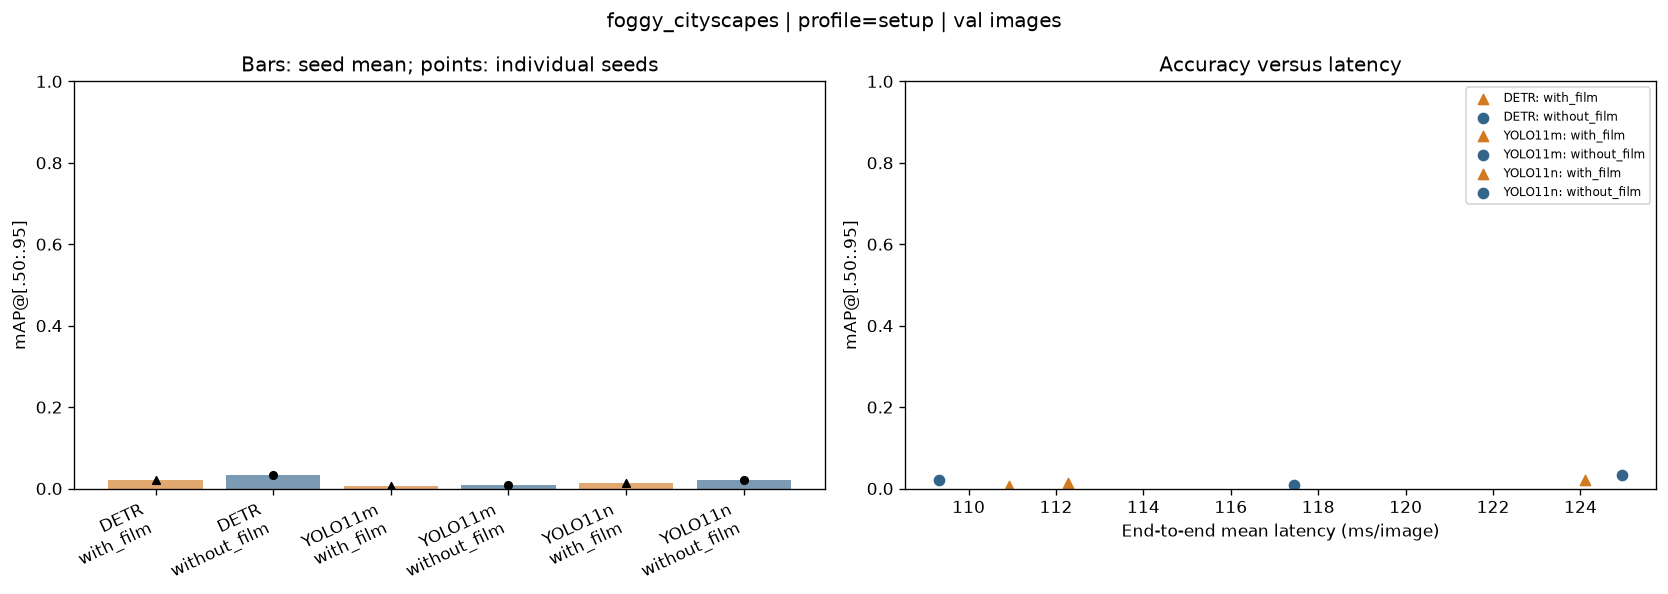

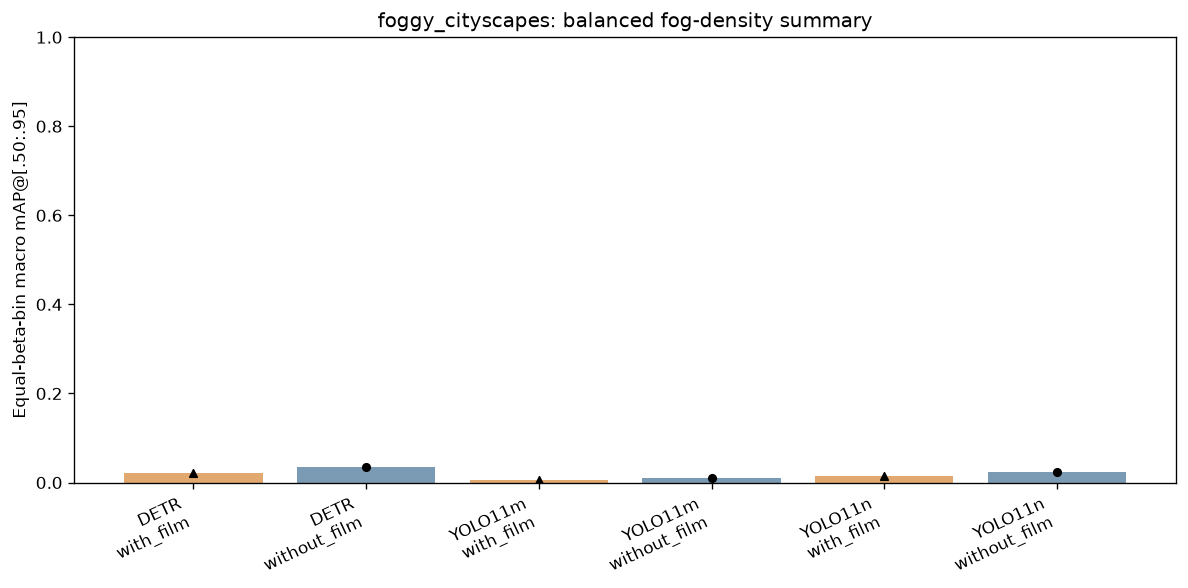

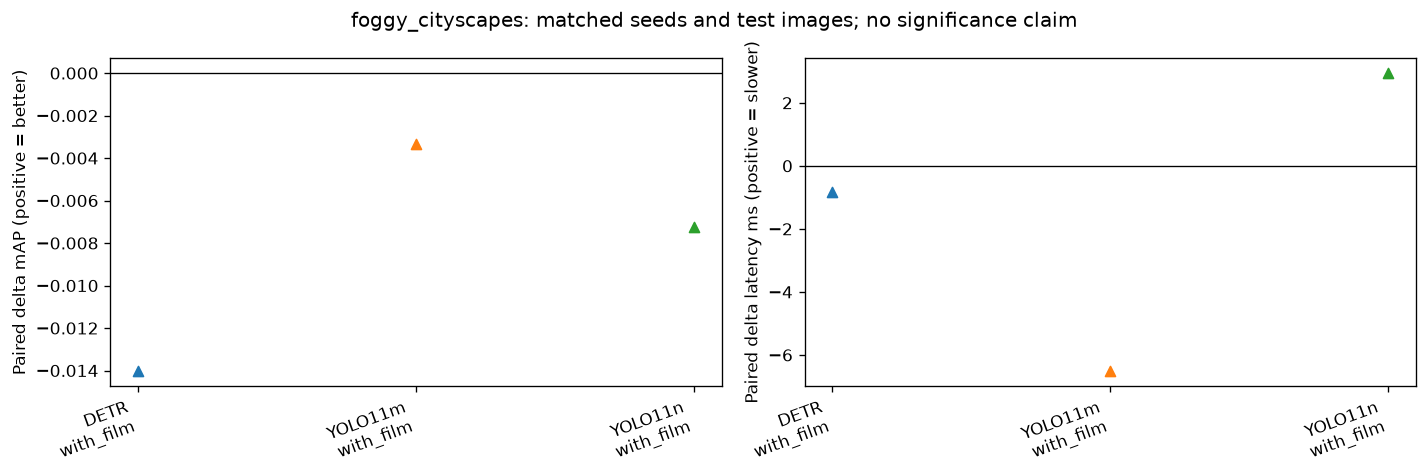

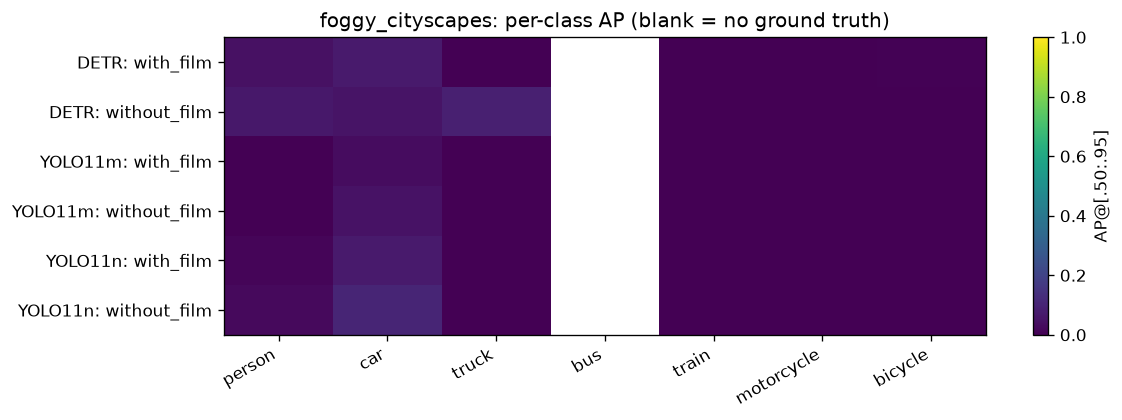

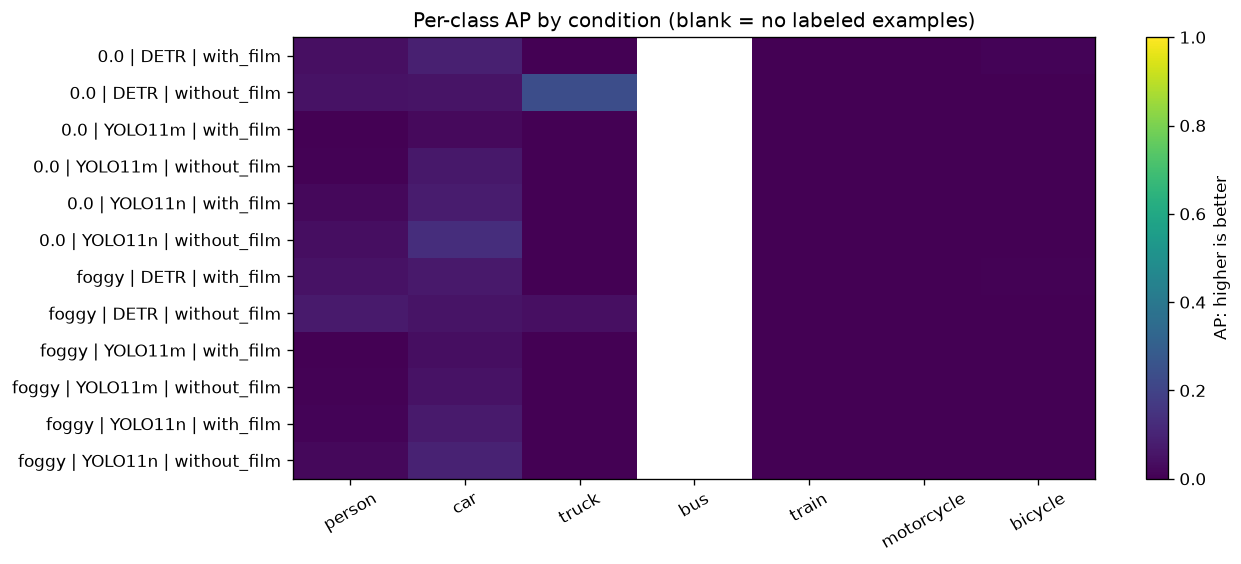

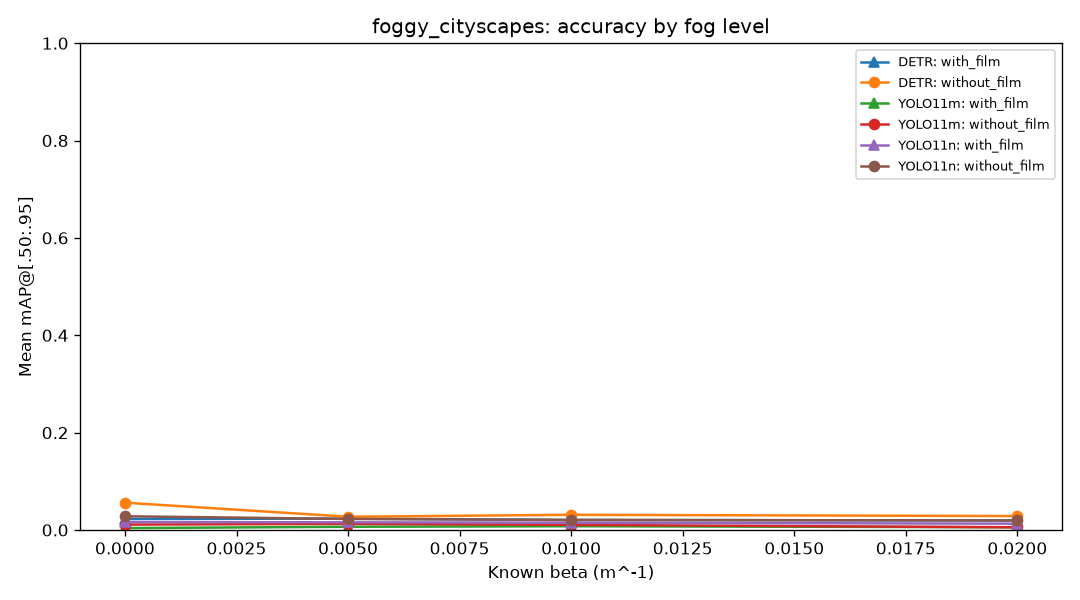

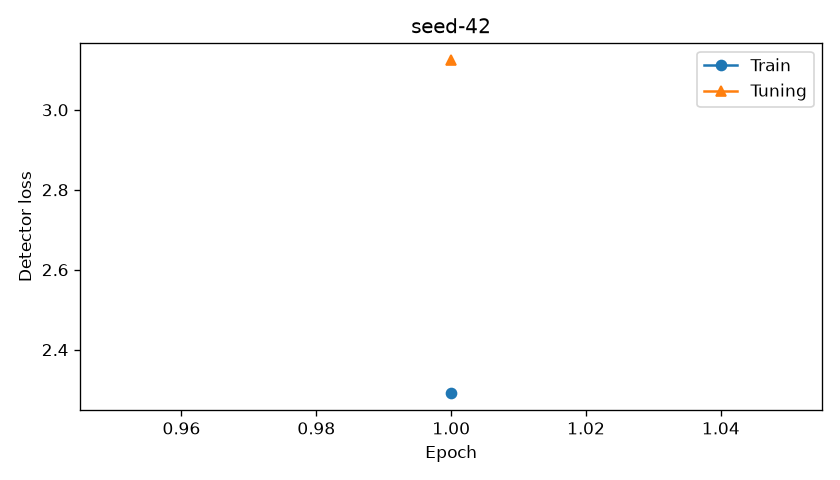

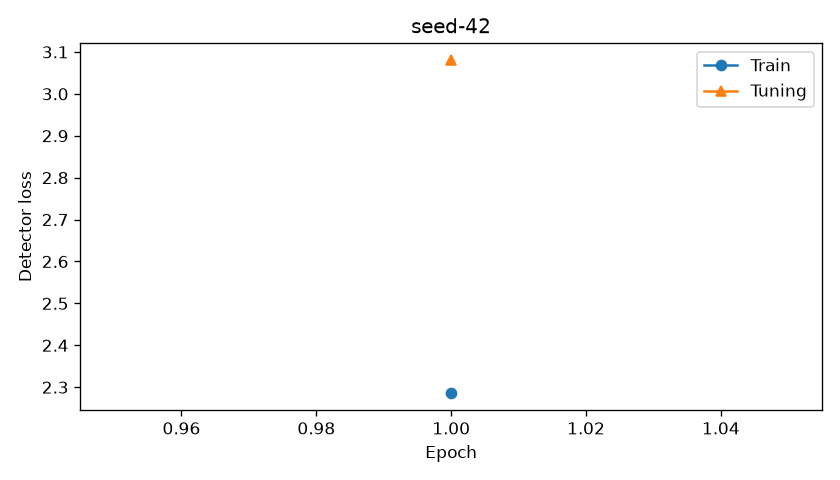

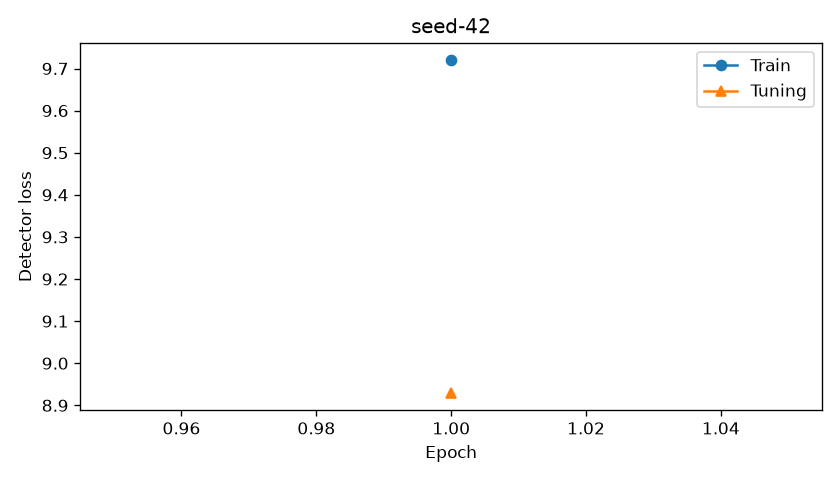

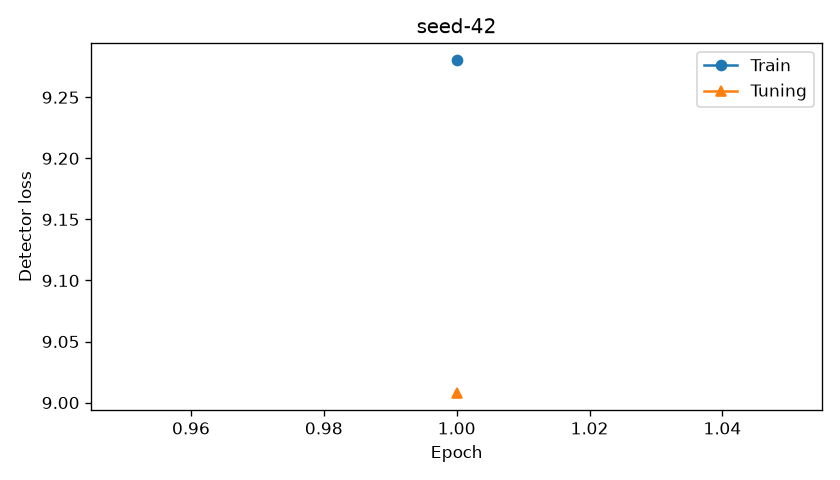

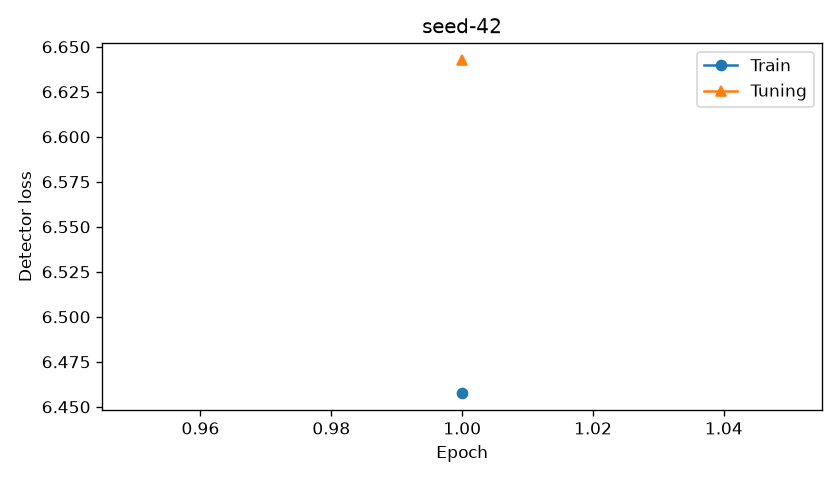

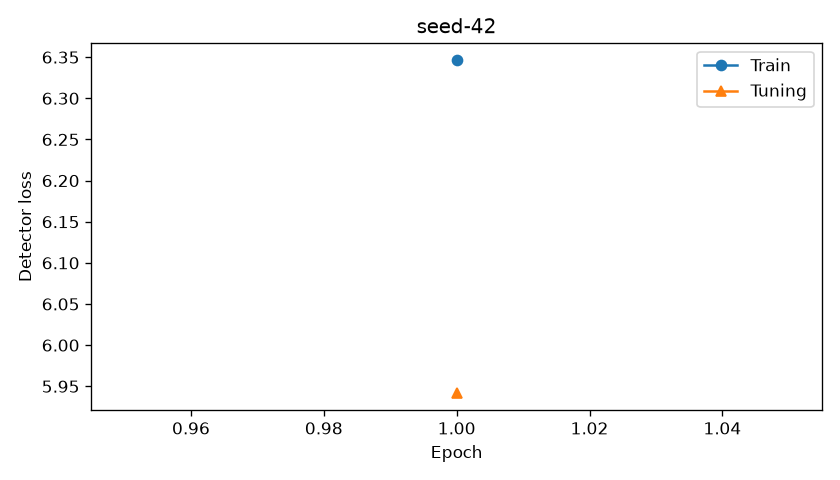

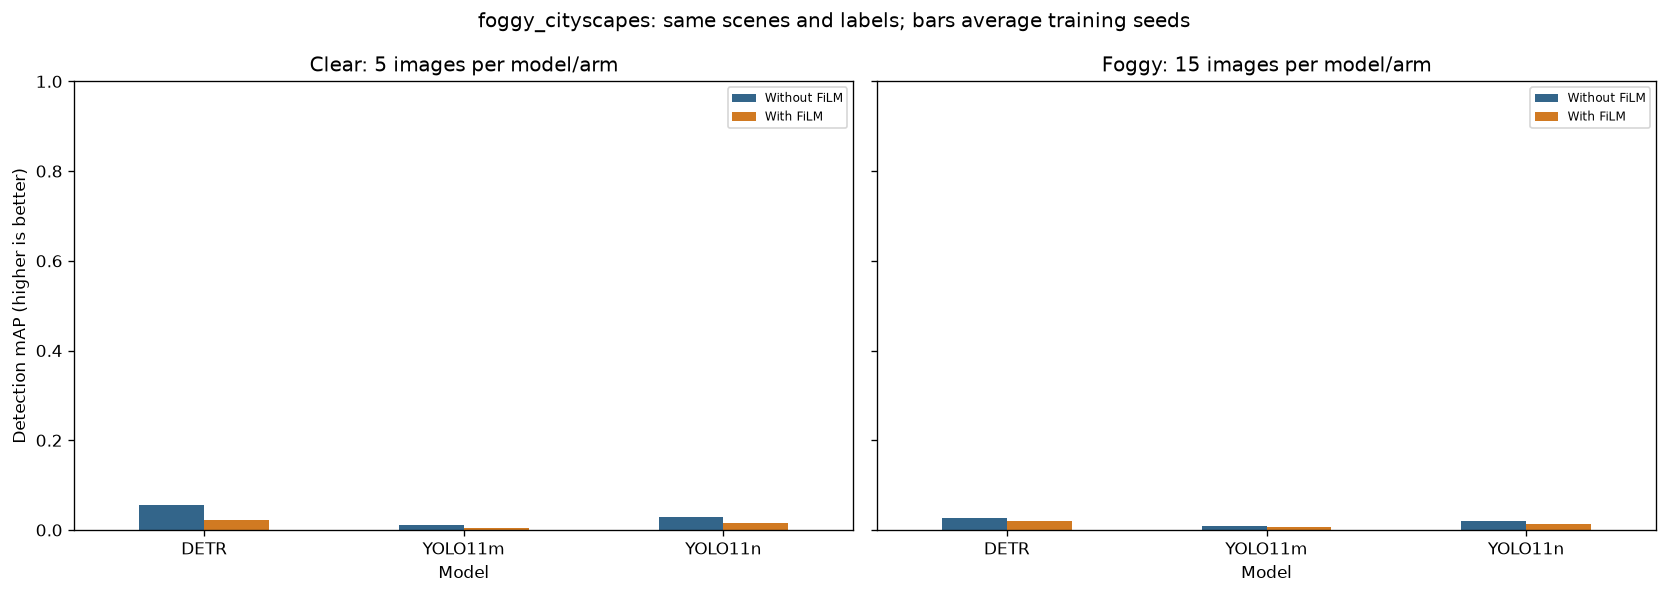

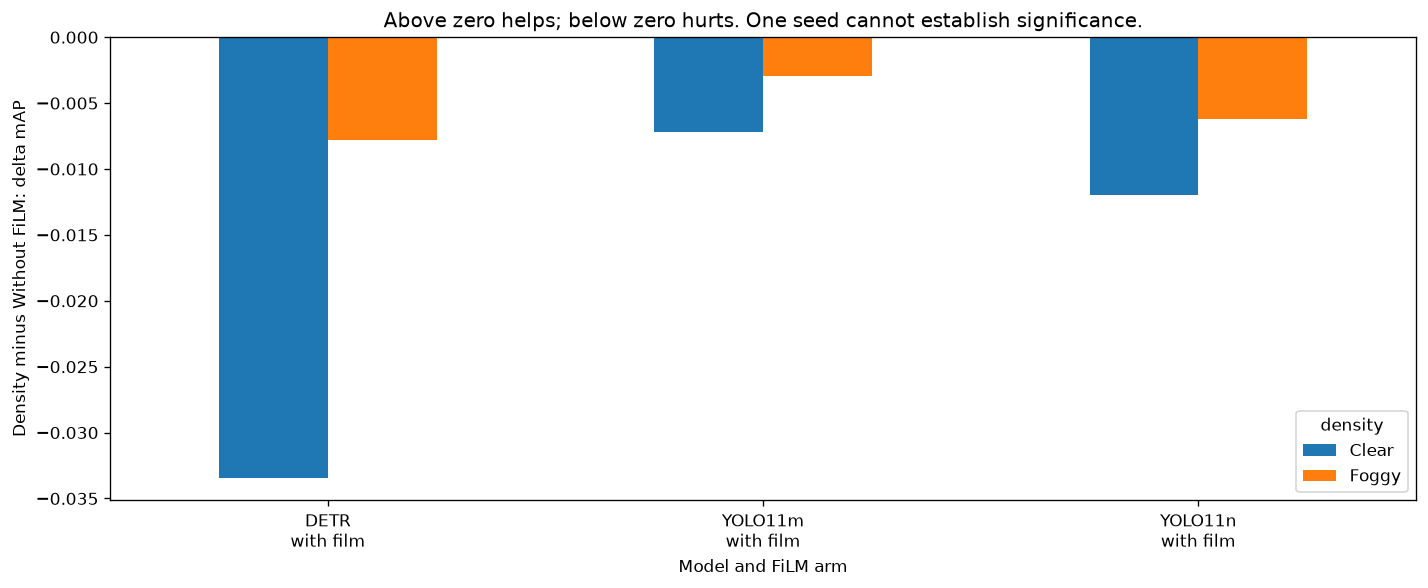

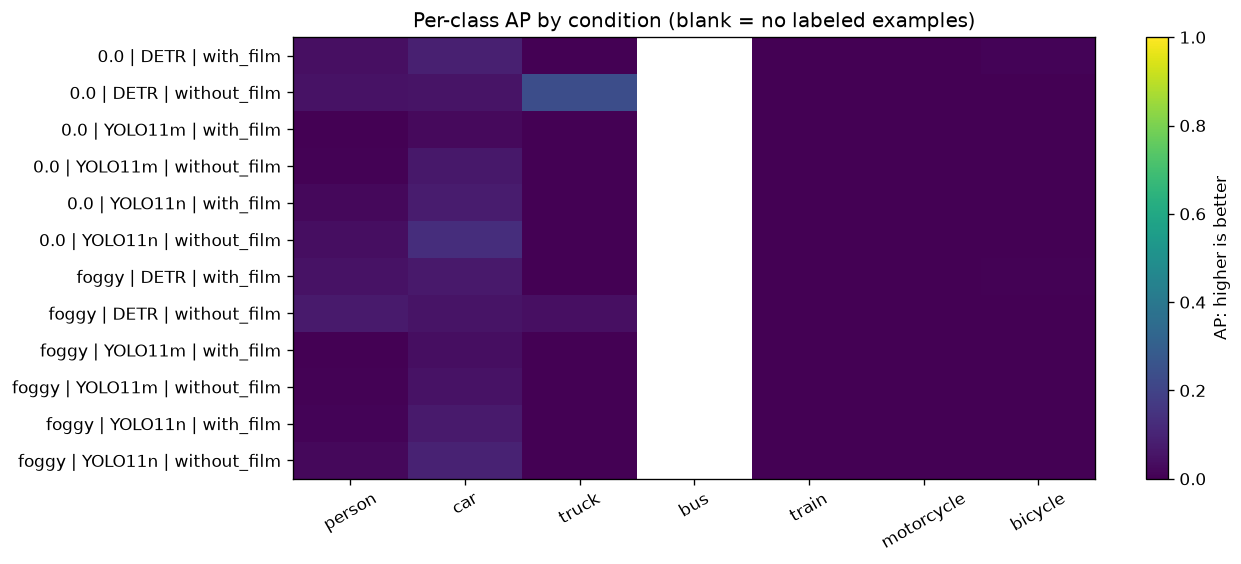

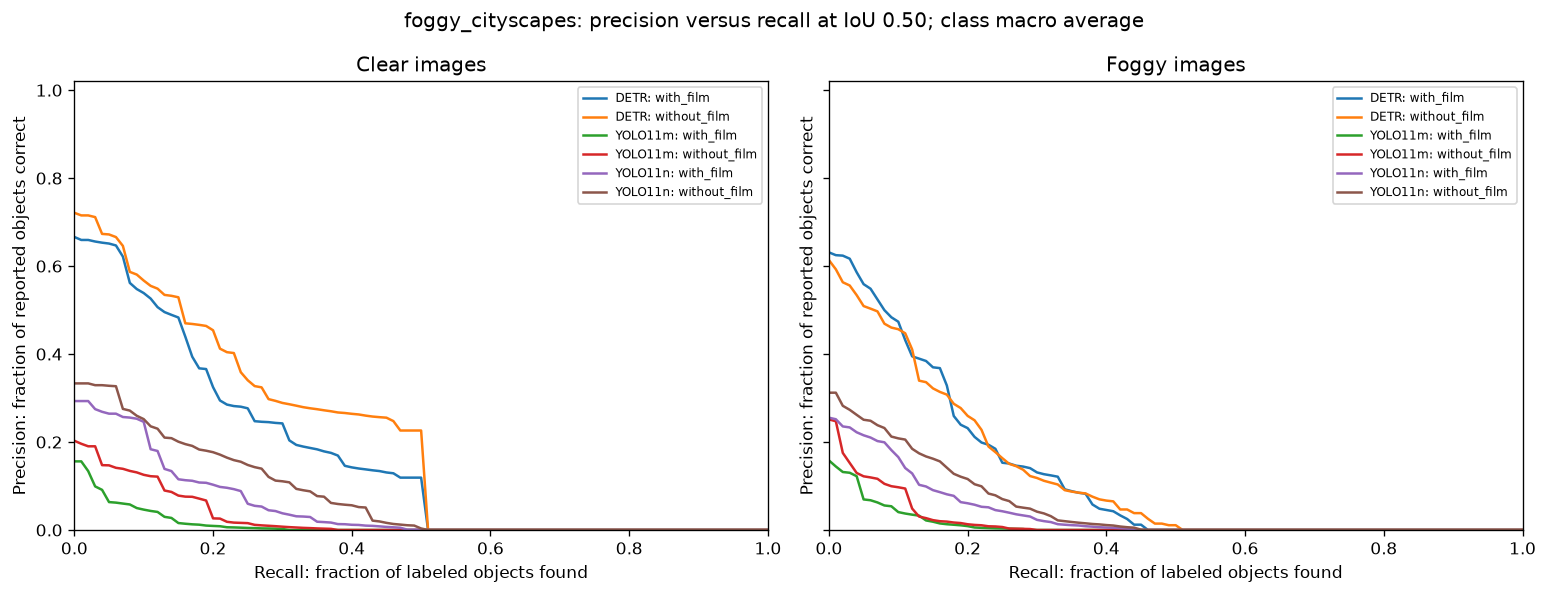

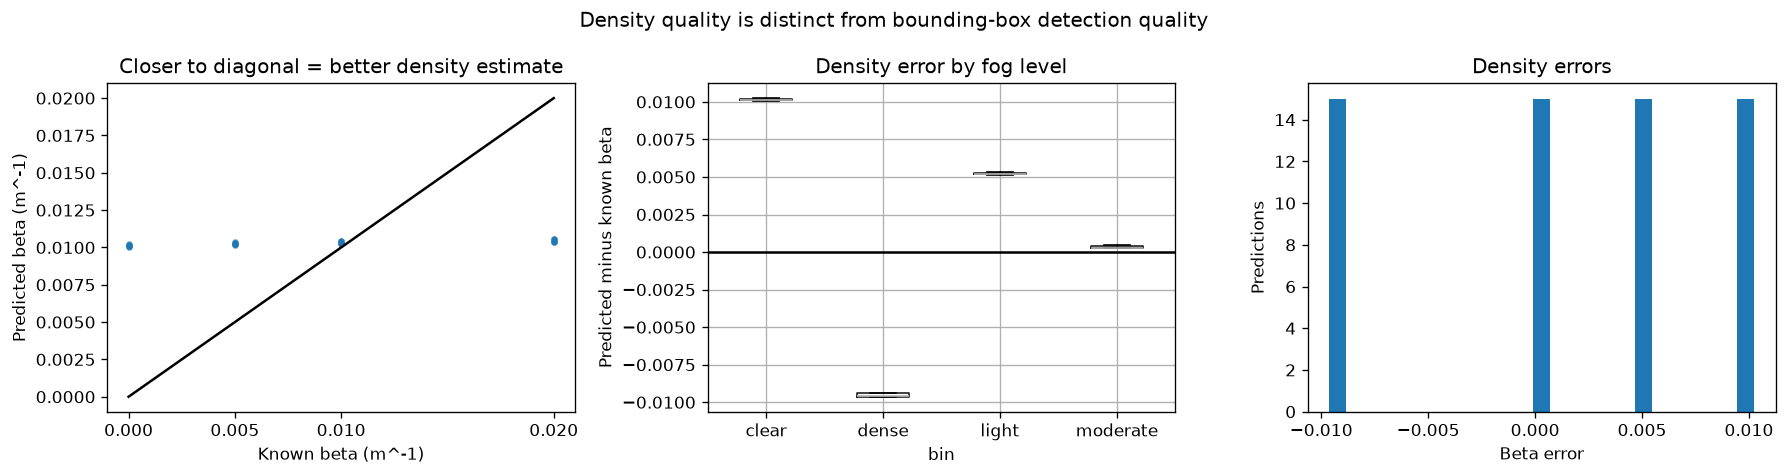

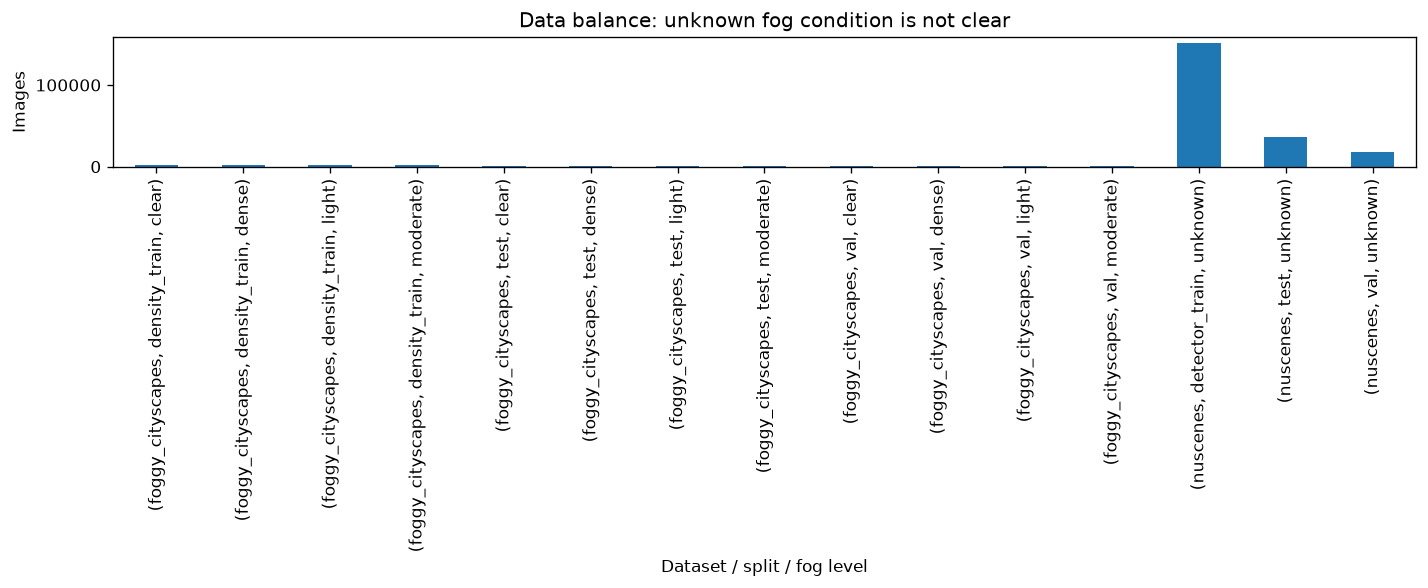

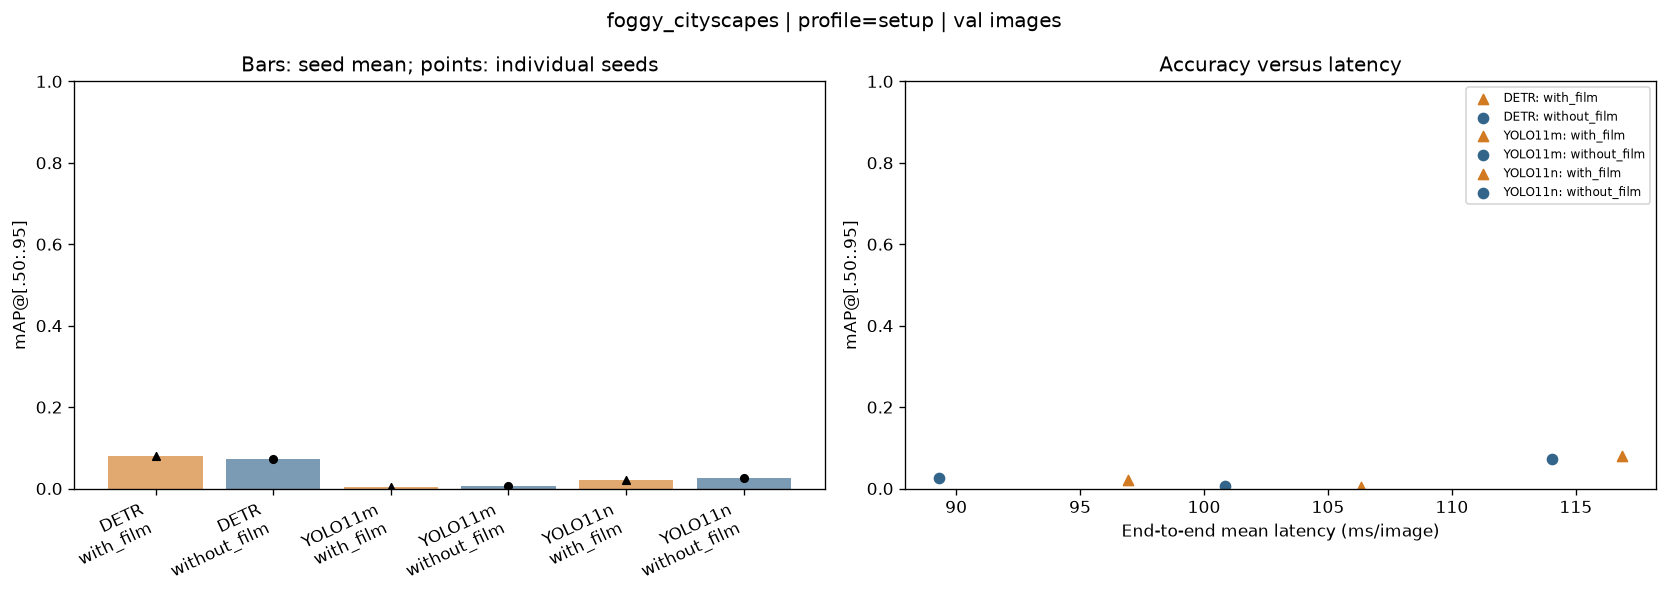

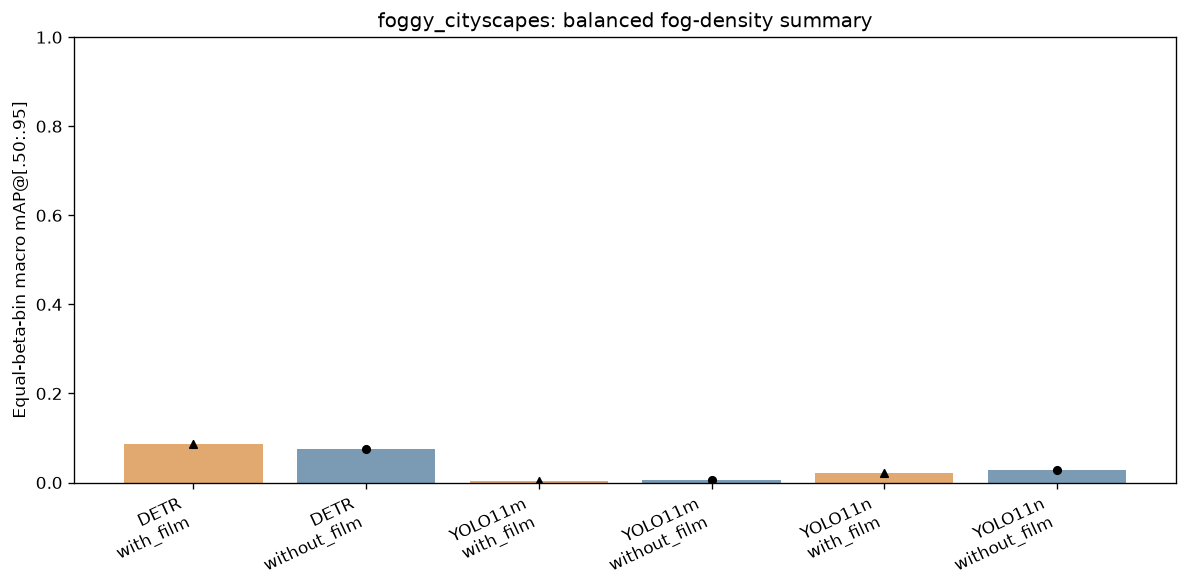

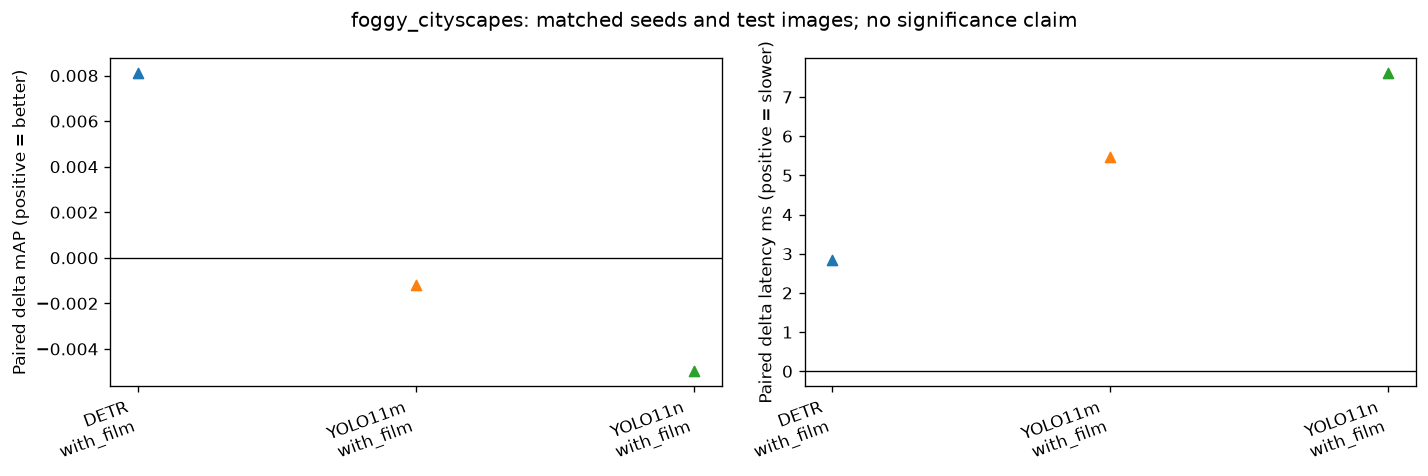

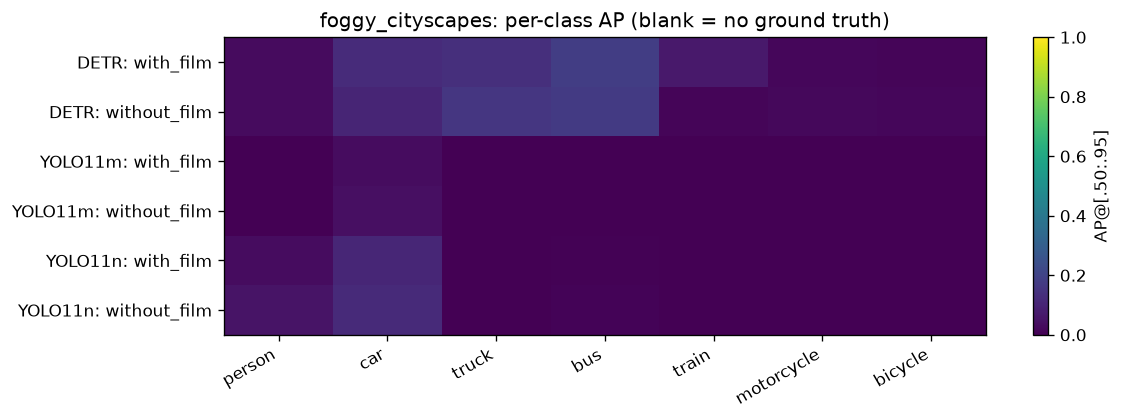

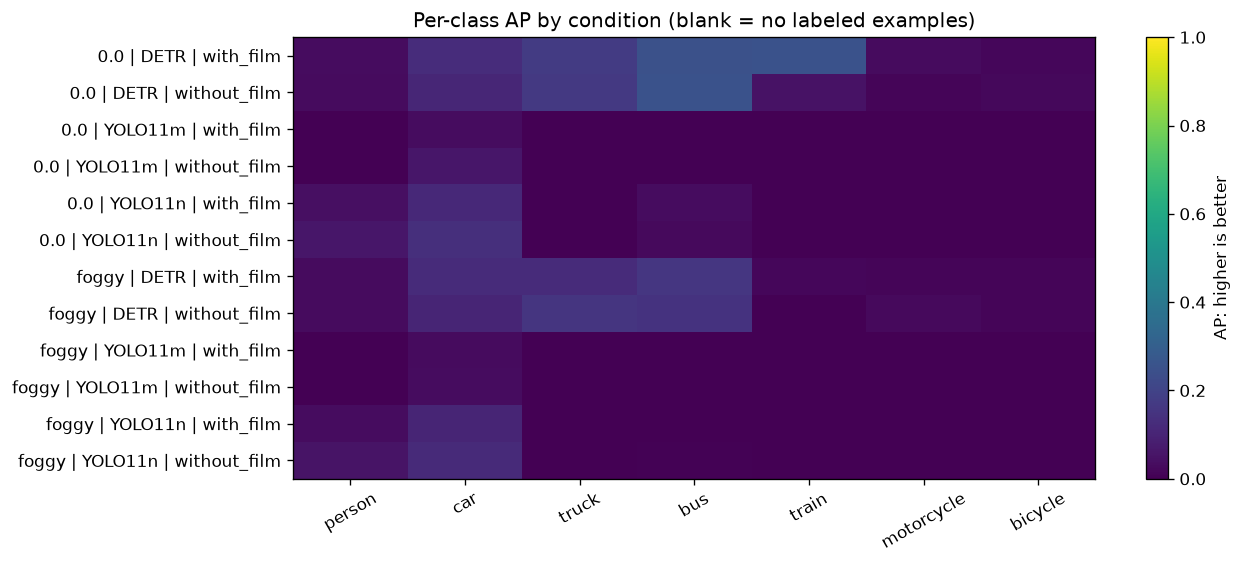

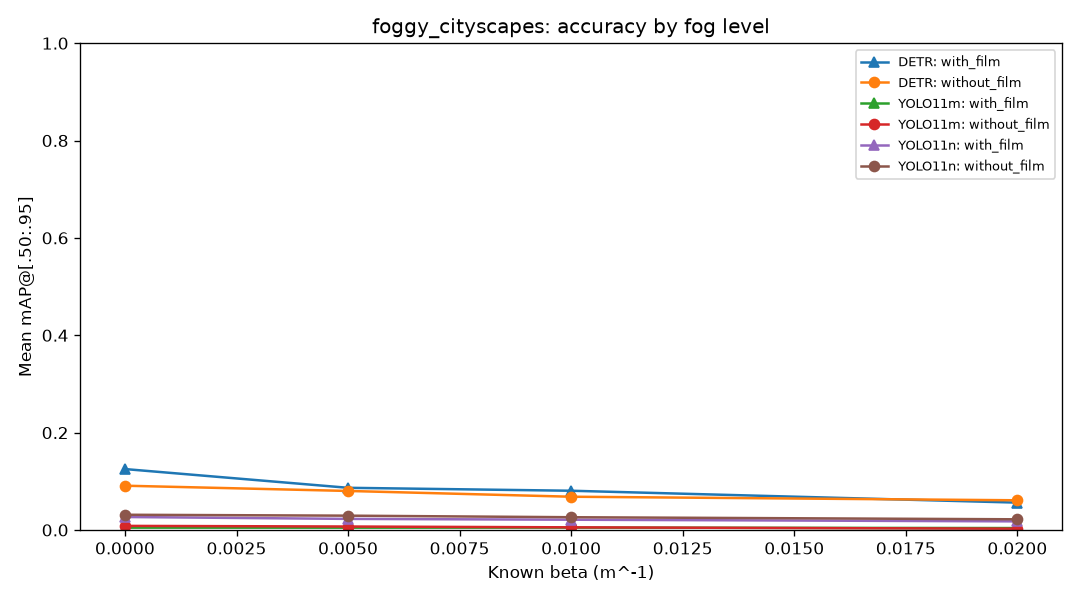

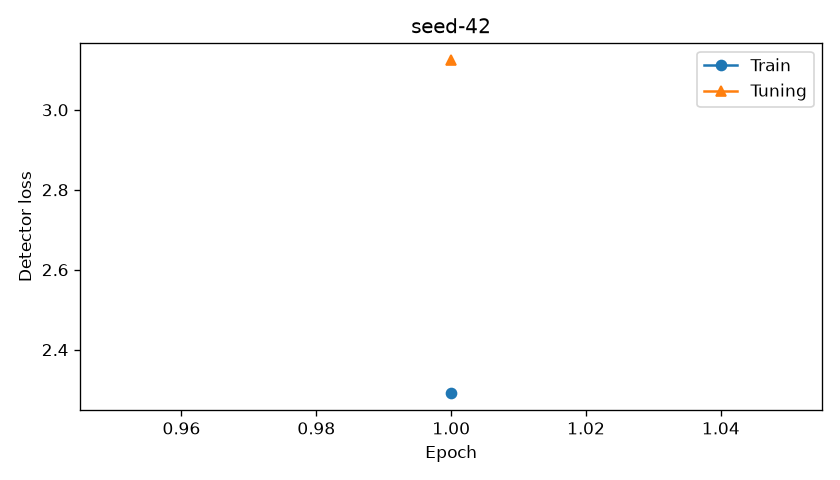

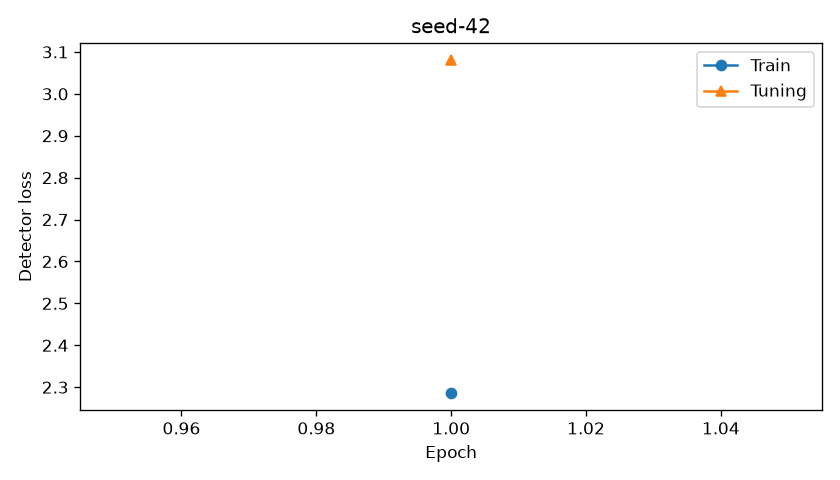

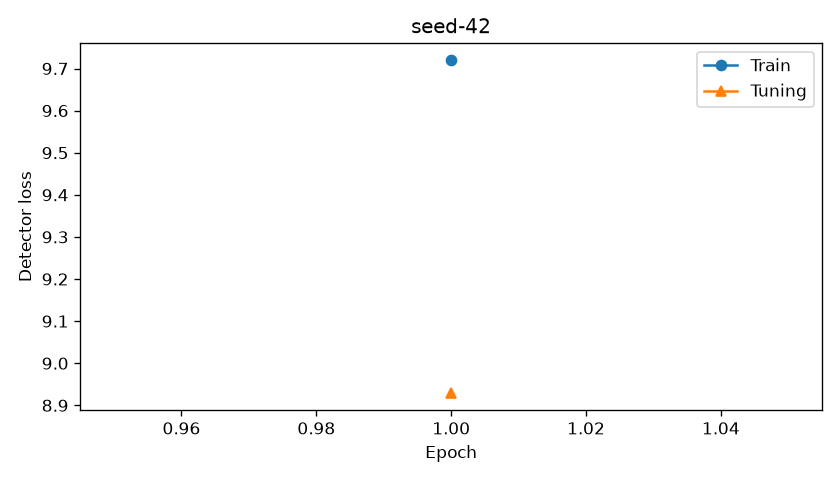

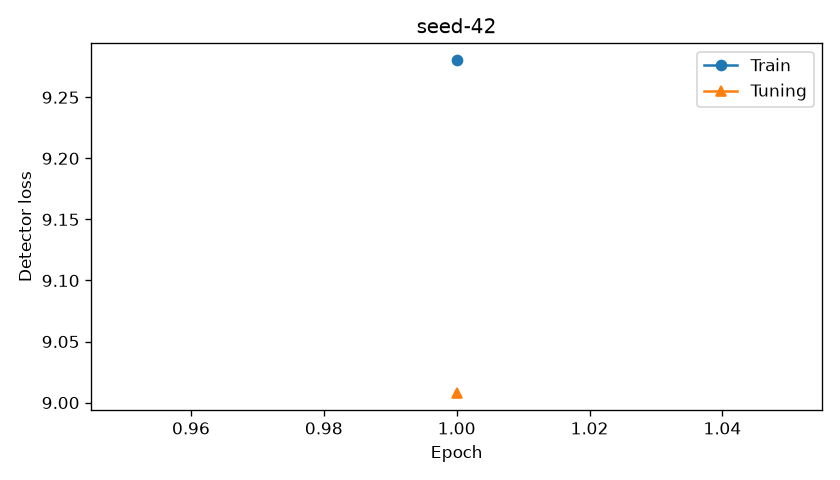

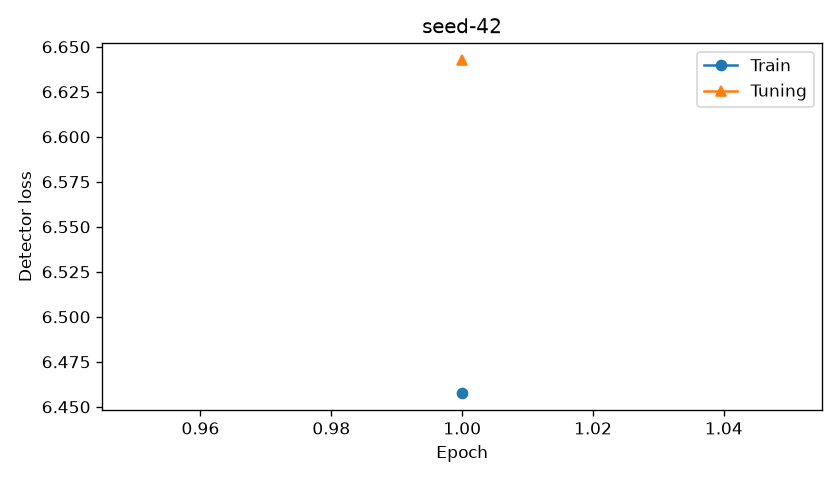

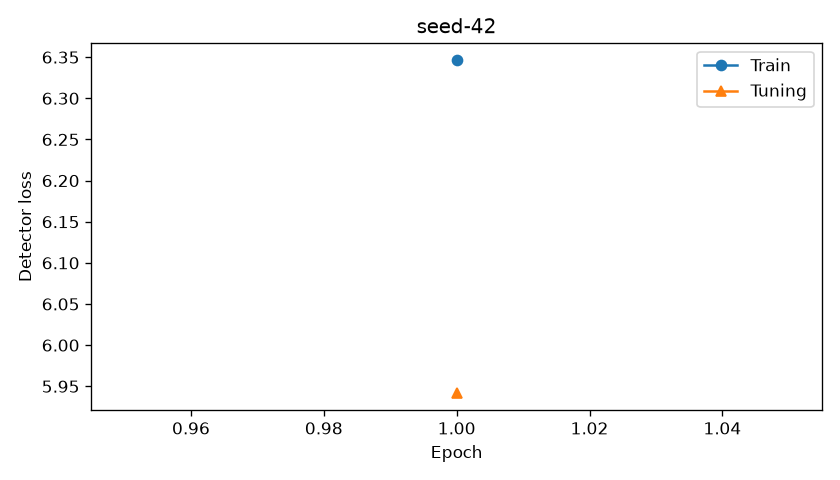

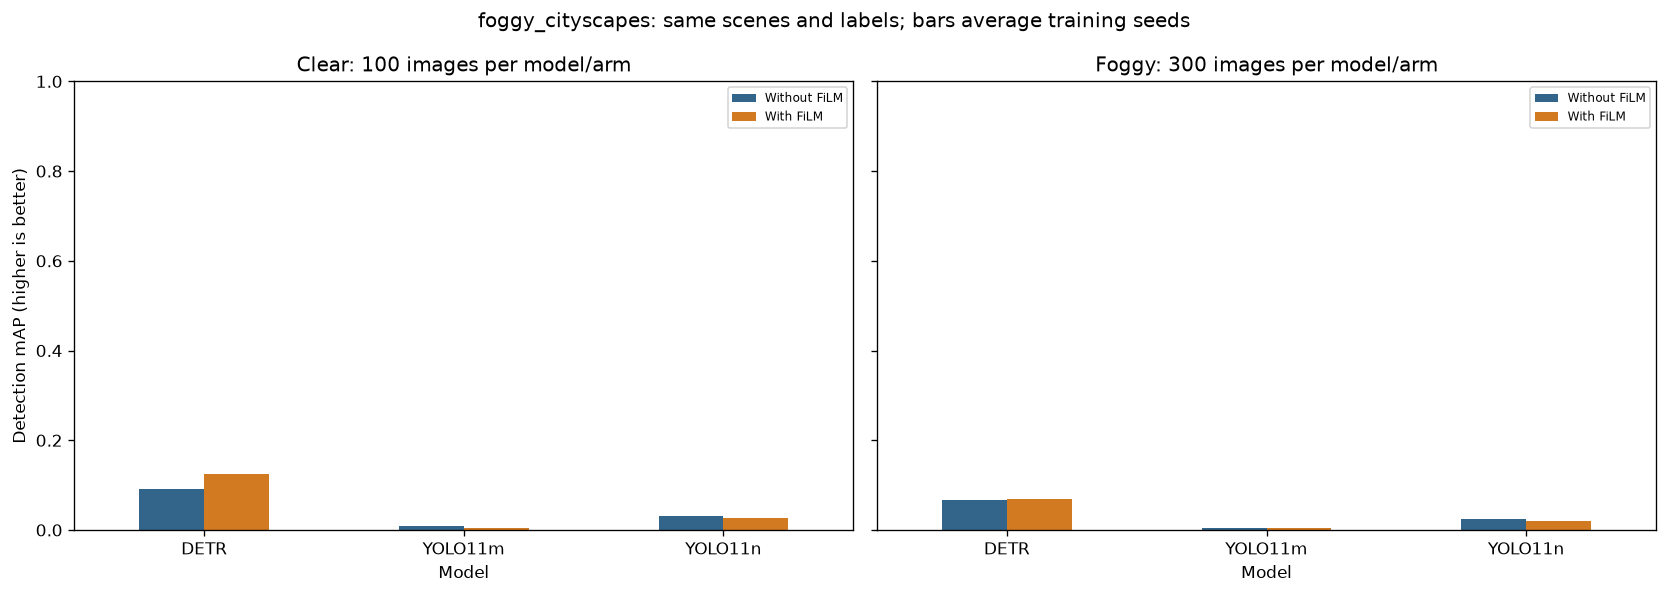

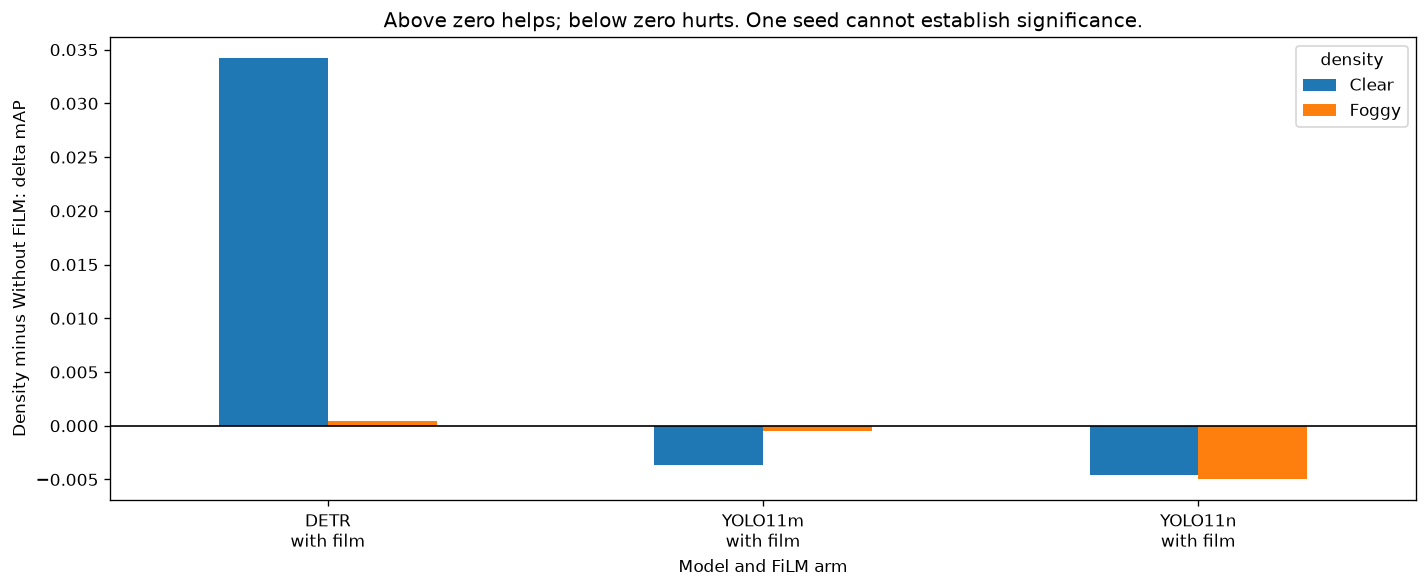

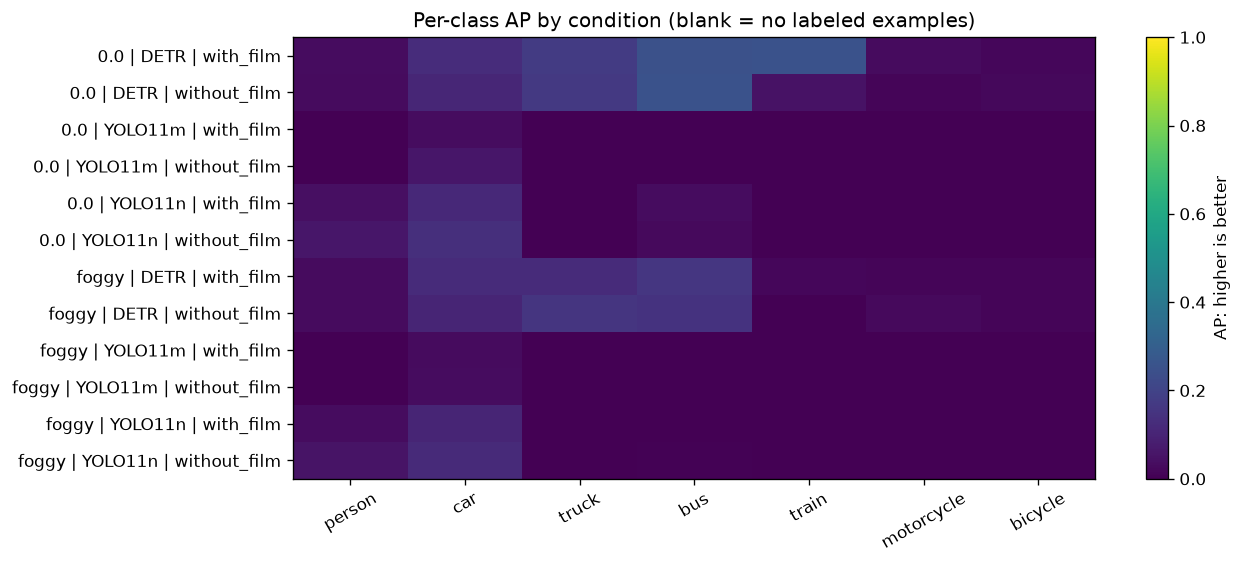

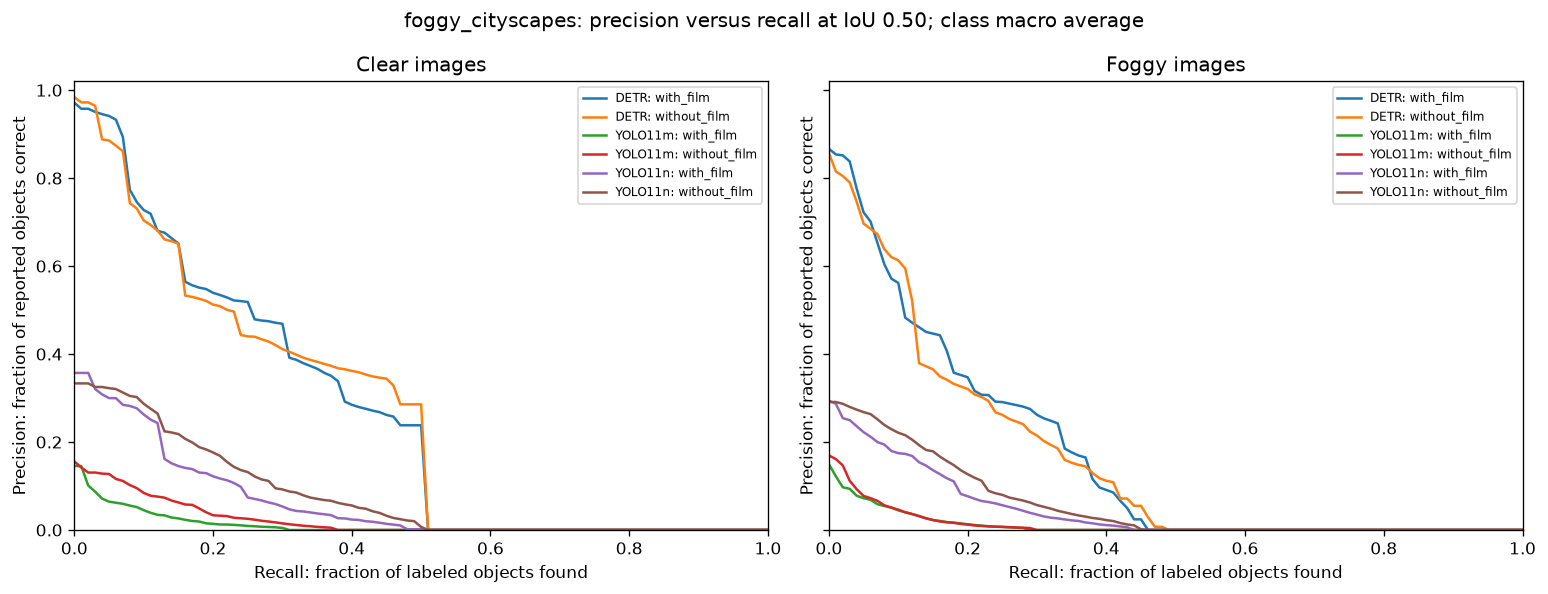

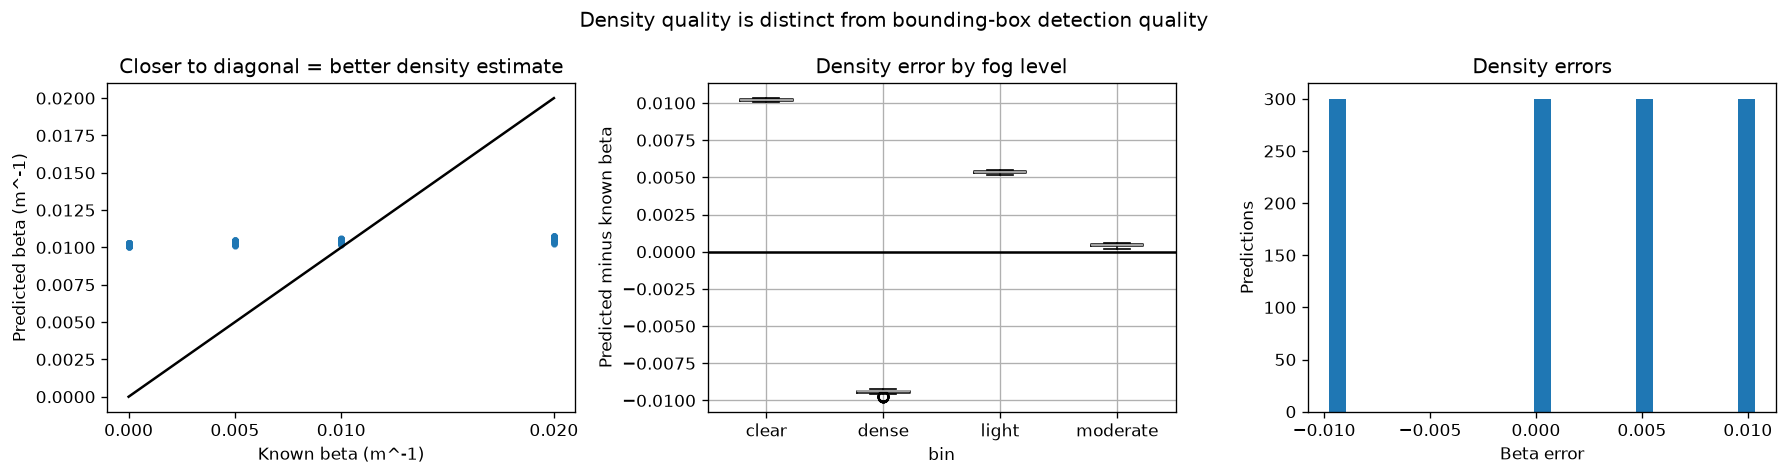

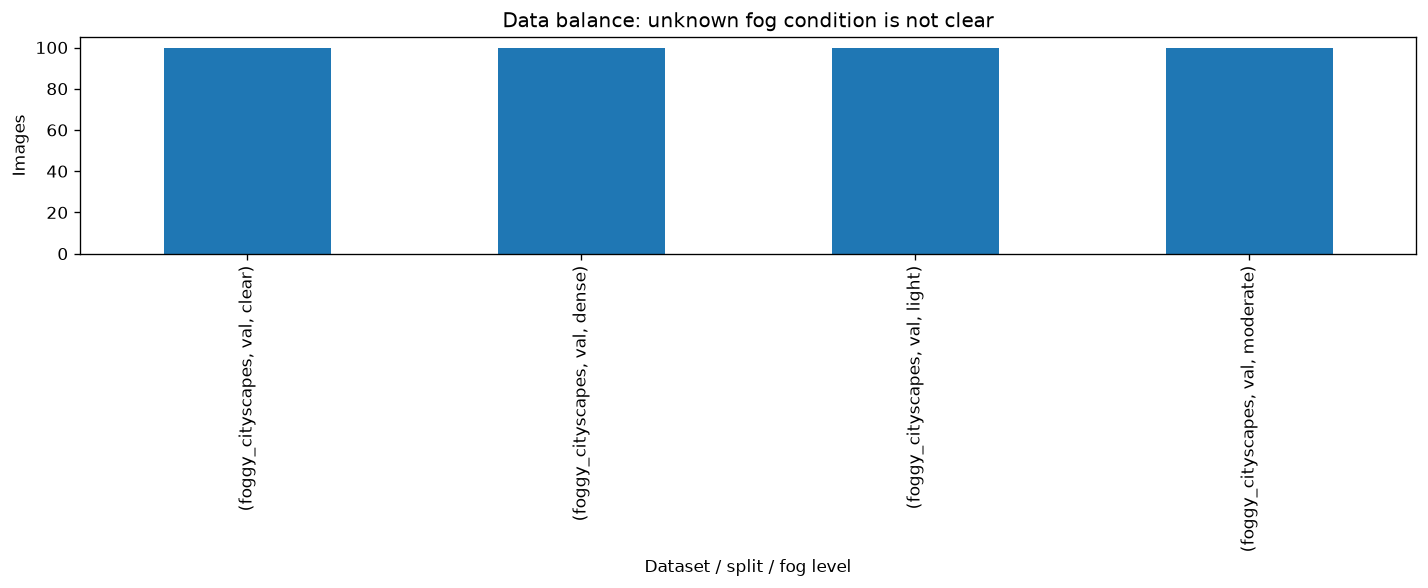

In [ ]:
display_saved_comparison_figures(TRAINING_CONFIGURATION["output"], analytics["results"])
display_saved_comparison_figures(
    Path(TRAINING_CONFIGURATION["output"]) / SETTINGS["evaluation"]["output_name"],
    fog_results["results"],
)


### Visual examples: clear and foggy detection

This grid uses the same clear and representative foggy image across YOLO11n, YOLO11m, and DETR, with and without FiLM. It displays predictions from the saved matched evaluation; boxes are shown at confidence 0.25 or higher. Run the matched evaluation above first. These examples are qualitative and do not replace the mAP and per-class metrics.

In [ ]:
# @title Show matched visual examples for every detector arm
draw_saved_detection_examples(
    labeled_clear_fog_data, SETTINGS, TRAINING_CONFIGURATION
)

### Subset completion and checkpoint reuse

## 7. Export the run

The ZIP is saved beside the run directory in the configured output location. It includes reports, checkpoints and the installed package versions.


In [ ]:
def export_checkpoints_and_reports():
    """Package the configured run and its recorded dependency versions."""
    if not RESOLVED_PATHS["run"].exists():
        raise FileNotFoundError(f"No run directory: {RESOLVED_PATHS['run']}")
    if RESOLVED_PATHS["packages"].exists():
        shutil.copy2(
            RESOLVED_PATHS["packages"],
            RESOLVED_PATHS["run"] / SETTINGS["output"]["packages_file"],
        )
    archive_path = shutil.make_archive(
        str(RESOLVED_PATHS["export"].with_suffix("")), "zip", str(RESOLVED_PATHS["run"])
    )

    return archive_path


archive_path = export_checkpoints_and_reports()
print("Saved:", archive_path)


Saved: C:\Users\tsao1\OneDrive\Documents\workspace\Ai Driving Assistance app\models\film\setup.zip


### Interpret the FiLM comparison

The no-FiLM arm fine-tunes the original detector directly. The FiLM arm conditions a detector feature map on beta from the same frozen density model. Both arms see the same clear and foggy training data. This tests the contribution of feature conditioning, rather than training on different weather datasets.

A positive FiLM delta means higher measured AP for those images. Inspect class support, clear/fog effects, fog level, and inference cost before interpreting the overall average. Known beta groups evaluation images; it is never substituted for the predicted beta used by FiLM. Checkpoint and export metadata record the FiLM architecture and run identity so incompatible saved runs are rejected.
